In [12]:
# ===================== STAGE 0  =====================
import os, sys, subprocess, importlib
for pkg in ["wfdb", "mne", "seaborn", "einops", "huggingface_hub"]:
    try: importlib.import_module(pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT, TMP = "/content/drive/MyDrive", "/content/tmp_raw"
else:
    ROOT, TMP = os.path.abspath("."), os.path.abspath("./tmp_raw")
DATA_BASE = os.path.join(ROOT, "QMLNet_v3")          # cached PSG data from earlier runs is reused from here
BASE = os.path.join(ROOT, "NocturNet")
DIRS = {"raw_ucd": os.path.join(DATA_BASE, "raw_ucd"), "proc_c18": os.path.join(DATA_BASE, "proc_c18"),
        "proc_ucd": os.path.join(DATA_BASE, "proc_ucd"), "dres": os.path.join(DATA_BASE, "results"),
        **{k: os.path.join(BASE, k) for k in ["fm", "checkpoints", "figures", "results", "flags"]}}
for d in list(DIRS.values()) + [TMP]: os.makedirs(d, exist_ok=True)
print("Data cache:", DATA_BASE, "\nOutputs:", BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data cache: /content/drive/MyDrive/QMLNet_v3 
Outputs: /content/drive/MyDrive/NocturNet


In [17]:
import json, time, glob, re, math, random, warnings, shutil, datetime, urllib.request, hashlib
from fractions import Fraction
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.patches import FancyBboxPatch, Patch
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import signal as sps, stats, io as sio
import wfdb
warnings.filterwarnings("ignore")

CFG = dict(
    seed=42, version="v5", seeds=[42, 43, 44],
    n_challenge=200, split=(0.70, 0.10, 0.20), dl_workers=4,
    fs_fast=64, fs_slow=16, epoch_sec=30, min_overlap=5,
    classes=["Normal", "Hypopnea", "Obstructive", "Central"],
    fast_mods=["ECG", "EEG"], slow_mods=["Airflow", "Thorax", "Abdomen", "SpO2"],
    seq_len=64, seq_stride=32, batch_seq=8, steps_per_epoch=400, epochs=25, patience=6,
    lr=1e-3, wd=1e-4, d_model=128, focal_gamma=2.0, aux_weight=0.3, ema=0.995, mod_dropout=0.15,
    osf_repo="https://github.com/yang-ai-lab/OSF-Open-Sleep-FM", osf_hf="yang-ai-lab/OSF-Base", osf_batch=256,
    n_boot=500, tsne_n=4000,
)
MODS = CFG["fast_mods"] + CFG["slow_mods"]; NF, NS = len(CFG["fast_mods"]), len(CFG["slow_mods"])
LF, LS = CFG["fs_fast"] * CFG["epoch_sec"], CFG["fs_slow"] * CFG["epoch_sec"]
STAGE_NAMES = ["W", "N1", "N2", "N3", "R"]

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["seed"])
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu"); AMP = DEV.type == "cuda"
torch.backends.cudnn.benchmark = True

PAL = {"Normal": "#009E73", "Hypopnea": "#E69F00", "Obstructive": "#D55E00", "Central": "#0072B2"}   # Okabe-Ito
CCOL = [PAL[c] for c in CFG["classes"]]
MPAL = dict(zip(MODS, ["#D55E00", "#0072B2", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]))
DBPAL = {"Challenge-2018": "#0072B2", "UCDDB": "#D55E00", "SLPDB": "#009E73"}
PROPOSED = "NocturNet"
NSV = "NocturNet-S (+ staging head)"      # same model + auxiliary sleep-staging head; used for the fully automatic AHI
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.titleweight": "bold", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12, "axes.labelsize": 10, "font.weight": "bold", "axes.labelweight": "bold",
                     "legend.frameon": False, "axes.edgecolor": "#b9b6ae", "grid.color": "#e6e4df"})

def savefig(fig, name):
    for ext in ("png", "pdf"): fig.savefig(os.path.join(DIRS["figures"], f"{name}.{ext}"), bbox_inches="tight")
    plt.show()
def set_flag(n): open(os.path.join(DIRS["flags"], n + ".done"), "w").write(time.ctime())
def jdump(o, p):
    with open(p + ".tmp", "w") as f: json.dump(o, f, indent=2, default=float)
    os.replace(p + ".tmp", p)
def jload(p):
    with open(p) as f: return json.load(f)
def fetch(urls, dst):
    if os.path.exists(dst) and os.path.getsize(dst) > 0: return dst
    err = None
    for u in urls:
        try:
            urllib.request.urlretrieve(u, dst + ".part"); os.replace(dst + ".part", dst); return dst
        except Exception as e: err = e
    raise RuntimeError(f"download failed {dst}: {err}")

print("Device:", DEV, "| AMP:", AMP, "| done stages:", sorted(f[:-5] for f in os.listdir(DIRS["flags"])))

Device: cuda | AMP: True | done stages: ['final_archive', 'stage10_comparators', 'stage11_eval', 'stage12_comparison', 'stage12b_seeds', 'stage12c_robustness', 'stage13_ahi', 'stage13b_waveforms', 'stage14_explain', 'stage15_summary', 'stage16_auto_ahi', 'stage17_literature', 'stage18_slpdb', 'stage18b_slpdb_secondary', 'stage19b_external_audit', 'stage20_extra', 'stage20_nocturnet_dg', 'stage2_data', 'stage3_split', 'stage4_eda', 'stage5_osf', 'stage9_nocturnet']


In [18]:
# ===================== STAGE 1  =====================
EV_MAP = {"resp_hypopnea": 1, "resp_obstructiveapnea": 2, "resp_mixedapnea": 2, "resp_centralapnea": 3,
          "HYP": 1, "APNEA-O": 2, "APNEA-M": 2, "APNEA-C": 3}
UCD_STAGE = {0: "W", 1: "R", 2: "N1", 3: "N2", 4: "N3", 5: "N3", 6: "U", 7: "U"}
ALIASES = {"ECG": ["ecg", "ekg"], "EEG": ["c4-m1", "c4a1", "c4-a1", "c3-m2", "c3a2", "c3-a2", "eeg"],
           "Airflow": ["airflow", "flow"], "Thorax": ["chest", "rib", "thor"], "Abdomen": ["abd"],
           "SpO2": ["sao2", "spo2", "sat"]}

def pick(names, mod):
    low = [n.lower().replace(" ", "") for n in names]
    for a in ALIASES[mod]:
        for i, n in enumerate(low):
            if a in n: return i
    return None

def resample(x, fs, tgt):
    fr = Fraction(tgt, int(round(fs))).limit_denominator(1000)
    return sps.resample_poly(x, fr.numerator, fr.denominator)

def clean(x, fs, mod):
    x = np.nan_to_num(np.asarray(x, np.float64))
    if mod == "SpO2":
        bad = (x < 50) | (x > 100)
        if (~bad).mean() > .5 and bad.any():
            idx = np.arange(len(x)); x[bad] = np.interp(idx[bad], idx[~bad], x[~bad])
    tgt = CFG["fs_fast"] if mod in CFG["fast_mods"] else CFG["fs_slow"]
    x = resample(x, fs, tgt)
    band = {"ECG": (0.5, 25), "EEG": (0.5, 25), "Airflow": (0.05, 3), "Thorax": (0.05, 3), "Abdomen": (0.05, 3), "SpO2": (None, 1)}[mod]
    sos = sps.butter(3, band[1], "lowpass", fs=tgt, output="sos") if band[0] is None else sps.butter(3, band, "bandpass", fs=tgt, output="sos")
    x = sps.sosfiltfilt(sos, x)
    med = np.median(x); iqr = np.subtract(*np.percentile(x, [75, 25])) + 1e-6
    return np.clip((x - med) / iqr, -20, 20).astype(np.float32)

def build_epochs(sig, fs, names, events, stages, n_ep_hint=None):
    """sig: (C, N) raw; events: list of (start_s, dur_s, cls); stages: list per 30-s epoch."""
    dur = sig.shape[1] / fs; n = int(dur // CFG["epoch_sec"])
    if n_ep_hint: n = min(n, n_ep_hint)
    XF = np.zeros((n, NF, LF), np.float16); XS = np.zeros((n, NS, LS), np.float16); mask = np.zeros(len(MODS), np.int8)
    for j, m in enumerate(MODS):
        k = pick(names, m)
        if k is None: continue
        c = clean(sig[k], fs, m); L = LF if j < NF else LS
        c = c[:n * L] if len(c) >= n * L else np.pad(c, (0, n * L - len(c)))
        (XF[:, j] if j < NF else XS[:, j - NF])[:] = c.reshape(n, L)
        mask[j] = 1
    ov = np.zeros((n, 4))
    for s, d, c in events:
        a, b = s, s + d
        for e in range(max(0, int(a // 30)), min(n, int(b // 30) + 1)):
            ov[e, c] += max(0, min(b, (e + 1) * 30) - max(a, e * 30))
    y = np.where(ov[:, 1:].max(1) >= CFG["min_overlap"], ov[:, 1:].argmax(1) + 1, 0)
    st = np.array((list(stages) + ["U"] * n)[:n])
    sleep_h = max((np.isin(st, ["N1", "N2", "N3", "R"])).sum() * 30 / 3600, 1e-3)
    n_ev = np.bincount([c for s, d, c in events if s < n * 30], minlength=4)
    return dict(XF=XF, XS=XS, mask=mask, y=y.astype(np.int8), stage=st, ahi=n_ev[1:].sum() / sleep_h,
                n_events=n_ev, sleep_h=sleep_h)

def parse_c18(path):
    h = wfdb.rdheader(path)
    raw = sio.loadmat(path + ".mat")["val"].astype(np.float32)
    raw = (raw - np.array(h.baseline)[:, None]) / np.array(h.adc_gain)[:, None]
    ann = wfdb.rdann(path, "arousal"); fs = h.fs
    events, open_ = [], {}; stage_pts = []
    for smp, aux in zip(ann.sample, ann.aux_note):
        aux = (aux or "").strip()
        if aux.startswith("("): open_[aux[1:]] = smp
        elif aux.endswith(")"):
            nm = aux[:-1]; s0 = open_.pop(nm, None)
            if s0 is not None and nm in EV_MAP: events.append((s0 / fs, (smp - s0) / fs, EV_MAP[nm]))
        elif aux in ("W", "N1", "N2", "N3", "R", "undefined"): stage_pts.append((smp / fs, "U" if aux == "undefined" else aux))
    n = int(raw.shape[1] / fs // 30); stages = ["U"] * n; k = 0
    for e in range(n):
        while k + 1 < len(stage_pts) and stage_pts[k + 1][0] <= e * 30 + 1: k += 1
        if stage_pts and stage_pts[k][0] <= e * 30 + 1: stages[e] = stage_pts[k][1]
    return build_epochs(raw, fs, h.sig_name, events, stages)

def parse_ucd(rec):
    import mne
    src = os.path.join(DIRS["raw_ucd"], rec + ".rec"); tmp = os.path.join(TMP, rec + ".edf")
    if not os.path.exists(tmp): shutil.copy(src, tmp)
    raw = mne.io.read_raw_edf(tmp, preload=True, verbose="ERROR")
    fs, sig = raw.info["sfreq"], raw.get_data()
    with open(src, "rb") as f: hdr = f.read(256).decode("latin-1")
    hh, mm, ss = [int(v) for v in re.split(r"[.:]", hdr[176:184].strip())[:3]]; t0s = hh * 3600 + mm * 60 + ss
    events = []
    for line in open(os.path.join(DIRS["raw_ucd"], rec + "_respevt.txt"), errors="ignore"):
        p = line.split()
        if len(p) < 3 or not re.match(r"^\d{1,2}:\d\d:\d\d$", p[0]): continue
        typ = p[1].upper(); key = "HYP" if typ.startswith("HYP") else typ
        if key not in EV_MAP: continue
        rest = p[2:]; rest = rest[1:] if rest and rest[0] in ("PB", "CS") else rest
        try: d = float(rest[0])
        except (ValueError, IndexError): continue
        hh, mm, ss = map(int, p[0].split(":")); s = (hh * 3600 + mm * 60 + ss - t0s) % 86400
        events.append((s, d, EV_MAP[key]))
    st = [UCD_STAGE.get(int(v), "U") for v in open(os.path.join(DIRS["raw_ucd"], rec + "_stage.txt")).read().split() if v.strip().isdigit()]
    out = build_epochs(sig, fs, raw.ch_names, events, st); os.remove(tmp); return out

def save_proc(d, path): np.savez_compressed(path + ".tmp.npz", **d); os.replace(path + ".tmp.npz", path)

In [19]:
# ===================== STAGE 2  =====================
S3 = "https://physionet-open.s3.amazonaws.com/{db}/1.0.0/{p}"; PN = "https://physionet.org/files/{db}/1.0.0/{p}"
def urls(db, p): return [S3.format(db=db, p=p), PN.format(db=db, p=p)]

ucd_list_p = os.path.join(DIRS["proc_ucd"], "records.json")
if not os.path.exists(ucd_list_p):
    txt = fetch(urls("ucddb", "RECORDS"), os.path.join(TMP, "ucd_RECORDS"))
    jdump([l.strip() for l in open(txt) if l.strip()], ucd_list_p)
UCD_RECS = sorted({re.sub(r"(_lifecard)?\.(rec|edf)$", "", r) for r in jload(ucd_list_p) if r.startswith("ucddb")})
print("UCDDB subjects:", len(UCD_RECS))
def do_ucd(r):
    out = os.path.join(DIRS["proc_ucd"], r + ".npz")
    if os.path.exists(out): return r, "cached"
    for sfx in [".rec", "_respevt.txt", "_stage.txt"]: fetch(urls("ucddb", r + sfx), os.path.join(DIRS["raw_ucd"], r + sfx))
    save_proc(parse_ucd(r), out); return r, "processed"

c18_list_p = os.path.join(DIRS["proc_c18"], "records.json")
if not os.path.exists(c18_list_p):
    txt = fetch(urls("challenge-2018", "RECORDS"), os.path.join(TMP, "c18_RECORDS"))
    allr = sorted(l.strip().strip("/").split("/")[-1] for l in open(txt) if l.startswith("training/"))
    rs = np.random.default_rng(CFG["seed"]); jdump(sorted(rs.choice(allr, CFG["n_challenge"], replace=False).tolist()), c18_list_p)
C18_RECS = jload(c18_list_p)
def do_c18(r):
    out = os.path.join(DIRS["proc_c18"], r + ".npz")
    if os.path.exists(out): return r, "cached"
    base = os.path.join(TMP, r)
    for ext in [".hea", ".mat", ".arousal"]: fetch(urls("challenge-2018", f"training/{r}/{r}{ext}"), base + ext)
    save_proc(parse_c18(base), out)
    for ext in [".hea", ".mat", ".arousal"]:
        if os.path.exists(base + ext) and IN_COLAB: os.remove(base + ext)
    return r, "processed"

T0 = time.time()
for name, fn, recs in [("UCDDB", do_ucd, UCD_RECS), ("Challenge-2018", do_c18, C18_RECS)]:
    todo = [r for r in recs if not os.path.exists(os.path.join(DIRS["proc_c18" if fn is do_c18 else "proc_ucd"], r + ".npz"))]
    print(f"{name}: {len(recs) - len(todo)} cached, {len(todo)} to fetch/process")
    fails = []
    with ThreadPoolExecutor(CFG["dl_workers"]) as ex:
        futs = {ex.submit(fn, r): r for r in todo}
        for i, fu in enumerate(as_completed(futs)):
            try: fu.result()
            except Exception as e: fails.append(futs[fu]); print("  skip", futs[fu], "->", str(e)[:120])
            if (i + 1) % 10 == 0 or i + 1 == len(todo): print(f"  {i+1}/{len(todo)}  ({(time.time()-T0)/60:.1f} min)")
    if fails: print(f"  {len(fails)} records failed and will be excluded")
set_flag("stage2_data"); print(f"Stage time {(time.time()-T0)/60:.1f} min")

UCDDB subjects: 25
UCDDB: 25 cached, 0 to fetch/process
Challenge-2018: 200 cached, 0 to fetch/process
Stage time 0.0 min


In [20]:
# ===================== STAGE 3  =====================
def load_db(folder, recs, tag):
    out = []
    for r in recs:
        p = os.path.join(folder, r + ".npz")
        if os.path.exists(p): d = dict(np.load(p, allow_pickle=True)); d["rec"] = r; d["db"] = tag; out.append(d)
    return out
RECS = load_db(DIRS["proc_c18"], C18_RECS, "Challenge-2018") + load_db(DIRS["proc_ucd"], UCD_RECS, "UCDDB")
RECS = [d for d in RECS if len(d["y"]) >= CFG["seq_len"]]
XF = np.concatenate([d["XF"] for d in RECS]); XS = np.concatenate([d["XS"] for d in RECS])
Y = np.concatenate([d["y"] for d in RECS]).astype(np.int64); STG = np.concatenate([d["stage"] for d in RECS])
MSK = np.concatenate([np.repeat(d["mask"][None], len(d["y"]), 0) for d in RECS])
REC = np.concatenate([[d["rec"]] * len(d["y"]) for d in RECS]); DB = np.concatenate([[d["db"]] * len(d["y"]) for d in RECS])
SPAN, s0 = {}, 0
for d in RECS: SPAN[d["rec"]] = (s0, s0 + len(d["y"])); s0 += len(d["y"])
META = pd.DataFrame([dict(rec=d["rec"], db=d["db"], epochs=len(d["y"]), hours=len(d["y"]) / 120, ahi=float(d["ahi"]),
                          sleep_h=float(d["sleep_h"]), **{f"n_{c}": int(v) for c, v in zip(CFG["classes"], d["n_events"])},
                          **{f"m_{m}": int(v) for m, v in zip(MODS, d["mask"])}) for d in RECS]).set_index("rec")
META.to_csv(os.path.join(DIRS["results"], "record_inventory.csv"))
for db, g in META.groupby("db"):
    ne = g[[f"n_{c}" for c in CFG["classes"][1:]]].sum()
    print(f"{db}: {len(g)} subjects | events {ne.to_dict()} | median AHI {g.ahi.median():.1f}")
    if ne.sum() == 0: raise RuntimeError(f"No respiratory events parsed for {db}; check annotation labels")

SPLIT_P = os.path.join(DIRS["dres"], "split_v3.json")
if os.path.exists(SPLIT_P): SPL = jload(SPLIT_P)
else:
    c = META[META.db == "Challenge-2018"].copy()
    c["sev"] = pd.cut(c.ahi, [-1, 5, 15, 30, 1e9], labels=False); rs = np.random.default_rng(CFG["seed"])
    SPL = {"train": [], "val": [], "test": []}
    for _, g in c.groupby("sev"):
        r = rs.permutation(g.index.tolist()); a, b = int(round(len(r) * CFG["split"][0])), int(round(len(r) * sum(CFG["split"][:2])))
        SPL["train"] += list(r[:a]); SPL["val"] += list(r[a:b]); SPL["test"] += list(r[b:])
    SPL["external"] = META[META.db == "UCDDB"].index.tolist(); jdump(SPL, SPLIT_P)
SPL["external"] = META[META.db == "UCDDB"].index.tolist(); jdump(SPL, SPLIT_P)
SPL = {k: [r for r in v if r in SPAN] for k, v in SPL.items()}
if not SPL["external"]: raise RuntimeError("No UCDDB subjects loaded. Re-run Stage 2 so the external test set is downloaded.")
TRAIN_SUBJ = sorted(SPL["train"]); SID = np.full(len(Y), -1)
for i, r in enumerate(TRAIN_SUBJ): SID[slice(*SPAN[r])] = i
IDX = {k: np.concatenate([np.arange(*SPAN[r]) for r in v]) if v else np.array([], int) for k, v in SPL.items()}
print({k: f"{len(v)} subj / {len(IDX[k])} epochs" for k, v in SPL.items()})
print("Class counts:", {k: np.bincount(Y[IDX[k]], minlength=4).tolist() for k in SPL})
STG_I = np.array([STAGE_NAMES.index(s) if s in STAGE_NAMES else -1 for s in STG], np.int64)
set_flag("stage3_split")

Challenge-2018: 200 subjects | events {'n_Hypopnea': 11287, 'n_Obstructive': 7534, 'n_Central': 4615} | median AHI 18.4
UCDDB: 25 subjects | events {'n_Hypopnea': 2623, 'n_Obstructive': 352, 'n_Central': 343} | median AHI 15.8
{'train': '140 subj / 128870 epochs', 'val': '20 subj / 19062 epochs', 'test': '40 subj / 36800 epochs', 'external': '25 subj / 20793 epochs'}
Class counts: {'train': [107836, 10681, 6649, 3704], 'val': [16145, 1379, 962, 576], 'test': [31139, 2872, 1877, 912], 'external': [16798, 3181, 451, 363]}


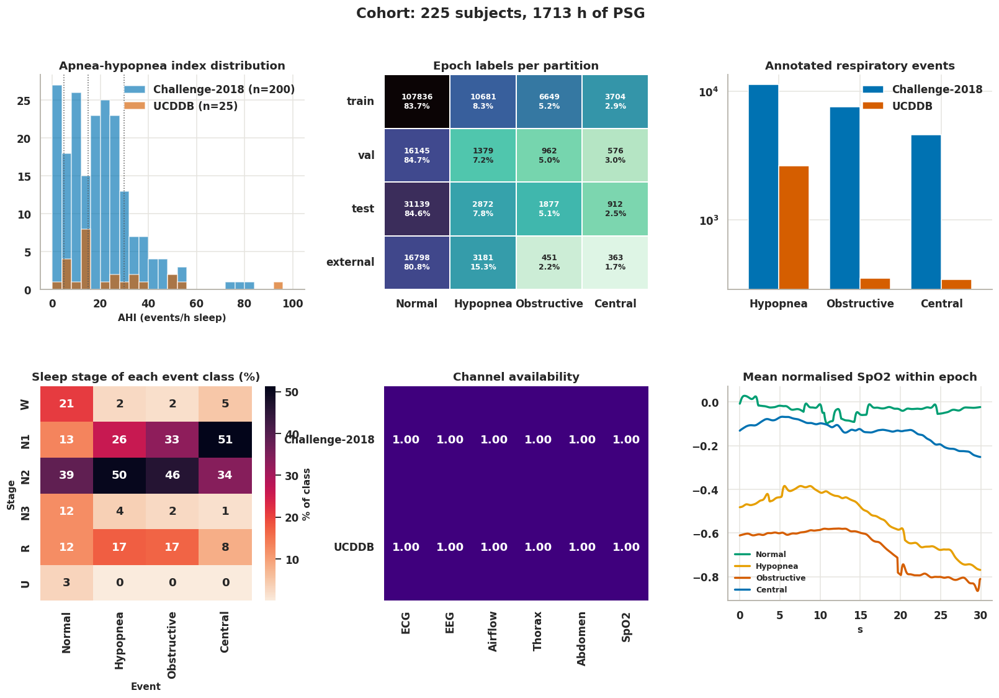

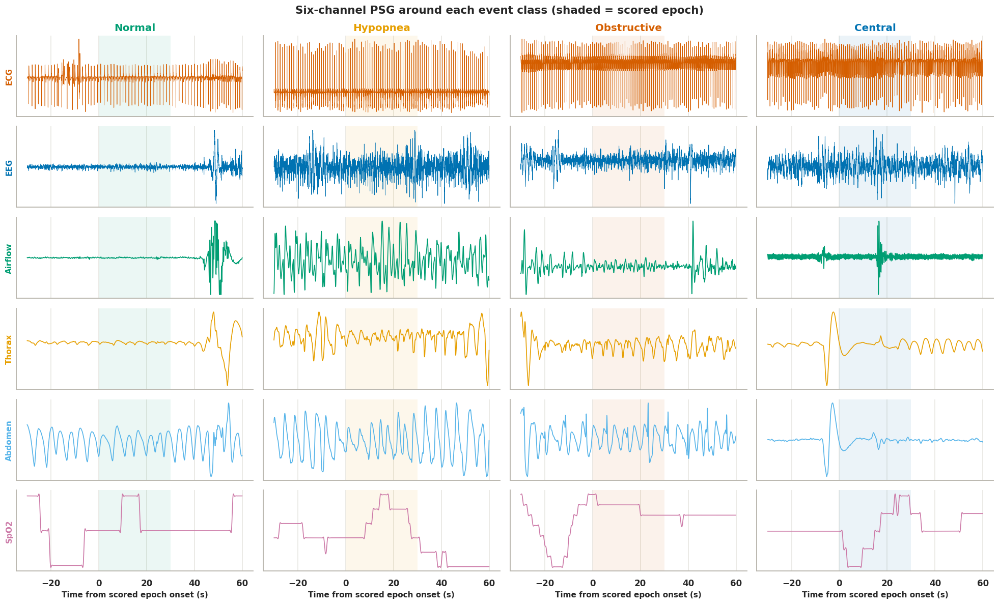

In [21]:
# ===================== STAGE 4 =====================
fig = plt.figure(figsize=(18, 10)); gs = fig.add_gridspec(2, 3, hspace=.45, wspace=.3)
ax = fig.add_subplot(gs[0, 0])
for db, g in META.groupby("db"):
    ax.hist(np.clip(g.ahi, 0, 100), bins=np.linspace(0, 100, 26), alpha=.65, color=DBPAL[db], label=f"{db} (n={len(g)})", edgecolor="white")
for x in (5, 15, 30): ax.axvline(x, color="#555", ls=":", lw=1)
ax.set_xlabel("AHI (events/h sleep)"); ax.set_title("Apnea-hypopnea index distribution"); ax.legend(frameon=False)
ax = fig.add_subplot(gs[0, 1])
part = {k: np.bincount(Y[IDX[k]], minlength=4) for k in SPL}
dfp = pd.DataFrame(part, index=CFG["classes"]).T
sns.heatmap(np.log1p(dfp), annot=np.array([[f"{v}\n{v/dfp.loc[i].sum()*100:.1f}%" for v in dfp.loc[i]] for i in dfp.index]), fmt="",
            cmap="mako_r", cbar=False, ax=ax, linewidths=1, linecolor="white", annot_kws={"fontsize": 8})
ax.set_title("Epoch labels per partition"); ax.tick_params(axis="y", rotation=0)
ax = fig.add_subplot(gs[0, 2])
ev = META.groupby("db")[[f"n_{c}" for c in CFG["classes"][1:]]].sum(); ev.columns = CFG["classes"][1:]
ev.T.plot(kind="bar", ax=ax, color=[DBPAL[d] for d in ev.index], edgecolor="white", width=.75); ax.set_yscale("log")
ax.set_title("Annotated respiratory events"); ax.tick_params(axis="x", rotation=0); ax.legend(frameon=False)
ax = fig.add_subplot(gs[1, 0])
st = pd.crosstab(pd.Series(STG, name="Stage"), pd.Series(np.array(CFG["classes"])[Y], name="Event")).reindex(columns=CFG["classes"], fill_value=0)
st = st.reindex([s for s in ["W", "N1", "N2", "N3", "R", "U"] if s in st.index])
sns.heatmap(st.div(st.sum(0), axis=1) * 100, annot=True, fmt=".0f", cmap="rocket_r", ax=ax, cbar_kws={"label": "% of class"})
ax.set_title("Sleep stage of each event class (%)")
ax = fig.add_subplot(gs[1, 1])
sns.heatmap(META.groupby("db")[[f"m_{m}" for m in MODS]].mean().set_axis(MODS, axis=1), annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1, ax=ax, cbar=False)
ax.set_title("Channel availability"); ax.set_ylabel(""); ax.tick_params(axis="y", rotation=0)
ax = fig.add_subplot(gs[1, 2]); rs = np.random.default_rng(0)
for k, c in enumerate(CFG["classes"]):
    ii = np.where(Y == k)[0]
    if len(ii) == 0: continue
    ii = rs.choice(ii, min(600, len(ii)), replace=False); j = MODS.index("SpO2") - NF
    v = XS[ii, j].astype(np.float32); ax.plot(np.arange(LS) / CFG["fs_slow"], v.mean(0), color=PAL[c], lw=2.2, label=c)
ax.set_title("Mean normalised SpO2 within epoch"); ax.set_xlabel("s"); ax.legend(frameon=False, fontsize=8)
fig.suptitle(f"Cohort: {len(META)} subjects, {len(Y)/120:.0f} h of PSG", fontsize=15, fontweight="bold"); savefig(fig, "01_cohort")

fig, axs = plt.subplots(len(MODS), 4, figsize=(18, 11), sharex="col")
for k, c in enumerate(CFG["classes"]):
    cand = np.where((Y == k) & (MSK.sum(1) == len(MODS)) & (DB == "Challenge-2018"))[0]
    cand = cand[(cand > 0) & (cand < len(Y) - 1) & (REC[np.clip(cand - 1, 0, None)] == REC[cand]) & (REC[np.clip(cand + 1, None, len(Y) - 1)] == REC[cand])]
    if len(cand) == 0: continue
    i = rs.choice(cand)
    for j, m in enumerate(MODS):
        a = axs[j, k]
        seg = np.concatenate([(XF[i + o, j] if j < NF else XS[i + o, j - NF]).astype(np.float32) for o in (-1, 0, 1)])
        fs_ = CFG["fs_fast"] if j < NF else CFG["fs_slow"]; t = np.arange(len(seg)) / fs_ - 30
        a.plot(t, seg, color=MPAL[m], lw=.6 if j < NF else 1.1); a.axvspan(0, 30, color=PAL[c], alpha=.08, lw=0); a.set_yticks([])
        if j == 0: a.set_title(c, color=PAL[c], fontsize=13)
        if k == 0: a.set_ylabel(m, fontweight="bold", color=MPAL[m])
for a in axs[-1]: a.set_xlabel("Time from scored epoch onset (s)")
fig.suptitle("Six-channel PSG around each event class (shaded = scored epoch)", fontsize=14, fontweight="bold")
plt.tight_layout(); savefig(fig, "02_signal_gallery")
set_flag("stage4_eda")

In [22]:
# ===================== STAGE 5  =====================
OSF_REPO = os.path.join("/content" if IN_COLAB else ".", "OSF")
if not os.path.exists(os.path.join(OSF_REPO, "osf/backbone/vit1d_cls.py")):
    subprocess.run(["git", "clone", "-q", "--depth", "1", CFG["osf_repo"], OSF_REPO], check=True)
spec = importlib.util.spec_from_file_location("osf_vit1d_cls", os.path.join(OSF_REPO, "osf/backbone/vit1d_cls.py"))
osf_vit = importlib.util.module_from_spec(spec); spec.loader.exec_module(osf_vit)

wts = sorted(glob.glob(os.path.join(DIRS["fm"], "**", "*.pth"), recursive=True) + glob.glob(os.path.join(DIRS["fm"], "**", "*.pt"), recursive=True))
if not wts:
    from huggingface_hub import list_repo_files, hf_hub_download
    cand = [f for f in list_repo_files(CFG["osf_hf"]) if f.endswith((".pth", ".pt"))]
    print("OSF weight files on HuggingFace:", cand)
    wts = [hf_hub_download(CFG["osf_hf"], cand[0], local_dir=DIRS["fm"])]
payload = torch.load(wts[0], map_location="cpu", weights_only=False); OSF_META = payload["metadata"]
OSF = osf_vit.vit_base(num_leads=OSF_META["num_leads"], seq_len=OSF_META["seq_len"], patch_size=OSF_META["patch_size_time"],
                       lead_wise=OSF_META["lead_wise"], patch_size_ch=OSF_META["patch_size_ch"])
OSF.load_state_dict(payload["state_dict"]); OSF = OSF.to(DEV).eval().requires_grad_(False); del payload
OSF_CH = ["ECG", "EMG_Chin", "EMG_LLeg", "EMG_RLeg", "ABD", "THX", "NP", "SN", "EOG_E1_A2", "EOG_E2_A1", "EEG_C3_A2", "EEG_C4_A1"]
OSF_MAP = {"ECG": "ECG", "ABD": "Abdomen", "THX": "Thorax", "NP": "Airflow", "EEG_C4_A1": "EEG"}
N_GRP = OSF_META["num_leads"] // OSF_META["patch_size_ch"]
print(f"OSF-Base loaded: {sum(p.numel() for p in OSF.parameters())/1e6:.1f} M params | {OSF_META}")

XFT, XST = torch.from_numpy(XF).to(DEV), torch.from_numpy(XS).to(DEV)
MT = torch.from_numpy(MSK).to(DEV)
def osf_input(ix):
    x = torch.zeros(len(ix), 12, LF, device=DEV)
    for k, mod in OSF_MAP.items():
        j = MODS.index(mod)
        sig = XFT[ix, j].float() if j < NF else F.interpolate(XST[ix, j - NF].float()[:, None], size=LF, mode="linear", align_corners=False)[:, 0]
        x[:, OSF_CH.index(k)] = sig * MT[ix, j, None].float()
    return (x * 1.349).clamp(-6, 6)

FM_P, FM_R = os.path.join(DIRS["fm"], "osf_tokens.npy"), os.path.join(DIRS["fm"], "osf_tokens_records.json")
recs_now = [d["rec"] for d in RECS]
ok = os.path.exists(FM_P) and os.path.exists(FM_R) and jload(FM_R) == recs_now
if ok: FMF = np.load(FM_P, mmap_mode="r"); ok = FMF.shape[0] == len(Y)
if not ok:
    FMF = np.lib.format.open_memmap(FM_P + ".tmp.npy", mode="w+", dtype=np.float16, shape=(len(Y), 1 + N_GRP, 768))
    t0 = time.time()
    with torch.no_grad():
        for s in range(0, len(Y), CFG["osf_batch"]):
            ix = torch.arange(s, min(s + CFG["osf_batch"], len(Y)), device=DEV)
            with torch.autocast(device_type=DEV.type, enabled=AMP):
                cls, pat = OSF.forward_encoding(osf_input(ix))
            grp = pat.float().view(len(ix), N_GRP, -1, pat.shape[-1]).mean(2)
            FMF[s:s + len(ix)] = torch.cat([cls.float()[:, None], grp], 1).cpu().numpy().astype(np.float16)
            if (s // CFG["osf_batch"]) % 100 == 0: print(f"  OSF features {s + len(ix)}/{len(Y)}  ({time.time()-t0:.0f}s)")
    FMF.flush(); del FMF; os.replace(FM_P + ".tmp.npy", FM_P); jdump(recs_now, FM_R)
    print(f"OSF extraction {time.time()-t0:.0f}s")
FM = np.load(FM_P); FMT = torch.from_numpy(FM).to(DEV)
with torch.no_grad():
    ix = torch.arange(min(256, len(Y)), device=DEV); xb = osf_input(ix)
    for _ in range(2): OSF.forward_encoding(xb)
    if DEV.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    with torch.autocast(device_type=DEV.type, enabled=AMP): OSF.forward_encoding(xb)
    if DEV.type == "cuda": torch.cuda.synchronize()
OSF_MS = (time.time() - t0) / len(ix) * 1000
OSF_PARAMS = sum(p.numel() for p in OSF.parameters()) / 1e6
print("OSF token cache:", FM.shape, f"| OSF forward {OSF_MS:.3f} ms/epoch")
del OSF; torch.cuda.empty_cache() if DEV.type == "cuda" else None
set_flag("stage5_osf")

OSF-Base loaded: 85.3 M params | {'model_name': 'dino', 'encoder_name': 'vit_base', 'num_leads': 12, 'patch_size_time': 64, 'patch_size_ch': 4, 'lead_wise': 1, 'sample_rate': 64, 'window_size_sec': 30, 'seq_len': 1920, 'width': 768, 'depth': 12}
OSF token cache: (205525, 4, 768) | OSF forward 1.623 ms/epoch


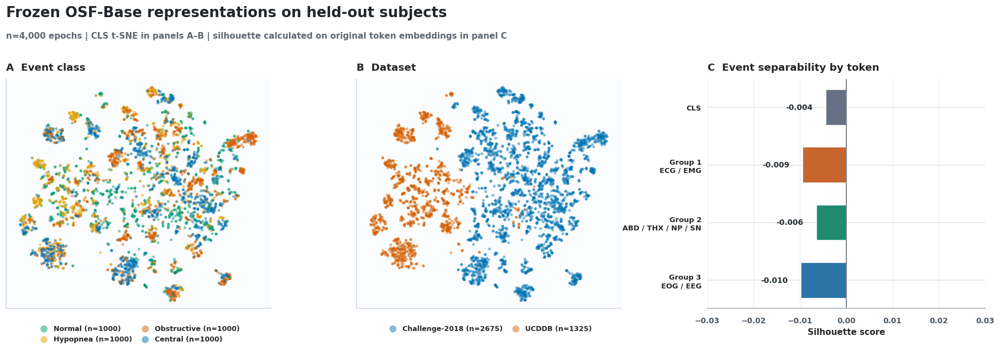

In [23]:
# ===================== STAGE 6 =====================
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

rs = np.random.default_rng(3)
pool_ix = np.concatenate([IDX["test"], IDX["external"]])
sub = np.concatenate([
    rs.choice(
        pool_ix[Y[pool_ix] == k],
        min((Y[pool_ix] == k).sum(), CFG["tsne_n"] // 4),
        replace=False,
    )
    for k in range(4) if (Y[pool_ix] == k).any()
])

TSP = os.path.join(DIRS["results"], "osf_tsne.npz")
E_ = None
if os.path.exists(TSP):
    with np.load(TSP) as cached:
        if np.array_equal(cached["sub"], sub) and cached["e"].shape == (len(sub), 2):
            E_ = cached["e"]

if E_ is None:
    E_ = TSNE(
        n_components=2, perplexity=35, init="pca", random_state=0
    ).fit_transform(FM[sub, 0].astype(np.float32))
    np.savez(TSP, e=E_, sub=sub)

names = ["CLS"] + [f"Group {g + 1}" for g in range(N_GRP)]
grp_desc = {
    1: "ECG / EMG",
    2: "ABD / THX / NP / SN",
    3: "EOG / EEG",
}
sil = np.array([
    silhouette_score(FM[sub, t].astype(np.float32), Y[sub])
    for t in range(1 + N_GRP)
])

fig = plt.figure(figsize=(17.5, 6.4), facecolor="white")
gs = fig.add_gridspec(
    1, 3, width_ratios=[1, 1, 1.05],
    left=.055, right=.975, top=.78, bottom=.19, wspace=.32,
)
ax_event, ax_cohort, ax_token = [
    fig.add_subplot(gs[0, i]) for i in range(3)
]

for k, class_name in enumerate(CFG["classes"]):
    mask = Y[sub] == k
    ax_event.scatter(
        E_[mask, 0], E_[mask, 1],
        s=11, alpha=.50, color=PAL[class_name],
        edgecolors="none", rasterized=True,
        label=f"{class_name} (n={mask.sum()})",
    )

for dataset_name in DBPAL:
    mask = DB[sub] == dataset_name
    if mask.any():
        ax_cohort.scatter(
            E_[mask, 0], E_[mask, 1],
            s=11, alpha=.48, color=DBPAL[dataset_name],
            edgecolors="none", rasterized=True,
            label=f"{dataset_name} (n={mask.sum()})",
        )

for ax, title in (
    (ax_event, "A  Event class"),
    (ax_cohort, "B  Dataset"),
):
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", pad=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal", adjustable="datalim")
    ax.margins(.06)
    ax.set_facecolor("#FBFCFD")
    for spine in ax.spines.values():
        spine.set_color("#D8DEE5")
    ax.legend(
        loc="upper center", bbox_to_anchor=(.5, -.045),
        ncol=2, frameon=False, markerscale=2.5,
        fontsize=8.3, handletextpad=.35, columnspacing=.9,
    )

token_labels = [
    name if not grp_desc.get(i) else f"{name}\n{grp_desc[i]}"
    for i, name in enumerate(names)
]
ypos = np.arange(len(sil))[::-1]
token_colors = ["#667085", "#C7652F", "#208B70", "#2B75A8"][:len(sil)]

ax_token.barh(
    ypos, sil, height=.62, color=token_colors,
    edgecolor="white", linewidth=1,
)
ax_token.axvline(0, color="#5C6670", lw=1)
ax_token.set_yticks(ypos, token_labels)
ax_token.set_xlabel("Silhouette score")
ax_token.set_title(
    "C  Event separability by token",
    loc="left", fontsize=12, fontweight="bold", pad=10,
)
ax_token.set_axisbelow(True)
ax_token.grid(axis="x", color="#E8EDF2", lw=.8)
for side in ("top", "right", "left"):
    ax_token.spines[side].set_visible(False)
ax_token.spines["bottom"].set_color("#B4BCC4")
ax_token.tick_params(axis="y", length=0, labelsize=8.5, pad=7)
ax_token.tick_params(axis="x", colors="#4F5B66", labelsize=9)

span = max(np.ptp(sil), .08)
ax_token.set_xlim(
    min(-.03, sil.min() - .22 * span),
    max(.03, sil.max() + .30 * span),
)
for y, value in zip(ypos, sil):
    offset = .035 * span
    ax_token.text(
        value + offset if value >= 0 else value - offset,
        y, f"{value:+.3f}", va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9, fontweight="bold", color="#263238",
    )

fig.text(
    .055, .94,
    "Frozen OSF-Base representations on held-out subjects",
    fontsize=17, fontweight="bold", color="#20262C",
)
fig.text(
    .055, .885,
    f"n={len(sub):,} epochs | CLS t-SNE in panels A–B | "
    "silhouette calculated on original token embeddings in panel C",
    fontsize=10, color="#5C6670",
)
savefig(fig, "03_osf_zero_shot")

NocturNet                         1.215
DeepSleepNet                     24.171
TinySleepNet                      1.469
AttnSleep                         0.597
SeqSleepNet                       0.163
SleepTransformer                  1.798
U-Time                            1.166
OSF linear probe                  0.018
NocturNet-S (+ staging head)      1.216
w/o acquisition randomisation     1.215
+ montage dropout                 1.215
w/o night-level context           0.884
w/o SpO2                          1.215


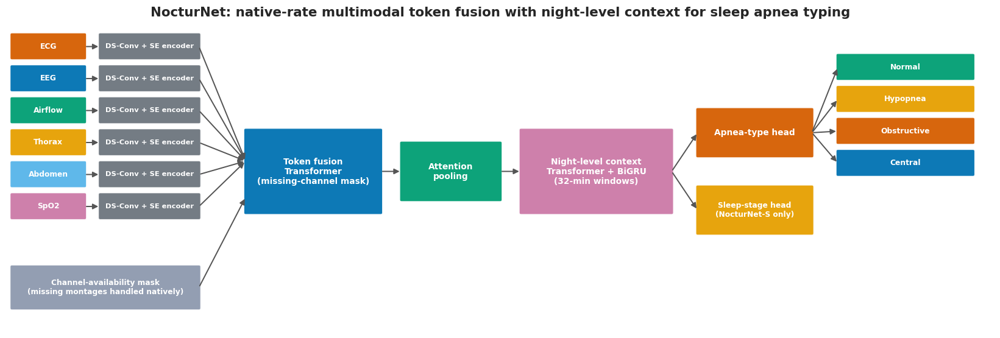

In [24]:
# ===================== STAGE 7  =====================
class SE(nn.Module):
    def __init__(self, c, r=4): super().__init__(); self.f = nn.Sequential(nn.Linear(c, max(c // r, 4)), nn.GELU(), nn.Linear(max(c // r, 4), c), nn.Sigmoid())
    def forward(self, x): return x * self.f(x.mean(-1)).unsqueeze(-1)
def dsconv(ci, co, k=7):
    return nn.Sequential(nn.Conv1d(ci, ci, k, 2, k // 2, groups=ci, bias=False), nn.Conv1d(ci, co, 1, bias=False), nn.BatchNorm1d(co), nn.GELU(), SE(co))
class RawEncoder(nn.Module):
    def __init__(self, d, fast):
        super().__init__(); ch = [32, 48, 64, 96, 128, 128] if fast else [32, 48, 64, 96, 128]
        self.net = nn.Sequential(nn.Conv1d(1, 32, 9, 2 if fast else 1, 4, bias=False), nn.BatchNorm1d(32), nn.GELU(),
                                 *[dsconv(a, b) for a, b in zip(ch[:-1], ch[1:])])
        self.proj = nn.Linear(256, d)
    def forward(self, x):
        h = self.net(x.unsqueeze(1)); return self.proj(torch.cat([h.mean(-1), h.amax(-1)], 1))
def tf_layers(d, heads, ff, n, drop=.1):
    return nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, ff, drop, batch_first=True, norm_first=True), n)
def x64(b):
    B, T = b["m"].shape[:2]
    up = F.interpolate(b["xs"].reshape(B * T, NS, LS), size=LF, mode="linear", align_corners=False).view(B, T, NS, LF)
    return torch.cat([b["xf"], up], 2)

# ---------------- proposed ----------------
class NocturNet(nn.Module):
    """OSF-Base foundation tokens + native-rate multimodal encoders (incl. SpO2) -> token fusion -> night-level Transformer-BiGRU."""
    def __init__(self, cfg, use_fm=True, use_raw=True, sequence=True, aux=True, mods=None):
        super().__init__(); d = cfg["d_model"]; M = len(MODS)
        self.use_fm, self.use_raw, self.sequence, self.aux = use_fm, use_raw, sequence, aux
        self.mods = list(range(M)) if mods is None else mods
        if use_raw: self.enc = nn.ModuleList([RawEncoder(d, j < NF) for j in range(M)]); self.memb = nn.Parameter(.02 * torch.randn(M, d))
        if use_fm: self.fproj = nn.Sequential(nn.LayerNorm(768), nn.Linear(768, d), nn.GELU(), nn.Linear(d, d)); self.femb = nn.Parameter(.02 * torch.randn(1 + N_GRP, d))
        self.fuse = tf_layers(d, 4, 2 * d, 2)
        self.q = nn.Parameter(.02 * torch.randn(1, 1, d)); self.pool = nn.MultiheadAttention(d, 4, batch_first=True)
        if sequence:
            self.pos = nn.Parameter(.02 * torch.randn(1, cfg["seq_len"], d)); self.stf = tf_layers(d, 4, 2 * d, 2)
            self.gru = nn.GRU(d, d // 2, batch_first=True, bidirectional=True)
        else: self.loc = nn.Sequential(nn.Linear(d, d), nn.GELU())
        self.head = nn.Sequential(nn.Linear(2 * d, 128), nn.GELU(), nn.Dropout(.2), nn.Linear(128, 4))
        if aux: self.shead = nn.Linear(2 * d, len(STAGE_NAMES))
    def forward(self, b):
        m = b["m"]; B, T = m.shape[:2]; BT = B * T; tok, pad = [], []
        if self.use_raw:
            mm = m.reshape(BT, -1).clone(); keep = torch.zeros_like(mm); keep[:, self.mods] = 1; mm = mm * keep
            if not self.use_fm: mm[:, self.mods[0]] = 1
            xf, xs = b["xf"].reshape(BT, NF, -1), b["xs"].reshape(BT, NS, -1)
            tok.append(torch.stack([self.enc[j](xf[:, j] if j < NF else xs[:, j - NF]) for j in range(len(MODS))], 1) + self.memb); pad.append(mm < .5)
        if self.use_fm:
            tok.append(self.fproj(b["fm"].reshape(BT, 1 + N_GRP, 768)) + self.femb); pad.append(torch.zeros(BT, 1 + N_GRP, dtype=torch.bool, device=m.device))
        tok, pad = torch.cat(tok, 1), torch.cat(pad, 1)
        h = self.fuse(tok, src_key_padding_mask=pad)
        e, w = self.pool(self.q.expand(BT, -1, -1), h, h, key_padding_mask=pad); e, w = e[:, 0], w[:, 0]
        if self.sequence:
            z = self.stf(e.view(B, T, -1) + self.pos[:, :T]); hc = torch.cat([z, self.gru(z)[0]], -1).reshape(BT, -1)
        else: hc = torch.cat([e, self.loc(e)], 1)
        out = dict(logits=self.head(hc), w=w, emb=hc)
        if self.aux: out["stage"] = self.shead(hc)
        return out

class DeepSleepNet(nn.Module):          # Supratak et al., IEEE TNSRE 2017
    def __init__(self, C=len(MODS), fs=CFG["fs_fast"]):
        super().__init__()
        cb = lambda ci, co, k: [nn.Conv1d(ci, co, k, 1, k // 2, bias=False), nn.BatchNorm1d(co), nn.ReLU()]
        self.small = nn.Sequential(nn.Conv1d(C, 64, fs // 2, fs // 16, bias=False), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(8, 8), nn.Dropout(.5),
                                   *cb(64, 128, 8), *cb(128, 128, 8), *cb(128, 128, 8), nn.MaxPool1d(4, 4), nn.Flatten())
        self.large = nn.Sequential(nn.Conv1d(C, 64, fs * 4, fs // 2, bias=False), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(4, 4), nn.Dropout(.5),
                                   *cb(64, 128, 6), *cb(128, 128, 6), *cb(128, 128, 6), nn.MaxPool1d(2, 2), nn.Flatten())
        with torch.no_grad(): dim = self.small(torch.zeros(1, C, LF)).shape[1] + self.large(torch.zeros(1, C, LF)).shape[1]
        self.drop = nn.Dropout(.5); self.lstm = nn.LSTM(dim, 512, 2, batch_first=True, bidirectional=True, dropout=.5)
        self.short = nn.Sequential(nn.Linear(dim, 1024), nn.BatchNorm1d(1024), nn.ReLU()); self.out = nn.Linear(1024, 4)
    def forward(self, b):
        x = x64(b); B, T = x.shape[:2]; x = x.reshape(B * T, *x.shape[2:])
        f = self.drop(torch.cat([self.small(x), self.large(x)], 1)); s = self.lstm(f.view(B, T, -1))[0].reshape(B * T, -1)
        return dict(logits=self.out(self.drop(s + self.short(f))))

class TinySleepNet(nn.Module):          # Supratak & Guo, EMBC 2020
    def __init__(self, C=len(MODS), fs=CFG["fs_fast"]):
        super().__init__()
        cb = lambda: [nn.Conv1d(128, 128, 8, 1, 4, bias=False), nn.BatchNorm1d(128), nn.ReLU()]
        self.cnn = nn.Sequential(nn.Conv1d(C, 128, fs // 2, fs // 16, bias=False), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(8, 8), nn.Dropout(.5),
                                 *cb(), *cb(), *cb(), nn.MaxPool1d(4, 4), nn.Flatten(), nn.Dropout(.5))
        with torch.no_grad(): dim = self.cnn(torch.zeros(1, C, LF)).shape[1]
        self.lstm = nn.LSTM(dim, 128, batch_first=True); self.out = nn.Sequential(nn.Dropout(.5), nn.Linear(128, 4))
    def forward(self, b):
        x = x64(b); B, T = x.shape[:2]
        f = self.cnn(x.reshape(B * T, *x.shape[2:])).view(B, T, -1)
        return dict(logits=self.out(self.lstm(f)[0].reshape(B * T, -1)))

class SEResBlock(nn.Module):
    def __init__(self, ci, co):
        super().__init__()
        self.b = nn.Sequential(nn.Conv1d(ci, co, 1, bias=False), nn.BatchNorm1d(co), nn.ReLU(), nn.Conv1d(co, co, 1, bias=False), nn.BatchNorm1d(co), SE(co, 4))
        self.sc = nn.Sequential(nn.Conv1d(ci, co, 1, bias=False), nn.BatchNorm1d(co))
    def forward(self, x): return F.relu(self.b(x) + self.sc(x))
class AttnSleep(nn.Module):             # Eldele et al., IEEE TNSRE 2021 (epoch-level)
    def __init__(self, C=len(MODS), afr=30, d=80, heads=5):
        super().__init__()
        g = lambda ci, co, k, s=1: [nn.Conv1d(ci, co, k, s, k // 2, bias=False), nn.BatchNorm1d(co), nn.GELU()]
        self.b1 = nn.Sequential(*g(C, 64, 32, 4), nn.MaxPool1d(8, 2, 4), nn.Dropout(.5), *g(64, 128, 8), *g(128, 128, 8), nn.MaxPool1d(4, 4, 2))
        self.b2 = nn.Sequential(*g(C, 64, 256, 32), nn.MaxPool1d(4, 2, 2), nn.Dropout(.5), *g(64, 128, 7), *g(128, 128, 7), nn.MaxPool1d(2, 2, 1))
        self.afr = SEResBlock(128, afr); self.drop = nn.Dropout(.5)
        with torch.no_grad(): L = torch.cat([self.b1(torch.zeros(1, C, LF)), self.b2(torch.zeros(1, C, LF))], -1).shape[-1]
        self.proj = nn.Linear(L, d); self.tce = tf_layers(d, heads, 120, 2); self.out = nn.Linear(afr * d, 4)
    def forward(self, b):
        x = x64(b); B, T = x.shape[:2]; x = x.reshape(B * T, *x.shape[2:])
        h = self.afr(self.drop(torch.cat([self.b1(x), self.b2(x)], -1)))
        return dict(logits=self.out(self.tce(self.proj(h)).flatten(1)))

def log_spec(x):                        # x [N, C, 1920] -> [N, frames, C, bins]
    N, C, L = x.shape
    S = torch.stft(x.reshape(N * C, L).float(), n_fft=128, hop_length=64, win_length=128,
                   window=torch.hann_window(128, device=x.device), center=False, return_complex=True)
    return torch.log(S.abs() ** 2 + 0.1).view(N, C, S.shape[-2], S.shape[-1]).permute(0, 3, 1, 2)   # 0.1 noise floor: train/eval-consistent spectra
class AttnPool(nn.Module):
    def __init__(self, d): super().__init__(); self.a = nn.Sequential(nn.Linear(d, d // 2), nn.Tanh(), nn.Linear(d // 2, 1))
    def forward(self, h): w = self.a(h).softmax(1); return (w * h).sum(1)
class SeqSleepNet(nn.Module):           # Phan et al., IEEE TNSRE 2019
    def __init__(self, C=len(MODS), nf=20, H=64):
        super().__init__(); self.fb = nn.Parameter(torch.rand(C, 65, nf) * .1); self.norm = nn.LayerNorm(C * nf)
        self.egru = nn.GRU(C * nf, H, batch_first=True, bidirectional=True); self.pool = AttnPool(2 * H)
        self.sgru = nn.GRU(2 * H, H, batch_first=True, bidirectional=True); self.out = nn.Linear(2 * H, 4)
    def forward(self, b):
        x = x64(b); B, T = x.shape[:2]; S = log_spec(x.reshape(B * T, *x.shape[2:]))
        f = self.norm(torch.einsum("nfcb,cbk->nfck", S, F.softplus(self.fb)).flatten(2))
        e = self.pool(self.egru(f)[0]).view(B, T, -1)
        return dict(logits=self.out(self.sgru(e)[0].reshape(B * T, -1)))

class SleepTransformer(nn.Module):      # Phan et al., IEEE TBME 2022
    def __init__(self, C=len(MODS), d=128, heads=8, n=4):
        super().__init__(); self.inp = nn.Sequential(nn.LayerNorm(C * 65), nn.Linear(C * 65, d))
        self.fpos = nn.Parameter(.02 * torch.randn(1, 64, d)); self.etf = tf_layers(d, heads, 4 * d, n); self.pool = AttnPool(d)
        self.spos = nn.Parameter(.02 * torch.randn(1, CFG["seq_len"], d)); self.stf = tf_layers(d, heads, 4 * d, n)
        self.out = nn.Sequential(nn.Linear(d, 1024), nn.ReLU(), nn.Dropout(.1), nn.Linear(1024, 4))
    def forward(self, b):
        x = x64(b); B, T = x.shape[:2]; S = log_spec(x.reshape(B * T, *x.shape[2:])).flatten(2)
        h = self.etf(self.inp(S) + self.fpos[:, :S.shape[1]]); e = self.pool(h).view(B, T, -1)
        return dict(logits=self.out(self.stf(e + self.spos[:, :T]).reshape(B * T, -1)))

class UTime(nn.Module):                 # Perslev et al., NeurIPS 2019
    def __init__(self, C=len(MODS), ch=(16, 32, 64, 128), pools=(8, 6, 4, 4), k=5, dil=2):
        super().__init__()
        cv = lambda ci, co: [nn.Conv1d(ci, co, k, padding=dil * (k - 1) // 2, dilation=dil), nn.ReLU(), nn.BatchNorm1d(co)]
        self.pools = pools; self.enc = nn.ModuleList(); ci = C
        for c in ch: self.enc.append(nn.Sequential(*cv(ci, c), *cv(c, c))); ci = c
        self.bott = nn.Sequential(*cv(ci, 256), *cv(256, 256)); ci = 256
        self.up, self.dec = nn.ModuleList(), nn.ModuleList()
        for c, p in zip(reversed(ch), reversed(pools)):
            self.up.append(nn.Sequential(nn.Upsample(scale_factor=p), nn.Conv1d(ci, c, p, padding="same"), nn.ReLU(), nn.BatchNorm1d(c)))
            self.dec.append(nn.Sequential(*cv(2 * c, c), *cv(c, c))); ci = c
        self.dense = nn.Conv1d(ci, 4, 1); self.seg = nn.Conv1d(4, 4, 1)
    def forward(self, b):
        x = x64(b); B, T = x.shape[:2]; h = x.permute(0, 2, 1, 3).reshape(B, x.shape[2], T * LF); skips = []
        for e, p in zip(self.enc, self.pools): h = e(h); skips.append(h); h = F.max_pool1d(h, p)
        h = self.bott(h)
        for u, d_, s in zip(self.up, self.dec, reversed(skips)): h = d_(torch.cat([u(h), s], 1))
        z = torch.tanh(self.dense(h)).view(B, 4, T, LF).mean(-1)
        return dict(logits=self.seg(z).permute(0, 2, 1).reshape(B * T, 4))

class OSFLinearProbe(nn.Module):        # standard foundation-model linear probe on frozen OSF tokens
    def __init__(self): super().__init__(); self.out = nn.Sequential(nn.LayerNorm((1 + N_GRP) * 768), nn.Linear((1 + N_GRP) * 768, 4))
    def forward(self, b): B, T = b["m"].shape[:2]; return dict(logits=self.out(b["fm"].reshape(B * T, -1)))

MODELS = {
    PROPOSED:           ("Proposed", lambda: NocturNet(CFG, use_fm=False, aux=False)),
    "DeepSleepNet":     ("Baseline", DeepSleepNet),
    "TinySleepNet":     ("Baseline", TinySleepNet),
    "AttnSleep":        ("Baseline", AttnSleep),
    "SeqSleepNet":      ("Baseline", SeqSleepNet),
    "SleepTransformer": ("Baseline", SleepTransformer),
    "U-Time":           ("Baseline", UTime),
    "OSF linear probe": ("Baseline", OSFLinearProbe),
    NSV:                              ("Ablation", lambda: NocturNet(CFG, use_fm=False, aux=True)),
    "w/o acquisition randomisation":  ("Ablation", lambda: NocturNet(CFG, use_fm=False, aux=False)),
    "+ montage dropout":              ("Ablation", lambda: NocturNet(CFG, use_fm=False, aux=False)),
    "w/o night-level context":        ("Ablation", lambda: NocturNet(CFG, use_fm=False, aux=False, sequence=False)),
    "w/o SpO2":                       ("Ablation", lambda: NocturNet(CFG, use_fm=False, aux=False, mods=[j for j in range(len(MODS)) if MODS[j] != "SpO2"])),
}
FM_MODELS = {"OSF linear probe"}
CFG.update(montage_p=0.5, dg_p=0.8)
_R = (0.0, CFG["dg_p"])
AUG = {PROPOSED: _R, NSV: _R, "+ montage dropout": (CFG["montage_p"], CFG["dg_p"]), "w/o night-level context": _R, "w/o SpO2": _R}
TAG_ALIAS = {PROPOSED: "w_o_montage_dropout_v5_na", NSV: "NocturNet_S_acq_v5",
             "w/o acquisition randomisation": "w_o_robust_training_v5_na", "+ montage dropout": "w_o_auxiliary_staging_v5_dg",
             "w/o night-level context": "w_o_night_level_context_v5_acq", "w/o SpO2": "w_o_SpO2_v5_acq"}
RECIPE = {"SleepTransformer": dict(lr=1e-4, pct_start=.3), "SeqSleepNet": dict(epochs=40, patience=10)}
SEEDED = [PROPOSED, "DeepSleepNet", "U-Time"]
REUSE_V4 = {"DeepSleepNet": "DeepSleepNet_v4", "TinySleepNet": "TinySleepNet_v4",
            "AttnSleep": "AttnSleep_v4", "U-Time": "U_Time_v4", "OSF linear probe": "OSF_linear_probe_v4"}
def TAG(n, seed=None):
    t = TAG_ALIAS.get(n) or (re.sub(r"[^A-Za-z0-9]+", "_", n).strip("_") + "_" + CFG["version"] + ("_dg" if n in AUG else ""))
    return t if seed in (None, CFG["seed"]) else f"{t}_s{seed}"
for n, old in REUSE_V4.items():
    src, dst = os.path.join(DIRS["checkpoints"], old), os.path.join(DIRS["checkpoints"], TAG(n))
    if os.path.exists(os.path.join(src, "done.json")) and not os.path.exists(dst):
        shutil.copytree(src, dst, ignore=shutil.ignore_patterns("last.pt")); print(f"re-using v4 weights: {old} -> {TAG(n)}")
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad) / 1e6

_b = dict(xf=torch.randn(2, 4, NF, LF, device=DEV), xs=torch.randn(2, 4, NS, LS, device=DEV), m=torch.ones(2, 4, len(MODS), device=DEV),
          fm=torch.randn(2, 4, 1 + N_GRP, 768, device=DEV))
PARAMS = {}
for n, (g, mk) in MODELS.items():
    mm = mk().to(DEV).eval()
    with torch.no_grad(): o = mm(_b)
    assert o["logits"].shape == (8, 4), n; PARAMS[n] = n_params(mm)
print(pd.Series(PARAMS, name="trainable params (M)").round(3).to_string()); del mm, _b

fig, ax = plt.subplots(figsize=(19, 6)); ax.axis("off"); ax.set_xlim(0, 19); ax.set_ylim(0, 6)
def box(x, y, w, h, t, c, fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=c, ec="white", lw=1.5, alpha=.95))
    ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", color="white", fontsize=fs, fontweight="bold")
def arrow(x0, y0, x1, y1): ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.3))
for j, m in enumerate(MODS):
    y = 5.3 - j * .62; box(.1, y, 1.4, .45, m, MPAL[m], 8); box(1.8, y, 1.9, .45, "DS-Conv + SE encoder", "#6C757D", 7.5)
    arrow(1.5, y + .22, 1.8, y + .22); arrow(3.7, y + .22, 4.6, 3.3)
box(.1, .45, 3.6, .8, "Channel-availability mask\n(missing montages handled natively)", "#8D99AE", 8); arrow(3.7, .85, 4.6, 2.6)
box(4.6, 2.3, 2.6, 1.6, "Token fusion\nTransformer\n(missing-channel mask)", "#0072B2")
box(7.6, 2.55, 1.9, 1.1, "Attention\npooling", "#009E73"); arrow(7.2, 3.1, 7.6, 3.1)
box(9.9, 2.3, 2.9, 1.6, "Night-level context\nTransformer + BiGRU\n(32-min windows)", "#CC79A7"); arrow(9.5, 3.1, 9.9, 3.1)
box(13.3, 3.4, 2.2, .9, "Apnea-type head", "#D55E00"); box(13.3, 1.9, 2.2, .9, "Sleep-stage head\n(NocturNet-S only)", "#E69F00", 8)
arrow(12.8, 3.1, 13.3, 3.85); arrow(12.8, 3.1, 13.3, 2.35)
for k, c in enumerate(CFG["classes"]): box(16.0, 4.9 - k * .62, 2.6, .45, c, PAL[c], 8); arrow(15.5, 3.85, 16.0, 5.12 - k * .62)
ax.set_title("NocturNet: native-rate multimodal token fusion with night-level context for sleep apnea typing", fontsize=14)
savefig(fig, "04_architecture")

In [25]:
# ===================== STAGE 8  =====================
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef, roc_auc_score,
                             average_precision_score, confusion_matrix, precision_recall_fscore_support, roc_curve, precision_recall_curve)
YT, STT = torch.from_numpy(Y).to(DEV), torch.from_numpy(STG_I).to(DEV)
T_ = CFG["seq_len"]; AR = torch.arange(T_, device=DEV)
def windows(recs, stride):
    out = []
    for r in recs:
        a, b = SPAN[r]; st = list(range(a, b - T_ + 1, stride))
        if st[-1] != b - T_: st.append(b - T_)
        out += st
    return np.array(out)
def get_batch(starts, aug=False):
    ix = torch.as_tensor(starts, device=DEV)[:, None] + AR
    xf, xs, m, fm = XFT[ix].float(), XST[ix].float(), MT[ix].float(), FMT[ix].float()
    if aug:
        B = len(starts)
        xf = xf * (1 + .1 * torch.randn(B, 1, NF, 1, device=DEV)) + .03 * torch.randn_like(xf)
        xs = xs * (1 + .1 * torch.randn(B, 1, NS, 1, device=DEV)) + .03 * torch.randn_like(xs)
        drop = torch.rand(B, 1, len(MODS), device=DEV) < CFG["mod_dropout"]; drop[..., 0] = False; m = m * (~drop)
        fm = F.dropout(fm, .1) + .02 * torch.randn_like(fm)
    xf, xs = xf * m[..., :NF, None], xs * m[..., NF:, None]
    return dict(xf=xf, xs=xs, m=m, fm=fm, ix=ix)
def focal(logits, y, g, alpha):
    lp = F.log_softmax(logits.float(), 1); lpt = lp.gather(1, y[:, None])[:, 0]
    return (alpha[y] * -(1 - lpt.exp()) ** g * lpt).sum() / alpha[y].sum()

@torch.no_grad()
def predict(model, recs, want=()):
    model.eval(); N = len(Y); acc = np.zeros((N, 4), np.float32); cnt = np.zeros(N, np.float32)
    ext = {k: None for k in want}; st = windows(recs, T_ // 4)
    for s in range(0, len(st), 8):
        b = get_batch(st[s:s + 8])
        with torch.autocast(device_type=DEV.type, enabled=AMP): o = model(b)
        ixn = b["ix"].reshape(-1).cpu().numpy(); np.add.at(acc, ixn, o["logits"].float().log_softmax(1).cpu().numpy()); np.add.at(cnt, ixn, 1)
        for k in want:
            v = o[k].float().cpu().numpy()
            if ext[k] is None: ext[k] = np.zeros((N, v.shape[-1]), np.float32)
            np.add.at(ext[k], ixn, v)
    sel = cnt > 0; acc[sel] /= cnt[sel, None]
    for k in want:
        if ext[k] is not None: ext[k][sel] /= cnt[sel, None]
    return acc, {k: v for k, v in ext.items() if v is not None}

def fit_temperature(lp, y):
    grid = np.exp(np.linspace(np.log(.3), np.log(5), 60)); best, bt = 1e9, 1.0
    for t in grid:
        z = lp / t; z = z - z.max(1, keepdims=True); nll = -(z[np.arange(len(y)), y] - np.log(np.exp(z).sum(1))).mean()
        if nll < best: best, bt = nll, t
    return bt
def fit_bias(lp, y):
    b = np.zeros(4); grid = np.linspace(-3, 3, 31)
    for _ in range(3):
        for k in range(1, 4):
            sc = [f1_score(y, (lp + np.where(np.arange(4) == k, g, b)).argmax(1), average="macro") for g in grid]
            b[k] = grid[int(np.argmax(sc))]
    return b
def softmax_np(z): z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

MONTAGES = {
    "full PSG":                      [1, 1, 1, 1, 1, 1],
    "no SpO2":                       [1, 1, 1, 1, 1, 0],
    "no EEG":                        [1, 0, 1, 1, 1, 1],
    "no airflow":                    [1, 1, 0, 1, 1, 1],
    "HSAT: airflow+belts+SpO2":      [1, 0, 1, 1, 1, 1],
    "airflow + one belt":            [1, 1, 1, 1, 0, 0],
    "belts only":                    [1, 1, 0, 1, 1, 0],
    "airflow only":                  [1, 1, 1, 0, 0, 0],
    "cardio-respiratory, no SpO2":   [1, 0, 1, 1, 1, 0],
}
assert list(MODS) == ["ECG", "EEG", "Airflow", "Thorax", "Abdomen", "SpO2"]
MONT_T = torch.tensor(list(MONTAGES.values())[1:], dtype=torch.float, device=DEV)
TRAIN_MONTAGE, TRAIN_DG, EVAL_KEEP = 0.0, 0.0, None
_GB_BASE = get_batch
def _smooth(x, k):
    if k <= 1: return x
    sh = x.shape; y = F.avg_pool1d(x.reshape(-1, 1, sh[-1]), k, 1, k // 2, count_include_pad=False)
    return y[..., :sh[-1]].reshape(sh)
def _rescale(x, s):
    sh = x.shape; L = sh[-1]; y = F.interpolate(x.reshape(-1, 1, L), scale_factor=s, mode="linear", align_corners=False)
    y = y[..., :L] if y.shape[-1] >= L else F.pad(y, (0, L - y.shape[-1]), mode="replicate")
    return y.reshape(sh)
def acq_randomise(b):
    if torch.rand(1).item() > TRAIN_DG: return b
    xf, xs = b["xf"], b["xs"]; B = xf.shape[0]
    xf = xf * torch.exp(.25 * torch.randn(B, 1, NF, 1, device=DEV)); xs = xs * torch.exp(.25 * torch.randn(B, 1, NS, 1, device=DEV))
    sgn = torch.where(torch.rand(B, 1, 1, device=DEV) < .3, -1., 1.); xf = torch.cat([xf[:, :, :1] * sgn[..., None], xf[:, :, 1:]], 2)
    xf = _smooth(xf, int(np.random.choice([1, 3, 5, 7]))); xs = _smooth(xs, int(np.random.choice([1, 3, 5])))
    s = float(np.random.uniform(.92, 1.08)); xf, xs = _rescale(xf, s), _rescale(xs, s)
    t = torch.linspace(0, 1, LS, device=DEV)
    xs = xs + .3 * torch.randn(B, 1, NS, 1, device=DEV) * torch.sin(2 * math.pi * (t * torch.rand(B, 1, NS, 1, device=DEV) * 2 + torch.rand(B, 1, NS, 1, device=DEV)))
    m = b["m"]; b.update(xf=xf * m[..., :NF, None], xs=xs * m[..., NF:, None]); return b
def get_batch(starts, aug=False):
    b = _GB_BASE(starts, aug); keep = None
    if aug and TRAIN_MONTAGE > 0:
        B = len(starts); use = torch.rand(B, device=DEV) < TRAIN_MONTAGE
        keep = torch.where(use[:, None], MONT_T[torch.randint(len(MONT_T), (B,), device=DEV)], torch.ones(B, len(MODS), device=DEV))[:, None]
    elif not aug and EVAL_KEEP is not None:
        keep = torch.as_tensor(EVAL_KEEP, dtype=torch.float, device=DEV)[None, None]
    if aug and TRAIN_DG > 0: b = acq_randomise(b)
    if keep is not None:
        m = b["m"] * keep; b.update(m=m, xf=b["xf"] * m[..., :NF, None], xs=b["xs"] * m[..., NF:, None])
    return b

if not hasattr(torch, "_set_rng_state_orig"): torch._set_rng_state_orig = torch.set_rng_state
torch.set_rng_state = lambda s_: torch._set_rng_state_orig(s_.detach().to("cpu", torch.uint8))   # GPU-loaded RNG state -> CPU on resume

def train_model(name, epochs, seed=None):
    global TRAIN_MONTAGE, TRAIN_DG
    TRAIN_MONTAGE, TRAIN_DG = AUG.get(name, (0.0, 0.0))
    try: return _train_model_core(name, epochs, seed)
    finally: TRAIN_MONTAGE, TRAIN_DG = 0.0, 0.0
def _train_model_core(name, epochs, seed=None):
    seed = CFG["seed"] if seed is None else seed
    rc = {**dict(lr=CFG["lr"], pct_start=.15, epochs=epochs, patience=CFG["patience"]), **RECIPE.get(name, {})}; epochs = rc["epochs"]
    tag = TAG(name, seed); cdir = os.path.join(DIRS["checkpoints"], tag); os.makedirs(cdir, exist_ok=True)
    last, best, done = [os.path.join(cdir, k) for k in ("last.pt", "best.pt", "done.json")]
    if os.path.exists(done): print(f"[{name}] already trained."); return
    seed_all(seed); mk = MODELS[name][1]
    model, ema = mk().to(DEV), mk().to(DEV); ema.load_state_dict(model.state_dict()); ema.requires_grad_(False)
    opt = torch.optim.AdamW(model.parameters(), lr=rc["lr"], weight_decay=CFG["wd"]); steps = CFG["steps_per_epoch"]
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, rc["lr"], total_steps=epochs * steps, pct_start=rc["pct_start"])
    scaler = torch.amp.GradScaler(enabled=AMP)
    tw = windows(SPL["train"], CFG["seq_stride"]); cnt = np.bincount(Y[IDX["train"]], minlength=4).astype(float)
    alpha = torch.tensor(1 / np.sqrt(np.maximum(cnt, 1)) / (1 / np.sqrt(np.maximum(cnt, 1))).mean(), dtype=torch.float, device=DEV)
    sw = torch.tensor(.25 + np.array([(Y[s:s + T_] > 0).mean() for s in tw]), dtype=torch.float, device=DEV)
    ep0, hist, bestf, bad = 0, [], -1, 0
    if os.path.exists(last):
        ck = torch.load(last, map_location=DEV, weights_only=False)
        for obj, k in [(model, "model"), (ema, "ema"), (opt, "opt"), (sch, "sch"), (scaler, "scaler")]: obj.load_state_dict(ck[k])
        ep0, hist, bestf, bad = ck["epoch"] + 1, ck["hist"], ck["bestf"], ck["bad"]; torch.set_rng_state(ck["rng"])
        print(f"[{name}] resumed at epoch {ep0+1}")
    for ep in range(ep0, epochs):
        model.train(); t0 = time.time(); agg = np.zeros(2)
        order = tw[torch.multinomial(sw, steps * CFG["batch_seq"], replacement=True).cpu().numpy()]
        for s in range(steps):
            b = get_batch(order[s * CFG["batch_seq"]:(s + 1) * CFG["batch_seq"]], aug=True); ixf = b["ix"].reshape(-1)
            with torch.autocast(device_type=DEV.type, enabled=AMP):
                o = model(b); lc = focal(o["logits"], YT[ixf], CFG["focal_gamma"], alpha); loss = lc
                if "stage" in o: loss = loss + CFG["aux_weight"] * F.cross_entropy(o["stage"].float(), STT[ixf], ignore_index=-1)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sch.step()
            with torch.no_grad():
                g_ = ep * steps + s; d = min(CFG["ema"], (1 + g_) / (10 + g_))
                for pe, p in zip(ema.parameters(), model.parameters()): pe.lerp_(p, 1 - d)
                for be, bm in zip(ema.buffers(), model.buffers()): be.copy_(bm)
            agg += np.array([loss.item(), lc.item()])
        lp, _ = predict(ema, SPL["val"]); vi = IDX["val"]; yh = lp[vi].argmax(1)
        vf, va = f1_score(Y[vi], yh, average="macro"), accuracy_score(Y[vi], yh)
        hist.append(dict(epoch=ep + 1, loss=agg[0] / steps, cls=agg[1] / steps, val_nll=float(-lp[vi, Y[vi]].mean()), val_f1=vf, val_acc=va, sec=time.time() - t0))
        if vf > bestf: bestf, bad = vf, 0; torch.save(ema.state_dict(), best + ".tmp"); os.replace(best + ".tmp", best)
        else: bad += 1
        torch.save(dict(model=model.state_dict(), ema=ema.state_dict(), opt=opt.state_dict(), sch=sch.state_dict(), scaler=scaler.state_dict(),
                        epoch=ep, hist=hist, bestf=bestf, bad=bad, rng=torch.get_rng_state()), last + ".tmp"); os.replace(last + ".tmp", last)
        print(f"[{name}] ep {ep+1:02d}/{epochs} loss {hist[-1]['loss']:.3f} | val F1 {vf:.3f} acc {va:.3f} (best F1 {bestf:.3f}) | {hist[-1]['sec']:.0f}s")
        if bad >= rc["patience"]: print("early stop"); break
    jdump(dict(hist=hist, bestf=bestf, recipe=rc, seed=seed), done)

def run(name, epochs=None, seed=None):
    out = os.path.join(DIRS["results"], f"pred_{TAG(name, seed)}.npz")
    if os.path.exists(out):
        with np.load(out) as cached:
            refresh_explain = name == PROPOSED and seed in (None, CFG["seed"]) and "explain_aggregation_version" not in cached
        if not refresh_explain:
            print(f"[{name} | seed {seed or CFG['seed']}] predictions cached."); return
        print(f"[{name}] refreshing overlap-averaged attention and embeddings")
    train_model(name, epochs or CFG["epochs"], seed)
    m = MODELS[name][1]().to(DEV); m.load_state_dict(torch.load(os.path.join(DIRS["checkpoints"], TAG(name, seed), "best.pt"), map_location=DEV))
    want = ("w", "emb") if name == PROPOSED and seed in (None, CFG["seed"]) else ()
    lp, ext = predict(m, SPL["val"] + SPL["test"] + SPL["external"], want)
    vi = IDX["val"]; t = fit_temperature(lp[vi], Y[vi]); bias = fit_bias(lp[vi] / t, Y[vi])
    np.savez(out, prob=softmax_np(lp / t + bias).astype(np.float32), prob_raw=np.exp(lp).astype(np.float32),
             T=t, bias=bias, explain_aggregation_version=2 if want else 0, **ext)
    print(f"[{name} | seed {seed or CFG['seed']}] saved | temperature {t:.2f} | class offsets {np.round(bias, 2)}")

In [26]:
# ===================== STAGE 9  =====================
T0 = time.time(); run(PROPOSED)
_pp = os.path.join(DIRS["results"], f"pred_{TAG(PROPOSED)}.npz")
if "w" not in np.load(_pp).files: os.remove(_pp); run(PROPOSED)
print(f"Stage time {(time.time()-T0)/60:.1f} min"); set_flag("stage9_nocturnet")

[NocturNet | seed 42] predictions cached.
Stage time 0.0 min


================== Baseline | DeepSleepNet
[DeepSleepNet | seed 42] predictions cached.
  0.0 min
================== Baseline | TinySleepNet
[TinySleepNet | seed 42] predictions cached.
  0.0 min
================== Baseline | AttnSleep
[AttnSleep | seed 42] predictions cached.
  0.0 min
================== Baseline | SeqSleepNet
[SeqSleepNet | seed 42] predictions cached.
  0.0 min
================== Baseline | SleepTransformer
[SleepTransformer | seed 42] predictions cached.
  0.0 min
================== Baseline | U-Time
[U-Time | seed 42] predictions cached.
  0.0 min
================== Baseline | OSF linear probe
[OSF linear probe | seed 42] predictions cached.
  0.0 min
================== Ablation | NocturNet-S (+ staging head)
[NocturNet-S (+ staging head) | seed 42] predictions cached.
  0.0 min
================== Ablation | w/o acquisition randomisation
[w/o acquisition randomisation | seed 42] predictions cached.
  0.0 min
================== Ablation | + montage dropout
[+ monta

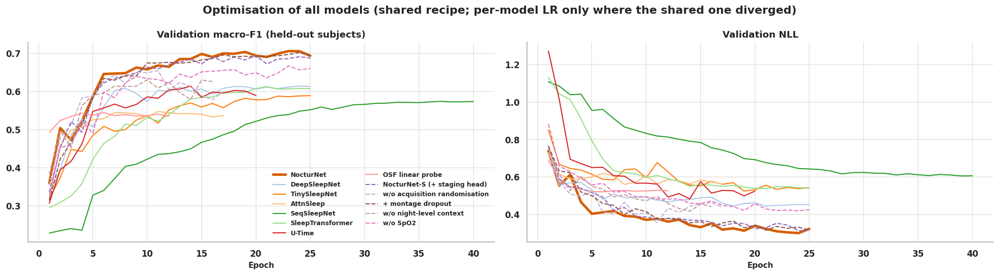

In [12]:
# ===================== STAGE 10  =====================
for name, (grp, _) in MODELS.items():
    if name == PROPOSED: continue
    print("=" * 18, grp, "|", name); T0 = time.time(); run(name); print(f"  {(time.time()-T0)/60:.1f} min")
for name in SEEDED:
    for sd in CFG["seeds"][1:]:
        print("=" * 18, "seed", sd, "|", name); T0 = time.time(); run(name, seed=sd); print(f"  {(time.time()-T0)/60:.1f} min")
set_flag("stage10_comparators")

H = {n: pd.DataFrame(jload(os.path.join(DIRS["checkpoints"], TAG(n), "done.json"))["hist"]) for n in MODELS}
fig, ax = plt.subplots(1, 2, figsize=(18, 5)); cols = dict(zip(MODELS, sns.color_palette("tab20", len(MODELS))))
for n, h in H.items():
    lw, c = (3.2, "#D55E00") if n == PROPOSED else (1.4, cols[n]); ls = "--" if MODELS[n][0] == "Ablation" else "-"
    ax[0].plot(h.epoch, h.val_f1, ls, color=c, lw=lw, label=n); ax[1].plot(h.epoch, h.val_nll, ls, color=c, lw=lw)
ax[0].set_title("Validation macro-F1 (held-out subjects)"); ax[1].set_title("Validation NLL")
for a in ax: a.set_xlabel("Epoch")
ax[0].legend(frameon=False, fontsize=8, ncol=2)
fig.suptitle("Optimisation of all models (shared recipe; per-model LR only where the shared one diverged)", fontweight="bold"); plt.tight_layout(); savefig(fig, "05_training_all")

,test,external
Accuracy,0.8956,0.8396
BalancedAcc,0.7343,0.6580
MacroF1,0.6984,0.5697
WeightedF1,0.8994,0.8408
Kappa,0.6434,0.5121
MCC,0.6455,0.5134
MacroAUROC,0.9635,0.9138
MacroAUPRC,0.7415,0.5408


{'test': {'MacroF1': (np.float64(0.6611), np.float64(0.7305)), 'Accuracy': (np.float64(0.8802), np.float64(0.9132)), 'Kappa': (np.float64(0.6034), np.float64(0.6766))}, 'external': {'MacroF1': (np.float64(0.5157), np.float64(0.632)), 'Accuracy': (np.float64(0.7891), np.float64(0.8808)), 'Kappa': (np.float64(0.4717), np.float64(0.5513))}}


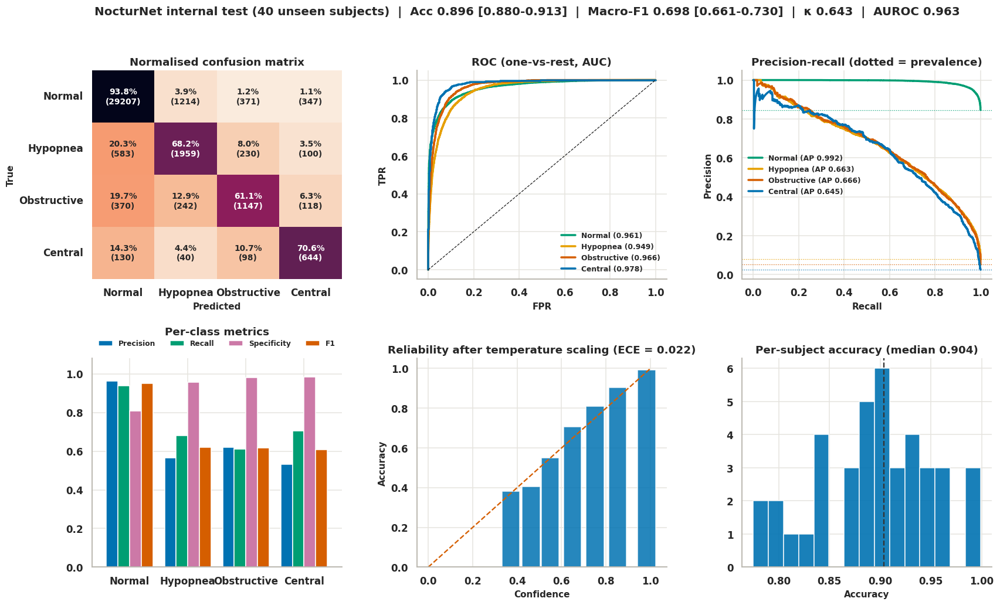

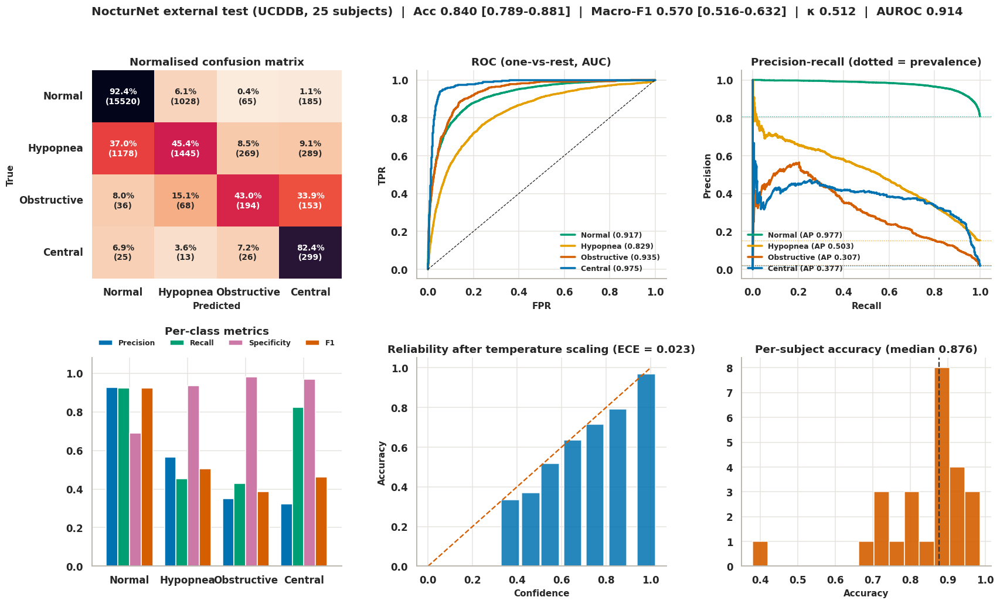

In [13]:
# ===================== STAGE 11 : NocturNet INTERNAL + EXTERNAL EVALUATION =====================
def metrics(y, p):
    yh = p.argmax(1); Yb = np.eye(4)[y]; pres = [k for k in range(4) if 0 < Yb[:, k].sum() < len(y)]
    return dict(Accuracy=accuracy_score(y, yh), BalancedAcc=balanced_accuracy_score(y, yh), MacroF1=f1_score(y, yh, average="macro"),
                WeightedF1=f1_score(y, yh, average="weighted"), Kappa=cohen_kappa_score(y, yh), MCC=matthews_corrcoef(y, yh),
                MacroAUROC=np.mean([roc_auc_score(Yb[:, k], p[:, k]) for k in pres]), MacroAUPRC=np.mean([average_precision_score(Yb[:, k], p[:, k]) for k in pres]))
def groups_of(idx): recs = np.unique(REC[idx]); return recs, {r: idx[REC[idx] == r] for r in recs}
def cluster_boot(idx, p, n=CFG["n_boot"]):
    recs, G = groups_of(idx); rs = np.random.default_rng(0); v = []
    for _ in range(n):
        ii = np.concatenate([G[r] for r in rs.choice(recs, len(recs))]); yh = p[ii].argmax(1)
        v.append([f1_score(Y[ii], yh, average="macro"), accuracy_score(Y[ii], yh), cohen_kappa_score(Y[ii], yh)])
    v = np.array(v); return {k: (np.percentile(v[:, j], 2.5), np.percentile(v[:, j], 97.5)) for j, k in enumerate(["MacroF1", "Accuracy", "Kappa"])}
def per_class(idx, P_):
    y, yh = Y[idx], P_[idx].argmax(1); pr, rc, f1, sup = precision_recall_fscore_support(y, yh, labels=range(4), zero_division=0)
    cm = confusion_matrix(y, yh, labels=range(4)); sp = [(cm.sum() - cm[k].sum() - cm[:, k].sum() + cm[k, k]) / max(1, cm.sum() - cm[k].sum()) for k in range(4)]
    return pd.DataFrame(dict(Precision=pr, Recall=rc, Specificity=sp, F1=f1, Support=sup), index=CFG["classes"]), cm

PRED = np.load(os.path.join(DIRS["results"], f"pred_{TAG(PROPOSED)}.npz")); P = PRED["prob"]
RES = {}
for part in ["test", "external"]:
    ii = IDX[part]; pc, _ = per_class(ii, P); pc.to_csv(os.path.join(DIRS["results"], f"nocturnet_per_class_{part}.csv"))
    RES[part] = dict(overall=metrics(Y[ii], P[ii]), ci=cluster_boot(ii, P), per_class=pc.to_dict())
jdump(RES, os.path.join(DIRS["results"], "nocturnet_results.json"))
display(pd.DataFrame({k: v["overall"] for k, v in RES.items()}).round(4))
print({p: {k: tuple(round(x, 4) for x in v) for k, v in RES[p]["ci"].items()} for p in RES})

def eval_panel(part, title, fname):
    ii = IDX[part]; y, p = Y[ii], P[ii]; yh = p.argmax(1); pc, cm = per_class(ii, P); cn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    r, ci = RES[part]["overall"], RES[part]["ci"]; Yb = np.eye(4)[y]
    fig = plt.figure(figsize=(18, 10)); gs = fig.add_gridspec(2, 3, hspace=.38, wspace=.3)
    ax = fig.add_subplot(gs[0, 0])
    sns.heatmap(cn, annot=np.array([[f"{cn[i,j]*100:.1f}%\n({cm[i,j]})" for j in range(4)] for i in range(4)]), fmt="", cmap="rocket_r", cbar=False,
                ax=ax, xticklabels=CFG["classes"], yticklabels=CFG["classes"], annot_kws={"fontsize": 9})
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Normalised confusion matrix")
    ax = fig.add_subplot(gs[0, 1])
    for k, c in enumerate(CFG["classes"]):
        if 0 < Yb[:, k].sum() < len(y):
            fpr, tpr, _ = roc_curve(Yb[:, k], p[:, k]); ax.plot(fpr, tpr, color=PAL[c], lw=2.3, label=f"{c} ({roc_auc_score(Yb[:, k], p[:, k]):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_title("ROC (one-vs-rest, AUC)"); ax.legend(frameon=False, fontsize=8); ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
    ax = fig.add_subplot(gs[0, 2])
    for k, c in enumerate(CFG["classes"]):
        if 0 < Yb[:, k].sum() < len(y):
            pp, rr, _ = precision_recall_curve(Yb[:, k], p[:, k]); ax.plot(rr, pp, color=PAL[c], lw=2.3, label=f"{c} (AP {average_precision_score(Yb[:, k], p[:, k]):.3f})")
            ax.axhline(Yb[:, k].mean(), color=PAL[c], ls=":", lw=.8)
    ax.set_title("Precision-recall (dotted = prevalence)"); ax.legend(frameon=False, fontsize=8); ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax = fig.add_subplot(gs[1, 0])
    pc[["Precision", "Recall", "Specificity", "F1"]].plot(kind="bar", ax=ax, color=["#0072B2", "#009E73", "#CC79A7", "#D55E00"], width=.8, edgecolor="white")
    ax.set_ylim(0, 1.08); ax.set_title("Per-class metrics", pad=26); ax.tick_params(axis="x", rotation=0)
    ax.legend(frameon=False, ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(.5, 1.12))
    ax = fig.add_subplot(gs[1, 1]); conf = p.max(1); cor = yh == y; bins = np.linspace(0, 1, 11); M_, A_, N_ = [], [], []
    for a, b in zip(bins[:-1], bins[1:]):
        s = (conf > a) & (conf <= b)
        if s.sum(): M_.append(conf[s].mean()); A_.append(cor[s].mean()); N_.append(s.sum())
    ece = sum(n * abs(a - m) for n, a, m in zip(N_, A_, M_)) / len(y)
    ax.bar(M_, A_, width=.08, color="#0072B2", alpha=.85, edgecolor="white"); ax.plot([0, 1], [0, 1], "--", color="#D55E00")
    ax.set_title(f"Reliability after temperature scaling (ECE = {ece:.3f})"); ax.set_xlabel("Confidence"); ax.set_ylabel("Accuracy")
    ax = fig.add_subplot(gs[1, 2])
    ps = pd.DataFrame(dict(r=REC[ii], y=y, p=yh)).groupby("r").apply(lambda d: accuracy_score(d.y, d.p))
    ax.hist(ps, bins=15, color=DBPAL["UCDDB" if part == "external" else "Challenge-2018"], edgecolor="white", alpha=.9)
    ax.axvline(ps.median(), color="#333", ls="--"); ax.set_title(f"Per-subject accuracy (median {ps.median():.3f})"); ax.set_xlabel("Accuracy")
    fig.suptitle(f"{title}  |  Acc {r['Accuracy']:.3f} [{ci['Accuracy'][0]:.3f}-{ci['Accuracy'][1]:.3f}]  |  Macro-F1 {r['MacroF1']:.3f} "
                 f"[{ci['MacroF1'][0]:.3f}-{ci['MacroF1'][1]:.3f}]  |  κ {r['Kappa']:.3f}  |  AUROC {r['MacroAUROC']:.3f}", fontsize=13, fontweight="bold")
    savefig(fig, fname)
eval_panel("test", f"NocturNet internal test ({len(SPL['test'])} unseen subjects)", "06_eval_internal")
eval_panel("external", f"NocturNet external test (UCDDB, {len(SPL['external'])} subjects)", "07_eval_external")
set_flag("stage11_eval")


==== TEST ====


,Accuracy,BalancedAcc,MacroF1,WeightedF1,Kappa,MCC,MacroAUROC,MacroAUPRC,Params_M,Val_F1,dF1,dF1_lo,dF1_hi,dAcc,dAcc_lo,dAcc_hi,Wilcoxon_p
NocturNet,0.8956,0.7343,0.6984,0.8994,0.6434,0.6455,0.9635,0.7415,1.2151,0.7058,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DeepSleepNet,0.8598,0.6275,0.6056,0.8650,0.5213,0.5231,0.9277,0.6063,24.1713,0.6141,0.0928,0.0555,0.1331,0.0358,0.0168,0.0564,0.0008
TinySleepNet,0.8323,0.6043,0.5543,0.8430,0.4575,0.4621,0.9056,0.5553,1.4689,0.5889,0.1441,0.1119,0.1809,0.0633,0.0440,0.0834,0.0000
AttnSleep,0.8413,0.5789,0.5392,0.8439,0.4437,0.4445,0.8999,0.5313,0.5969,0.5473,0.1592,0.1246,0.1965,0.0543,0.0398,0.0667,0.0000
SeqSleepNet,0.8350,0.5694,0.5408,0.8426,0.4480,0.4504,0.8881,0.5335,0.1628,0.5739,0.1576,0.1273,0.1855,0.0605,0.0431,0.0776,0.0000
SleepTransformer,0.8360,0.6167,0.5792,0.8488,0.4787,0.4865,0.9160,0.5935,1.7979,0.6128,0.1192,0.0820,0.1553,0.0596,0.0418,0.0780,0.0000
U-Time,0.8590,0.6069,0.5895,0.8622,0.5071,0.5078,0.9149,0.5972,1.1664,0.6141,0.1089,0.0810,0.1436,0.0365,0.0210,0.0528,0.0000
OSF linear probe,0.8230,0.5490,0.5248,0.8316,0.4094,0.4120,0.8830,0.5025,0.0184,0.5444,0.1736,0.1447,0.2029,0.0725,0.0549,0.0916,0.0000
NocturNet-S (+ staging head),0.8965,0.7142,0.6922,0.9002,0.6449,0.6468,0.9633,0.7303,1.2164,0.6938,0.0062,-0.0069,0.0176,-0.0009,-0.0059,0.0036,0.2766
w/o acquisition randomisation,0.8840,0.7075,0.6576,0.8888,0.6055,0.6076,0.9515,0.6888,1.2151,0.6543,0.0408,0.0261,0.0566,0.0115,0.0067,0.0165,0.0205


  Accuracy: NocturNet 0.8956 vs best baseline DeepSleepNet 0.8598
  MacroF1: NocturNet 0.6984 vs best baseline DeepSleepNet 0.6056
  Kappa: NocturNet 0.6434 vs best baseline DeepSleepNet 0.5213

==== EXTERNAL ====


,Accuracy,BalancedAcc,MacroF1,WeightedF1,Kappa,MCC,MacroAUROC,MacroAUPRC,Params_M,Val_F1,dF1,dF1_lo,dF1_hi,dAcc,dAcc_lo,dAcc_hi,Wilcoxon_p
NocturNet,0.8396,0.6580,0.5697,0.8408,0.5121,0.5134,0.9138,0.5408,1.2151,0.7058,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DeepSleepNet,0.8449,0.5712,0.5411,0.8371,0.4862,0.4912,0.9116,0.5169,24.1713,0.6141,0.0286,-0.0283,0.0858,-0.0053,-0.0195,0.0107,0.0046
TinySleepNet,0.8336,0.5919,0.5018,0.8047,0.4032,0.4277,0.9128,0.5319,1.4689,0.5889,0.0679,0.0219,0.1218,0.0060,-0.0079,0.0196,0.0000
AttnSleep,0.8250,0.5498,0.4805,0.8001,0.3786,0.3978,0.9096,0.5064,0.5969,0.5473,0.0892,0.0356,0.1640,0.0146,-0.0013,0.0330,0.0001
SeqSleepNet,0.8303,0.5350,0.4792,0.8089,0.4010,0.4190,0.9049,0.4894,0.1628,0.5739,0.0905,0.0448,0.1522,0.0093,-0.0067,0.0244,0.0000
SleepTransformer,0.7513,0.5651,0.4634,0.7696,0.3344,0.3400,0.8361,0.4263,1.7979,0.6128,0.1064,0.0485,0.1844,0.0883,0.0555,0.1217,0.0006
U-Time,0.8435,0.6171,0.5483,0.8392,0.4987,0.5031,0.9113,0.5369,1.1664,0.6141,0.0214,-0.0239,0.0728,-0.0039,-0.0160,0.0073,0.0236
OSF linear probe,0.7739,0.5646,0.4168,0.7765,0.3508,0.3643,0.8572,0.4394,0.0184,0.5444,0.1530,0.0999,0.2235,0.0657,0.0422,0.0902,0.0000
NocturNet-S (+ staging head),0.8414,0.6378,0.5620,0.8371,0.4948,0.4980,0.9101,0.5402,1.2164,0.6938,0.0077,-0.0157,0.0294,-0.0018,-0.0084,0.0053,0.3123
w/o acquisition randomisation,0.8387,0.6146,0.5318,0.8323,0.4771,0.4830,0.9168,0.5337,1.2151,0.6543,0.0379,0.0087,0.0743,0.0009,-0.0081,0.0097,0.0000


  Accuracy: NocturNet 0.8396 vs best baseline DeepSleepNet 0.8449
  MacroF1: NocturNet 0.5697 vs best baseline U-Time 0.5483
  Kappa: NocturNet 0.5121 vs best baseline U-Time 0.4987


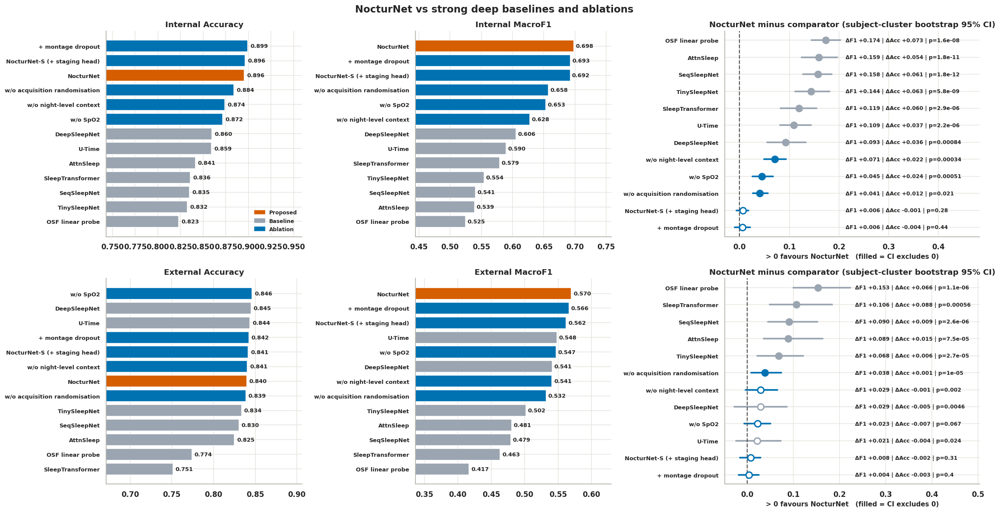

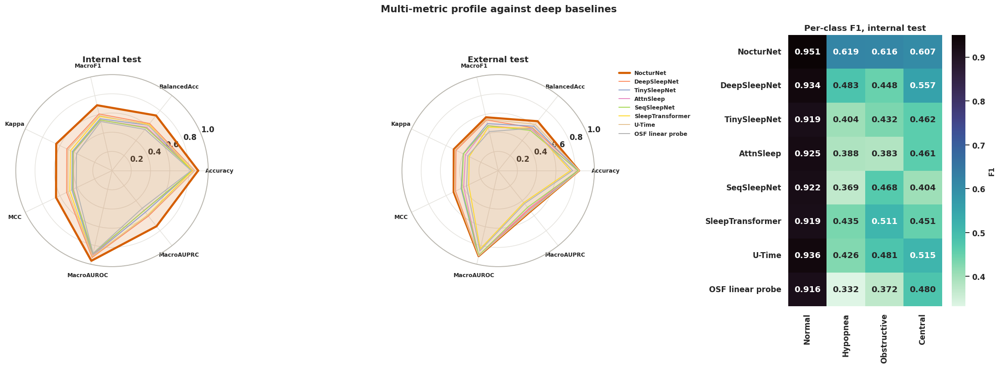


Design selection on VALIDATION subjects only (macro-F1):
NocturNet                        0.7058
NocturNet-S (+ staging head)     0.6938
w/o acquisition randomisation    0.6543
+ montage dropout                0.7018
w/o night-level context          0.6301
w/o SpO2                         0.6668


In [14]:
# ===================== STAGE 12  =====================
PROBS = {n: np.load(os.path.join(DIRS["results"], f"pred_{TAG(n)}.npz"))["prob"] for n in MODELS}
GROUP = {n: g for n, (g, _) in MODELS.items()}
# The displayed delta is the pooled-score difference; bootstrap resamples provide its interval.
def delta_boot(idx, pa, pb, n=CFG["n_boot"]):
    recs, G = groups_of(idx); rs = np.random.default_rng(7); d = []
    for _ in range(n):
        ii = np.concatenate([G[r] for r in rs.choice(recs, len(recs))]); ya, yb = pa[ii].argmax(1), pb[ii].argmax(1)
        d.append([f1_score(Y[ii], ya, average="macro") - f1_score(Y[ii], yb, average="macro"), accuracy_score(Y[ii], ya) - accuracy_score(Y[ii], yb)])
    d = np.array(d); point = np.array([f1_score(Y[idx], pa[idx].argmax(1), average="macro") - f1_score(Y[idx], pb[idx].argmax(1), average="macro"),
                      accuracy_score(Y[idx], pa[idx].argmax(1)) - accuracy_score(Y[idx], pb[idx].argmax(1))])
    return point, np.percentile(d, 2.5, 0), np.percentile(d, 97.5, 0)
def subj_score(idx, p):
    recs, G = groups_of(idx); return np.array([f1_score(Y[G[r]], p[G[r]].argmax(1), average="macro") for r in recs])
TABS = {}
for part in ["test", "external"]:
    ii = IDX[part]; rows = {}
    for n, p in PROBS.items():
        r = metrics(Y[ii], p[ii]); r["Group"] = GROUP[n]; r["Params_M"] = PARAMS[n]
        r["Val_F1"] = jload(os.path.join(DIRS["checkpoints"], TAG(n), "done.json"))["bestf"]
        if n != PROPOSED:
            mu, lo, hi = delta_boot(ii, P, p); r.update(dF1=mu[0], dF1_lo=lo[0], dF1_hi=hi[0], dAcc=mu[1], dAcc_lo=lo[1], dAcc_hi=hi[1])
            a_, b_ = subj_score(ii, P), subj_score(ii, p); r["Wilcoxon_p"] = stats.wilcoxon(a_, b_).pvalue if np.any(a_ != b_) else 1.0
        rows[n] = r
    T = pd.DataFrame(rows).T; num = T.drop(columns="Group").apply(pd.to_numeric, errors="coerce"); TABS[part] = pd.concat([num, T[["Group"]]], axis=1)
    TABS[part].to_csv(os.path.join(DIRS["results"], f"comparison_{part}.csv"))
    with open(os.path.join(DIRS["results"], f"comparison_{part}.tex"), "w") as f: f.write(num.to_latex(float_format="%.4f", na_rep="-"))
    print(f"\n==== {part.upper()} ===="); display(num.round(4))
    best = num.drop(PROPOSED).loc[lambda d: TABS[part].Group.drop(PROPOSED) == "Baseline"]
    for met in ["Accuracy", "MacroF1", "Kappa"]:
        print(f"  {met}: {PROPOSED} {num.loc[PROPOSED, met]:.4f} vs best baseline {best[met].idxmax()} {best[met].max():.4f}")

gc = {"Proposed": "#D55E00", "Baseline": "#9AA5B1", "Ablation": "#0072B2"}
fig, axs = plt.subplots(2, 3, figsize=(21, 11), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for row, part in enumerate(["test", "external"]):
    T = TABS[part]
    for col, met in enumerate(["Accuracy", "MacroF1"]):
        S = T.sort_values(met); ax = axs[row, col]
        ax.barh(S.index, S[met], color=[gc[g] for g in S.Group], edgecolor="white")
        for i, v in enumerate(S[met]): ax.text(v + .003, i, f"{v:.3f}", va="center", fontsize=8.5)
        lo = max(0, S[met].min() - .08); ax.set_xlim(lo, min(1, S[met].max() + .06)); ax.set_title(f"{'Internal' if row == 0 else 'External'} {met}")
        ax.tick_params(axis="y", labelsize=8.5)
    D = T.drop(PROPOSED).sort_values("dF1"); ax = axs[row, 2]
    for i, (n, r) in enumerate(D.iterrows()):
        c = gc[r.Group]; sig = r.dF1_lo > 0 or r.dF1_hi < 0
        ax.plot([r.dF1_lo, r.dF1_hi], [i, i], color=c, lw=2.5); ax.scatter(r.dF1, i, s=90, color=c if sig else "white", edgecolor=c, lw=2, zorder=3)
        ax.text(D.dF1_hi.max() + .01, i, f"ΔF1 {r.dF1:+.3f} | ΔAcc {r.dAcc:+.3f} | p={r.Wilcoxon_p:.2g}", va="center", fontsize=8)
    ax.axvline(0, color="#555", ls="--"); ax.set_yticks(range(len(D))); ax.set_yticklabels(D.index, fontsize=8.5)
    ax.set_xlim(min(D.dF1_lo.min(), 0) - .02, max(D.dF1_hi.max(), 0) + .28)
    ax.set_title("NocturNet minus comparator (subject-cluster bootstrap 95% CI)"); ax.set_xlabel("> 0 favours NocturNet   (filled = CI excludes 0)")
axs[0, 0].legend(handles=[Patch(color=c, label=g) for g, c in gc.items()], frameon=False, loc="lower right", fontsize=8)
fig.suptitle("NocturNet vs strong deep baselines and ablations", fontsize=15, fontweight="bold"); plt.tight_layout(); savefig(fig, "08_comparison")

keys = ["Accuracy", "BalancedAcc", "MacroF1", "Kappa", "MCC", "MacroAUROC", "MacroAUPRC"]
fig = plt.figure(figsize=(20, 7.5)); ang = np.linspace(0, 2 * np.pi, len(keys), endpoint=False).tolist(); ang += ang[:1]
base = [n for n in MODELS if GROUP[n] in ("Proposed", "Baseline")]; pal = sns.color_palette("Set2", len(base))
for j, part in enumerate(["test", "external"]):
    ax = fig.add_subplot(1, 3, j + 1, polar=True); T = TABS[part]
    for c, n in zip(pal, base):
        v = T.loc[n, keys].astype(float).tolist(); v += v[:1]; isP = n == PROPOSED
        ax.plot(ang, v, lw=3 if isP else 1.3, color="#D55E00" if isP else c, label=n); ax.fill(ang, v, alpha=.15 if isP else .02, color="#D55E00" if isP else c)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(keys, fontsize=8); ax.set_ylim(0, 1); ax.set_title(f"{'Internal' if j == 0 else 'External'} test", pad=18)
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.1, 1.05))
ax = fig.add_subplot(1, 3, 3)
pcf = pd.DataFrame({n: per_class(IDX["test"], PROBS[n])[0].F1 for n in base}).T
sns.heatmap(pcf, annot=True, fmt=".3f", cmap="mako_r", ax=ax, cbar_kws={"label": "F1"}); ax.set_title("Per-class F1, internal test")
fig.suptitle("Multi-metric profile against deep baselines", fontsize=14, fontweight="bold"); plt.tight_layout(); savefig(fig, "09_radar_perclass")
VAL = pd.Series({n: TABS["test"].loc[n, "Val_F1"] for n in [PROPOSED] + [k for k in MODELS if GROUP[k] == "Ablation"]})
print("\nDesign selection on VALIDATION subjects only (macro-F1):"); print(VAL.round(4).to_string())
set_flag("stage12_comparison")

Accuracy         MacroF1           Kappa          \
                          mean     std    mean     std    mean     std   
part     model                                                           
external DeepSleepNet   0.8423  0.0029  0.5243  0.0155  0.4614  0.0276   
         NocturNet      0.8382  0.0017  0.5568  0.0112  0.4943  0.0198   
         U-Time         0.8406  0.0025  0.5433  0.0083  0.4816  0.0204   
test     DeepSleepNet   0.8586  0.0021  0.5943  0.0111  0.5108  0.0104   
         NocturNet      0.8947  0.0067  0.6880  0.0122  0.6335  0.0135   
         U-Time         0.8522  0.0060  0.5832  0.0055  0.4995  0.0067   

                      MacroAUROC          
                            mean     std  
part     model                            
external DeepSleepNet     0.9165  0.0043  
         NocturNet        0.9138  0.0076  
         U-Time           0.9107  0.0051  
test     DeepSleepNet     0.9271  0.0006  
         NocturNet        0.9617  0.0018  
         U-Time           0.9154  0.0034

test     NocturNet - DeepSleepNet: ΔF1 per seed [0.0928 0.1078 0.0805] | mean +0.0937 | wins 3/3
test     NocturNet - U-Time      : ΔF1 per seed [0.1089 0.1105 0.0951] | mean +0.1048 | wins 3/3
external NocturNet - DeepSleepNet: ΔF1 per seed [0.0286 0.0386 0.0304] | mean +0.0325 | wins 3/3
external NocturNet - U-Time      : ΔF1 per seed [0.0214 0.0156 0.0036] | mean +0.0135 | wins 3/3


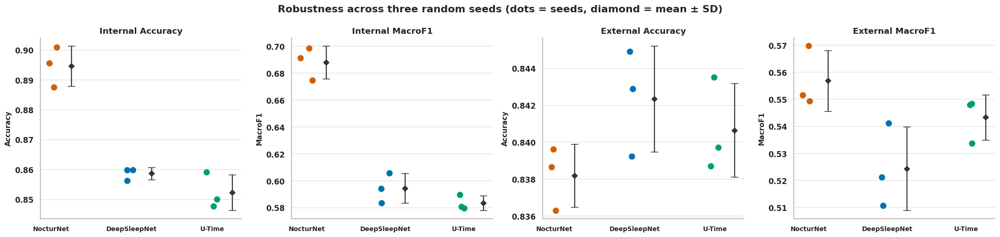

In [15]:
# ===================== STAGE 12b  =====================
rows = []
for n in SEEDED:
    for sd in CFG["seeds"]:
        pp = np.load(os.path.join(DIRS["results"], f"pred_{TAG(n, sd)}.npz"))["prob"]
        for part in ["test", "external"]:
            r = metrics(Y[IDX[part]], pp[IDX[part]]); rows.append(dict(model=n, seed=sd, part=part, **r))
SEEDS = pd.DataFrame(rows); SEEDS.to_csv(os.path.join(DIRS["results"], "seed_runs.csv"), index=False)
SUMM = SEEDS.groupby(["part", "model"])[["Accuracy", "MacroF1", "Kappa", "MacroAUROC"]].agg(["mean", "std"]).round(4)
SUMM.to_csv(os.path.join(DIRS["results"], "seed_summary.csv")); display(SUMM)
for part in ["test", "external"]:
    for b in SEEDED[1:]:
        a_ = SEEDS[(SEEDS.part == part) & (SEEDS.model == PROPOSED)].set_index("seed"); b_ = SEEDS[(SEEDS.part == part) & (SEEDS.model == b)].set_index("seed")
        d = (a_.MacroF1 - b_.MacroF1); print(f"{part:8s} NocturNet - {b:12s}: ΔF1 per seed {np.round(d.values, 4)} | mean {d.mean():+.4f} | wins {(d > 0).sum()}/{len(d)}")
fig, axs = plt.subplots(1, 4, figsize=(20, 4.8), sharey=False); spal = {n: ("#D55E00" if n == PROPOSED else c) for n, c in zip(SEEDED, ["#D55E00", "#0072B2", "#009E73"])}
for ax, (part, met) in zip(axs, [("test", "Accuracy"), ("test", "MacroF1"), ("external", "Accuracy"), ("external", "MacroF1")]):
    d = SEEDS[SEEDS.part == part]
    sns.stripplot(data=d, x="model", y=met, hue="model", palette=spal, size=9, ax=ax, legend=False, jitter=.08)
    for i, n in enumerate(SEEDED):
        v = d[d.model == n][met]; ax.errorbar(i + .25, v.mean(), yerr=v.std(), fmt="D", color="#333", capsize=5, ms=6)
    ax.set_title(f"{'Internal' if part == 'test' else 'External'} {met}"); ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=9)
fig.suptitle("Robustness across three random seeds (dots = seeds, diamond = mean ± SD)", fontweight="bold"); plt.tight_layout(); savefig(fig, "09b_seed_robustness")
set_flag("stage12b_seeds")

VALIDATION macro-F1 per montage:


,full PSG,no SpO2,no EEG,no airflow,airflow + one belt,belts only,airflow only,"cardio-respiratory, no SpO2",mean
NocturNet,0.7059,0.6450,0.6860,0.6216,0.6126,0.5582,0.4568,0.6233,0.6137
NocturNet-S (+ staging head),0.6999,0.6550,0.6909,0.6187,0.6076,0.5755,0.4588,0.6422,0.6186
+ montage dropout,0.7034,0.6508,0.7000,0.6427,0.6150,0.5680,0.4458,0.6574,0.6229
w/o acquisition randomisation,0.6595,0.6026,0.6527,0.5897,0.5690,0.5360,0.4166,0.5847,0.5764
U-Time,0.6176,0.5729,0.6152,0.5513,0.5589,0.5104,0.4374,0.5750,0.5548
DeepSleepNet,0.6153,0.5649,0.6104,0.5682,0.5310,0.5233,0.4317,0.5690,0.5517
TinySleepNet,0.5955,0.5690,0.5924,0.5431,0.5467,0.5119,0.4158,0.5693,0.5430
SeqSleepNet,0.5780,0.5727,0.5683,0.4932,0.5211,0.4830,0.4312,0.5658,0.5267


TEST macro-F1 per montage:


,full PSG,no SpO2,no EEG,no airflow,airflow + one belt,belts only,airflow only,"cardio-respiratory, no SpO2",mean
NocturNet,0.6984,0.6500,0.6810,0.6094,0.5846,0.5470,0.4543,0.6301,0.6068
NocturNet-S (+ staging head),0.6922,0.6552,0.6845,0.6045,0.5918,0.5494,0.4597,0.6244,0.6077
+ montage dropout,0.6925,0.6416,0.6855,0.6077,0.5861,0.5427,0.4456,0.6445,0.6058
w/o acquisition randomisation,0.6576,0.6022,0.6389,0.5800,0.5428,0.5083,0.4209,0.5776,0.5661
U-Time,0.5895,0.5675,0.5891,0.5543,0.5381,0.5278,0.4647,0.5694,0.5500
DeepSleepNet,0.6056,0.5636,0.6084,0.5644,0.5110,0.5299,0.4256,0.5634,0.5465
TinySleepNet,0.5543,0.5564,0.5530,0.5251,0.5117,0.5033,0.4215,0.5509,0.5220
SeqSleepNet,0.5408,0.5296,0.5403,0.4608,0.4881,0.4439,0.4229,0.5309,0.4947


Model selection = highest full-montage VALIDATION macro-F1 (same criterion as every earlier design decision):
                               val_macroF1  val_mean_over_montages
NocturNet                           0.7058                  0.6137
+ montage dropout                   0.7018                  0.6229
NocturNet-S (+ staging head)        0.6938                  0.6186
w/o acquisition randomisation       0.6543                  0.5764
  -> NocturNet


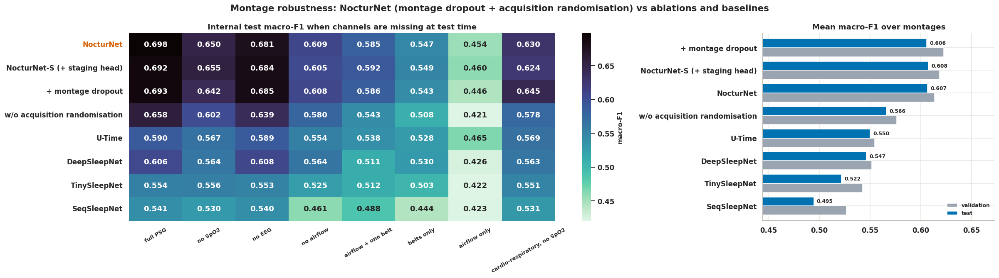

In [16]:
# ===================== STAGE 12c  =====================
EVAL_SETS = {k: v for k, v in MONTAGES.items() if k != "HSAT: airflow+belts+SpO2"}
CANDS = [n for n in [PROPOSED, NSV, "+ montage dropout", "w/o acquisition randomisation",
                     "U-Time", "DeepSleepNet", "TinySleepNet", "SeqSleepNet"] if os.path.exists(os.path.join(DIRS["checkpoints"], TAG(n), "done.json"))]
ROB_P = os.path.join(DIRS["results"], "montage_robustness_bytag.json"); ROB = jload(ROB_P) if os.path.exists(ROB_P) else {}
for n in CANDS:
    tg = TAG(n)
    if tg in ROB and all(m in ROB[tg] for m in EVAL_SETS): continue
    mdl = MODELS[n][1]().to(DEV); mdl.load_state_dict(torch.load(os.path.join(DIRS["checkpoints"], tg, "best.pt"), map_location=DEV))
    cal = np.load(os.path.join(DIRS["results"], f"pred_{tg}.npz")); ROB[tg] = {}
    for mname, keep in EVAL_SETS.items():
        EVAL_KEEP = keep
        try: lp, _ = predict(mdl, SPL["val"] + SPL["test"])
        finally: EVAL_KEEP = None
        p = softmax_np(lp / float(cal["T"]) + cal["bias"])
        ROB[tg][mname] = {part: f1_score(Y[IDX[part]], p[IDX[part]].argmax(1), average="macro") for part in ["val", "test"]}
    jdump(ROB, ROB_P); del mdl; print("  montage sweep:", n)
# The full-PSG reference uses the same calibrated predictions as the primary
# evaluation. Refresh it even when the montage sweep is loaded from cache.
for n in CANDS:
    with np.load(os.path.join(DIRS["results"], f"pred_{TAG(n)}.npz")) as cached:
        full_prob = cached["prob"]
        ROB[TAG(n)]["full PSG"] = {
            part: f1_score(Y[IDX[part]], full_prob[IDX[part]].argmax(1), average="macro")
            for part in ("val", "test")
        }
jdump(ROB, ROB_P)

RV = pd.DataFrame({n: {m: ROB[TAG(n)][m]["val"] for m in EVAL_SETS} for n in CANDS}).T
RT = pd.DataFrame({n: {m: ROB[TAG(n)][m]["test"] for m in EVAL_SETS} for n in CANDS}).T
RV["mean"], RT["mean"] = RV.mean(1), RT.mean(1)
RV.to_csv(os.path.join(DIRS["results"], "montage_robustness_val.csv")); RT.to_csv(os.path.join(DIRS["results"], "montage_robustness_test.csv"))
print("VALIDATION macro-F1 per montage:"); display(RV.round(4)); print("TEST macro-F1 per montage:"); display(RT.round(4))
own = [n for n in CANDS if n in (PROPOSED, NSV, "+ montage dropout", "w/o acquisition randomisation")]
VF = pd.Series({n: jload(os.path.join(DIRS["checkpoints"], TAG(n), "done.json"))["bestf"] for n in own})
SEL = VF.idxmax()
print("Model selection = highest full-montage VALIDATION macro-F1 (same criterion as every earlier design decision):")
print(pd.DataFrame({"val_macroF1": VF, "val_mean_over_montages": RV.loc[own, "mean"]}).round(4).sort_values("val_macroF1", ascending=False))
print(f"  -> {SEL}" + ("" if SEL == PROPOSED else "   NOTE: differs from PROPOSED; report this."))
jdump(dict(rule="max full-montage validation macro-F1", selected=SEL, val_f1=VF.to_dict(), val_mean_montages={n: RV.loc[n, "mean"] for n in own},
           montage_p=CFG["montage_p"], dg_p=CFG["dg_p"]), os.path.join(DIRS["results"], "robust_selection.json"))

fig, axs = plt.subplots(1, 2, figsize=(22, 6.2), gridspec_kw={"width_ratios": [2.3, 1]})
sns.heatmap(RT.drop(columns="mean"), annot=True, fmt=".3f", cmap="mako_r", ax=axs[0], cbar_kws={"label": "macro-F1"})
axs[0].set_title("Internal test macro-F1 when channels are missing at test time"); axs[0].tick_params(axis="x", rotation=30, labelsize=8.5)
for t in axs[0].get_yticklabels():
    if t.get_text() == PROPOSED: t.set_fontweight("bold"); t.set_color("#D55E00")
d = pd.DataFrame({"validation": RV["mean"], "test": RT["mean"]}).sort_values("validation")
d.plot(kind="barh", ax=axs[1], color=["#9AA5B1", "#0072B2"], edgecolor="white", width=.8)
for i, v in enumerate(d.test): axs[1].text(v + .003, i + .2, f"{v:.3f}", va="center", fontsize=8)
axs[1].set_xlim(d.values.min() - .05, d.values.max() + .05); axs[1].set_title("Mean macro-F1 over montages"); axs[1].legend(frameon=False, fontsize=8)
fig.suptitle("Montage robustness: NocturNet (montage dropout + acquisition randomisation) vs ablations and baselines", fontsize=14, fontweight="bold")
plt.tight_layout(); savefig(fig, "09c_montage_robustness"); set_flag("stage12c_robustness")

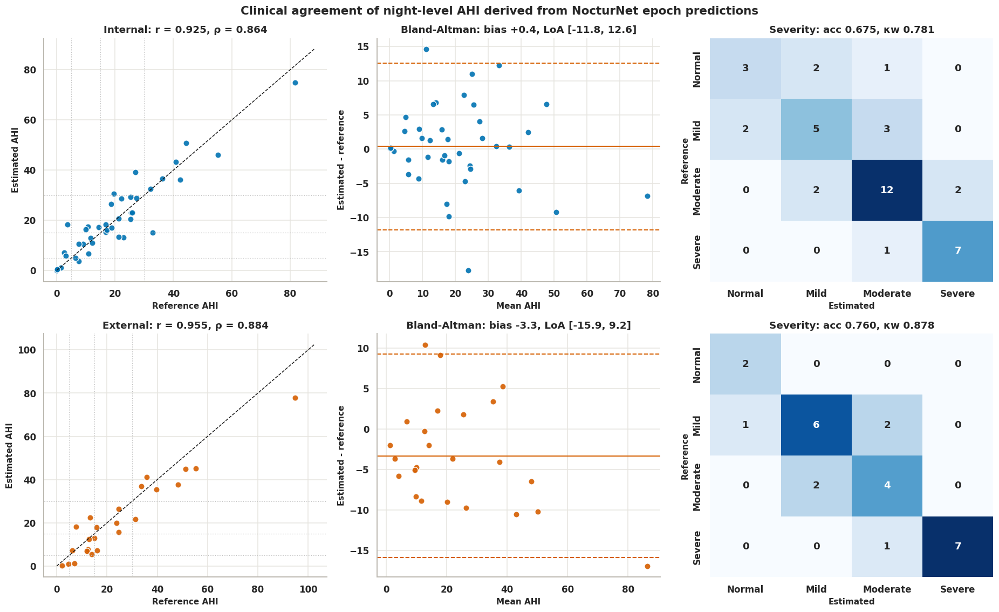

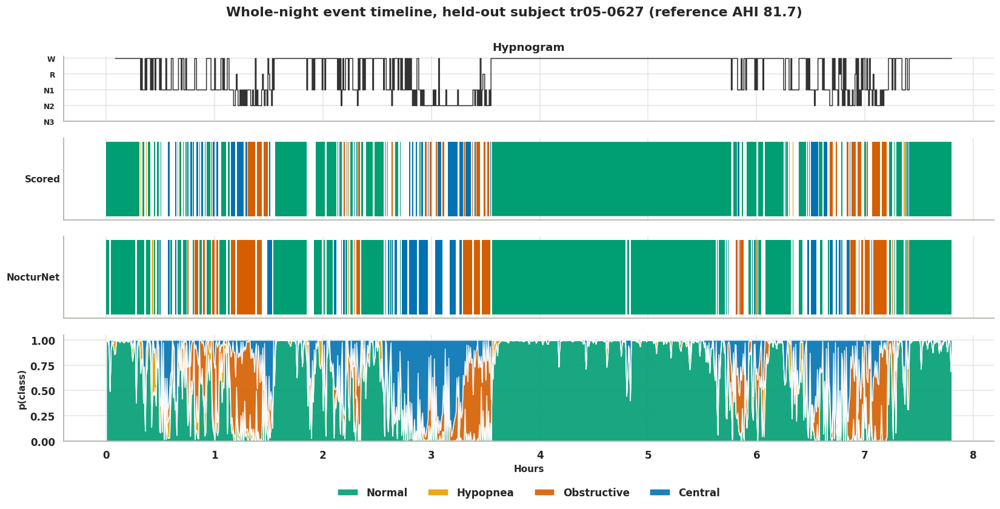

In [17]:
# ===================== STAGE 13 =====================
tr_ix = IDX["train"]; k_ev = META.loc[SPL["train"], [f"n_{c}" for c in CFG["classes"][1:]]].values.sum() / max((Y[tr_ix] > 0).sum(), 1)
def ahi_table(part):
    rows = []
    for r in SPL[part]:
        a, b = SPAN[r]; sl = np.isin(STG[a:b], ["N1", "N2", "N3", "R"]); sh = max(sl.sum() * 30 / 3600, 1e-3)
        rows.append(dict(rec=r, true=META.loc[r, "ahi"], pred=k_ev * ((P[a:b].argmax(1) > 0) & sl).sum() / sh))
    return pd.DataFrame(rows).set_index("rec")
sev = lambda a: np.digitize(a, [5, 15, 30]); SEV = ["Normal", "Mild", "Moderate", "Severe"]
fig, axs = plt.subplots(2, 3, figsize=(17, 10.5)); AHI = {}
for row, part in enumerate(["test", "external"]):
    t = ahi_table(part); AHI[part] = t; col = DBPAL["UCDDB" if part == "external" else "Challenge-2018"]
    ok = t.pred.std() > 0 and t.true.std() > 0
    r_ = stats.pearsonr(t.true, t.pred)[0] if ok else np.nan; rho = stats.spearmanr(t.true, t.pred)[0] if ok else np.nan
    ax = axs[row, 0]; lim = max(t.true.max(), t.pred.max()) * 1.08
    ax.scatter(t.true, t.pred, s=55, color=col, edgecolor="white", alpha=.9); ax.plot([0, lim], [0, lim], "k--", lw=1)
    for x in (5, 15, 30): ax.axvline(x, color="#bbb", ls=":", lw=.8); ax.axhline(x, color="#bbb", ls=":", lw=.8)
    ax.set_xlabel("Reference AHI"); ax.set_ylabel("Estimated AHI"); ax.set_title(f"{'Internal' if row == 0 else 'External'}: r = {r_:.3f}, ρ = {rho:.3f}")
    ax = axs[row, 1]; mean_, diff = (t.true + t.pred) / 2, t.pred - t.true; md, sd = diff.mean(), diff.std()
    ax.scatter(mean_, diff, s=55, color=col, edgecolor="white", alpha=.9)
    for v, ls in [(md, "-"), (md + 1.96 * sd, "--"), (md - 1.96 * sd, "--")]: ax.axhline(v, color="#D55E00", ls=ls, lw=1.3)
    ax.set_title(f"Bland-Altman: bias {md:+.1f}, LoA [{md-1.96*sd:.1f}, {md+1.96*sd:.1f}]"); ax.set_xlabel("Mean AHI"); ax.set_ylabel("Estimated - reference")
    ax = axs[row, 2]; cm = confusion_matrix(sev(t.true), sev(t.pred), labels=range(4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=SEV, yticklabels=SEV)
    ax.set_title(f"Severity: acc {np.trace(cm)/cm.sum():.3f}, κw {cohen_kappa_score(sev(t.true), sev(t.pred), weights='quadratic'):.3f}")
    ax.set_xlabel("Estimated"); ax.set_ylabel("Reference")
    t.to_csv(os.path.join(DIRS["results"], f"ahi_{part}.csv"))
fig.suptitle("Clinical agreement of night-level AHI derived from NocturNet epoch predictions", fontsize=14, fontweight="bold")
plt.tight_layout(); savefig(fig, "10_ahi_agreement")

r0 = AHI["test"].true.idxmax(); a, b = SPAN[r0]; hr = np.arange(b - a) * 30 / 3600
fig, ax = plt.subplots(4, 1, figsize=(18, 7.5), sharex=True, gridspec_kw={"height_ratios": [.8, 1, 1, 1.3]})
stg_map = {"W": 4, "R": 3, "N1": 2, "N2": 1, "N3": 0, "U": np.nan}; ax[0].step(hr, [stg_map.get(s, np.nan) for s in STG[a:b]], color="#333", lw=1)
ax[0].set_yticks([0, 1, 2, 3, 4]); ax[0].set_yticklabels(["N3", "N2", "N1", "R", "W"], fontsize=8); ax[0].set_title("Hypnogram")
for axx, lab, v in [(ax[1], "Scored", Y[a:b]), (ax[2], "NocturNet", P[a:b].argmax(1))]:
    for k in range(4): axx.fill_between(hr, 0, 1, where=v == k, color=CCOL[k], step="mid", lw=0)
    axx.set_yticks([]); axx.set_ylabel(lab, rotation=0, ha="right", va="center", fontweight="bold")
ax[3].stackplot(hr, P[a:b].T, colors=CCOL, alpha=.9, labels=CFG["classes"]); ax[3].set_ylabel("p(class)"); ax[3].set_xlabel("Hours")
ax[3].legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.35))
fig.suptitle(f"Whole-night event timeline, held-out subject {r0} (reference AHI {AHI['test'].loc[r0,'true']:.1f})", fontweight="bold")
savefig(fig, "11_night_timeline")
jdump({p: dict(pearson=stats.pearsonr(t.true, t.pred)[0], spearman=stats.spearmanr(t.true, t.pred)[0],
               severity_acc=float(np.mean(sev(t.true) == sev(t.pred))), severity_kappa_w=cohen_kappa_score(sev(t.true), sev(t.pred), weights="quadratic"))
       for p, t in AHI.items()}, os.path.join(DIRS["results"], "ahi_agreement.json"))
set_flag("stage13_ahi")

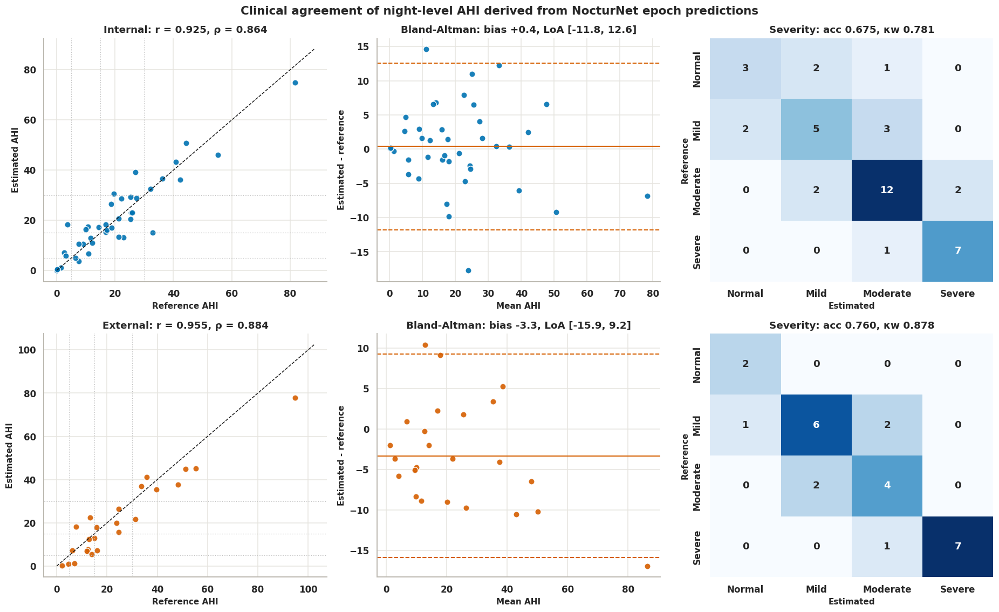

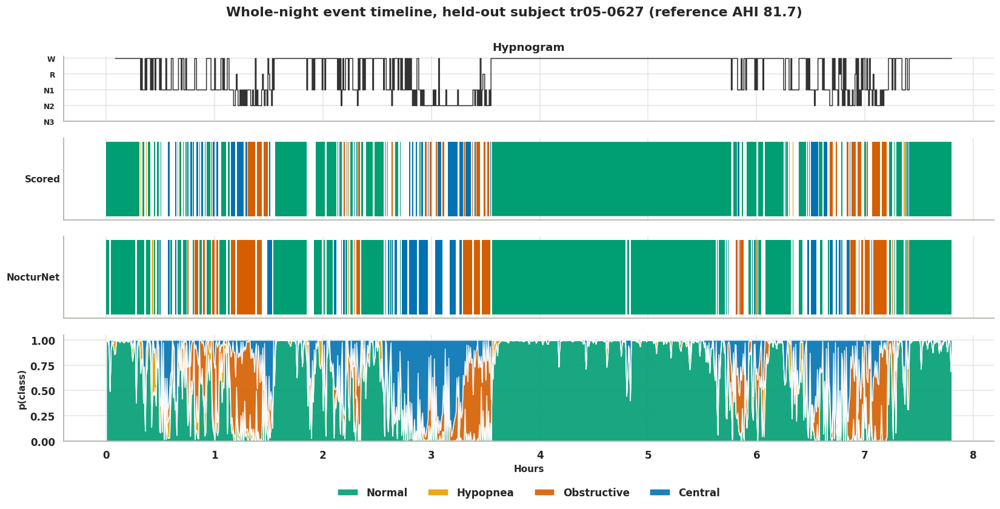

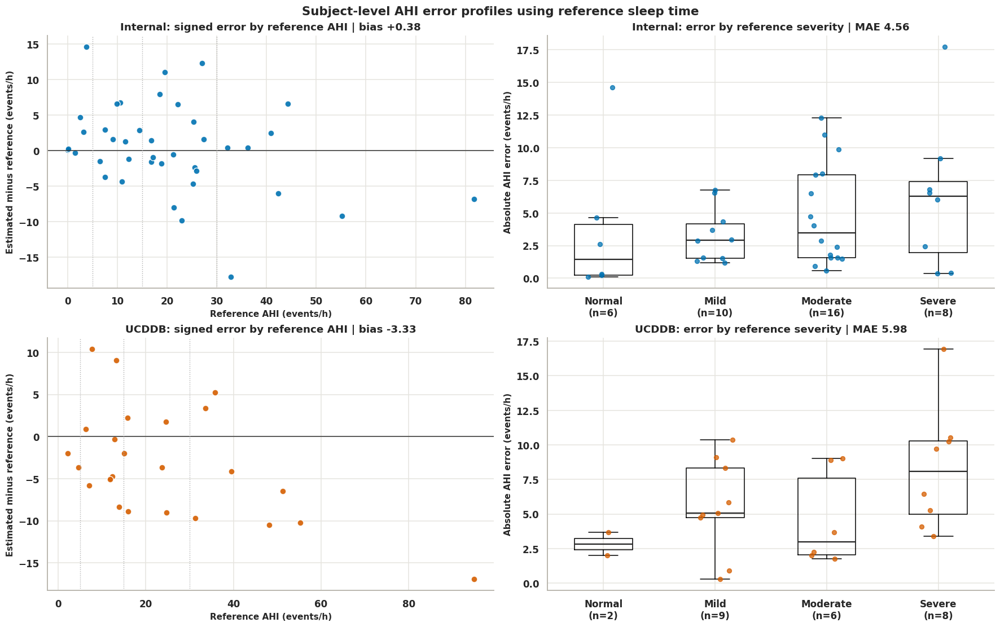

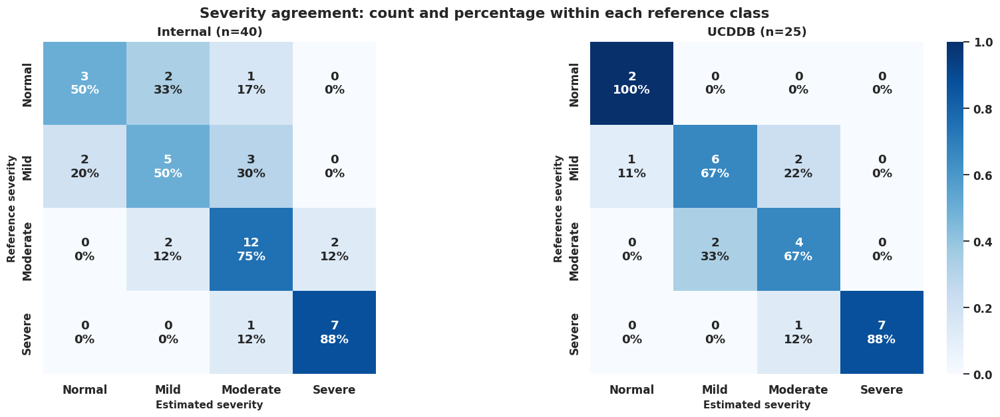

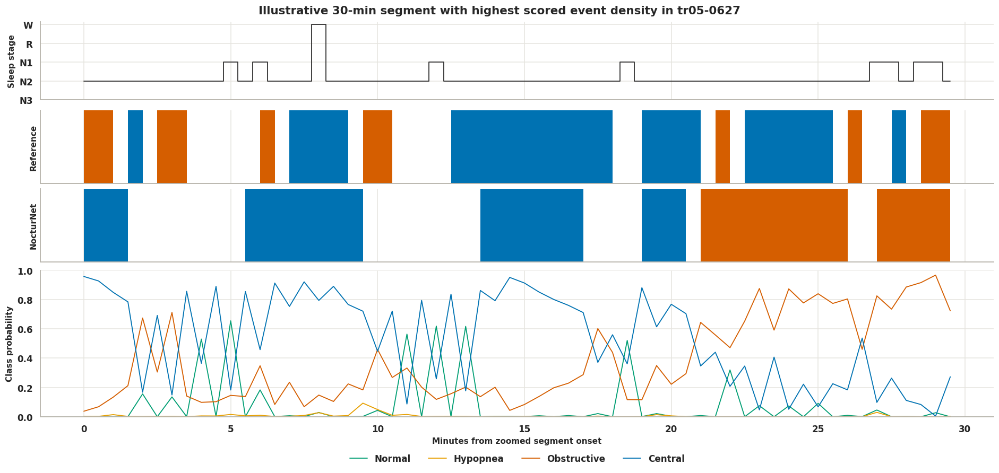

In [29]:
# ===================== STAGE 13 =====================
tr_ix = IDX["train"]
k_ev = META.loc[SPL["train"], [f"n_{c}" for c in CFG["classes"][1:]]].values.sum() / max((Y[tr_ix] > 0).sum(), 1)

def ahi_table(part):
    rows = []
    for r in SPL[part]:
        a, b = SPAN[r]
        sl = np.isin(STG[a:b], ["N1", "N2", "N3", "R"])
        sh = max(sl.sum() * 30 / 3600, 1e-3)
        rows.append(dict(
            rec=r,
            true=META.loc[r, "ahi"],
            pred=k_ev * ((P[a:b].argmax(1) > 0) & sl).sum() / sh,
        ))
    return pd.DataFrame(rows).set_index("rec")

sev = lambda a: np.digitize(a, [5, 15, 30])
SEV = ["Normal", "Mild", "Moderate", "Severe"]
AHI = {}

# AHI correlation, Bland–Altman agreement and severity confusion matrices
fig, axs = plt.subplots(2, 3, figsize=(17, 10.5))
for row, part in enumerate(["test", "external"]):
    t = ahi_table(part)
    AHI[part] = t
    col = DBPAL["UCDDB" if part == "external" else "Challenge-2018"]
    ok = t.pred.std() > 0 and t.true.std() > 0
    r_ = stats.pearsonr(t.true, t.pred)[0] if ok else np.nan
    rho = stats.spearmanr(t.true, t.pred)[0] if ok else np.nan

    ax = axs[row, 0]
    lim = max(t.true.max(), t.pred.max()) * 1.08
    ax.scatter(t.true, t.pred, s=55, color=col, edgecolor="white", alpha=.9)
    ax.plot([0, lim], [0, lim], "k--", lw=1)
    for x in (5, 15, 30):
        ax.axvline(x, color="#bbb", ls=":", lw=.8)
        ax.axhline(x, color="#bbb", ls=":", lw=.8)
    ax.set_xlabel("Reference AHI")
    ax.set_ylabel("Estimated AHI")
    ax.set_title(f"{'Internal' if row == 0 else 'External'}: r = {r_:.3f}, ρ = {rho:.3f}")

    ax = axs[row, 1]
    mean_, diff = (t.true + t.pred) / 2, t.pred - t.true
    md, sd = diff.mean(), diff.std()
    ax.scatter(mean_, diff, s=55, color=col, edgecolor="white", alpha=.9)
    for v, ls in [(md, "-"), (md + 1.96 * sd, "--"), (md - 1.96 * sd, "--")]:
        ax.axhline(v, color="#D55E00", ls=ls, lw=1.3)
    ax.set_title(f"Bland-Altman: bias {md:+.1f}, LoA [{md-1.96*sd:.1f}, {md+1.96*sd:.1f}]")
    ax.set_xlabel("Mean AHI")
    ax.set_ylabel("Estimated - reference")

    ax = axs[row, 2]
    cm = confusion_matrix(sev(t.true), sev(t.pred), labels=range(4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=SEV, yticklabels=SEV)
    kw = cohen_kappa_score(sev(t.true), sev(t.pred), weights="quadratic")
    ax.set_title(f"Severity: acc {np.trace(cm)/cm.sum():.3f}, κw {kw:.3f}")
    ax.set_xlabel("Estimated")
    ax.set_ylabel("Reference")

    t.to_csv(os.path.join(DIRS["results"], f"ahi_{part}.csv"))

fig.suptitle(
    "Clinical agreement of night-level AHI derived from NocturNet epoch predictions",
    fontsize=14, fontweight="bold",
)
plt.tight_layout()
savefig(fig, "10_ahi_agreement")

# Whole-night timeline
r0 = AHI["test"].true.idxmax()
a, b = SPAN[r0]
hr = np.arange(b - a) * 30 / 3600
stg_map = {"W": 4, "R": 3, "N1": 2, "N2": 1, "N3": 0, "U": np.nan}

fig, ax = plt.subplots(
    4, 1, figsize=(18, 7.5), sharex=True,
    gridspec_kw={"height_ratios": [.8, 1, 1, 1.3]},
)
ax[0].step(hr, [stg_map.get(s, np.nan) for s in STG[a:b]], color="#333", lw=1)
ax[0].set_yticks([0, 1, 2, 3, 4])
ax[0].set_yticklabels(["N3", "N2", "N1", "R", "W"], fontsize=8)
ax[0].set_title("Hypnogram")

for axx, lab, values in [
    (ax[1], "Scored", Y[a:b]),
    (ax[2], "NocturNet", P[a:b].argmax(1)),
]:
    for k in range(4):
        axx.fill_between(hr, 0, 1, where=values == k, color=CCOL[k], step="mid", lw=0)
    axx.set_yticks([])
    axx.set_ylabel(lab, rotation=0, ha="right", va="center", fontweight="bold")

ax[3].stackplot(hr, P[a:b].T, colors=CCOL, alpha=.9, labels=CFG["classes"])
ax[3].set_ylabel("p(class)")
ax[3].set_xlabel("Hours")
ax[3].legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.35))
fig.suptitle(
    f"Whole-night event timeline, held-out subject {r0} "
    f"(reference AHI {AHI['test'].loc[r0, 'true']:.1f})",
    fontweight="bold",
)
savefig(fig, "11_night_timeline")

# Signed and absolute AHI errors
fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)
for row, part in enumerate(("test", "external")):
    t = AHI[part]
    label = "Internal" if part == "test" else "UCDDB"
    color = DBPAL["Challenge-2018" if part == "test" else "UCDDB"]
    error = t.pred.to_numpy() - t.true.to_numpy()
    reference = t.true.to_numpy()

    ax = axes[row, 0]
    ax.scatter(reference, error, s=52, color=color, edgecolor="white", alpha=.9)
    ax.axhline(0, color="#333333", lw=1)
    for boundary in (5, 15, 30):
        ax.axvline(boundary, color="#AAAAAA", ls=":", lw=.9)
    ax.set_xlabel("Reference AHI (events/h)")
    ax.set_ylabel("Estimated minus reference (events/h)")
    ax.set_title(f"{label}: signed error by reference AHI | bias {error.mean():+.2f}")

    ax = axes[row, 1]
    severity = sev(reference)
    groups = [np.abs(error[severity == k]) for k in range(4)]
    positions = np.arange(1, 5)
    ax.boxplot(
        groups, positions=positions, widths=.52, showfliers=False,
        medianprops={"color": "#252525", "linewidth": 1.5},
    )
    rng = np.random.default_rng(130 + row)
    for k, values in enumerate(groups):
        if len(values):
            ax.scatter(
                np.full(len(values), positions[k]) + rng.uniform(-.16, .16, len(values)),
                values, s=26, color=color, alpha=.75, zorder=3,
            )
    ax.set_xticks(
        positions,
        [f"{name}\n(n={len(values)})" for name, values in zip(SEV, groups)],
    )
    ax.set_ylabel("Absolute AHI error (events/h)")
    ax.set_title(f"{label}: error by reference severity | MAE {np.abs(error).mean():.2f}")

fig.suptitle(
    "Subject-level AHI error profiles using reference sleep time",
    fontsize=14, fontweight="bold",
)
savefig(fig, "10b_ahi_error_profiles")

# Severity confusion matrices as within-class percentages
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), constrained_layout=True)
for ax, part in zip(axes, ("test", "external")):
    t = AHI[part]
    cm = confusion_matrix(sev(t.true), sev(t.pred), labels=range(4))
    pct = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    labels = np.array([
        [f"{cm[i, j]}\n{pct[i, j]:.0%}" for j in range(4)]
        for i in range(4)
    ])
    sns.heatmap(
        pct, annot=labels, fmt="", vmin=0, vmax=1, cmap="Blues", square=True,
        cbar=(part == "external"), ax=ax, xticklabels=SEV, yticklabels=SEV,
    )
    ax.set_title(f"{'Internal' if part == 'test' else 'UCDDB'} (n={len(t)})")
    ax.set_xlabel("Estimated severity")
    ax.set_ylabel("Reference severity")

fig.suptitle(
    "Severity agreement: count and percentage within each reference class",
    fontsize=14, fontweight="bold",
)
savefig(fig, "10c_severity_row_percentages")

# Event-rich 30-minute zoom of the whole-night timeline
window_epochs = min(60, b - a)
event_mask = (Y[a:b] > 0).astype(int)
start = int(np.argmax(
    np.convolve(event_mask, np.ones(window_epochs, dtype=int), mode="valid")
))
lo, hi = a + start, a + start + window_epochs
minutes = np.arange(window_epochs) * .5

fig, axes = plt.subplots(
    4, 1, figsize=(17, 8), sharex=True,
    gridspec_kw={"height_ratios": [.8, .75, .75, 1.5]},
    constrained_layout=True,
)
axes[0].step(
    minutes, [stg_map.get(s, np.nan) for s in STG[lo:hi]],
    where="mid", color="#333333", lw=1.2,
)
axes[0].set_yticks([0, 1, 2, 3, 4], ["N3", "N2", "N1", "R", "W"])
axes[0].set_ylabel("Sleep stage")

for axx, label, values in [
    (axes[1], "Reference", Y[lo:hi]),
    (axes[2], "NocturNet", P[lo:hi].argmax(1)),
]:
    for k in range(4):
        axx.fill_between(minutes, 0, 1, where=values == k,
                         color=CCOL[k], step="mid", lw=0)
    axx.set_yticks([])
    axx.set_ylim(0, 1)
    axx.set_ylabel(label)

for k, name in enumerate(CFG["classes"]):
    axes[3].plot(minutes, P[lo:hi, k], color=CCOL[k], lw=1.2, label=name)
axes[3].set_ylim(0, 1)
axes[3].set_ylabel("Class probability")
axes[3].set_xlabel("Minutes from zoomed segment onset")
axes[3].legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.2))
fig.suptitle(
    f"Illustrative {window_epochs / 2:g}-min segment with highest scored event density in {r0}",
    fontsize=14, fontweight="bold",
)
savefig(fig, "11b_event_rich_timeline_zoom")

jdump(
    {
        part: dict(
            pearson=stats.pearsonr(t.true, t.pred)[0],
            spearman=stats.spearmanr(t.true, t.pred)[0],
            severity_acc=float(np.mean(sev(t.true) == sev(t.pred))),
            severity_kappa_w=cohen_kappa_score(
                sev(t.true), sev(t.pred), weights="quadratic"
            ),
        )
        for part, t in AHI.items()
    },
    os.path.join(DIRS["results"], "ahi_agreement.json"),
)
set_flag("stage13_ahi")

[13b] 12 event gallery ...
[13b] indexed 25 raw records under 10 folder(s) in 0 s
[13b] indexed 25 raw records under 10 folder(s) in 0 s
[13b] indexed 25 raw records under 10 folder(s) in 0 s


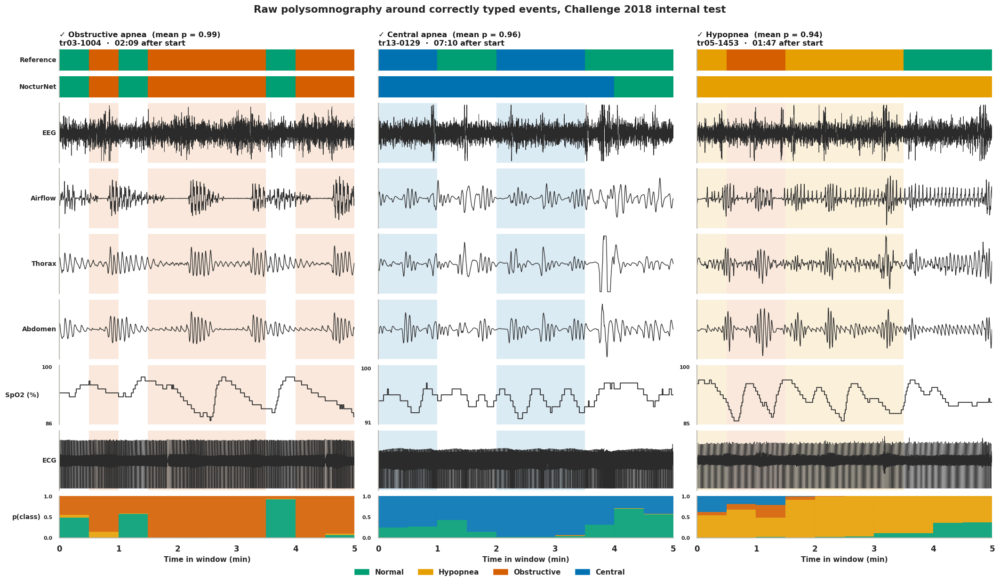

[13b] 12 event gallery done in 3414 s
[13b] 13 error gallery ...


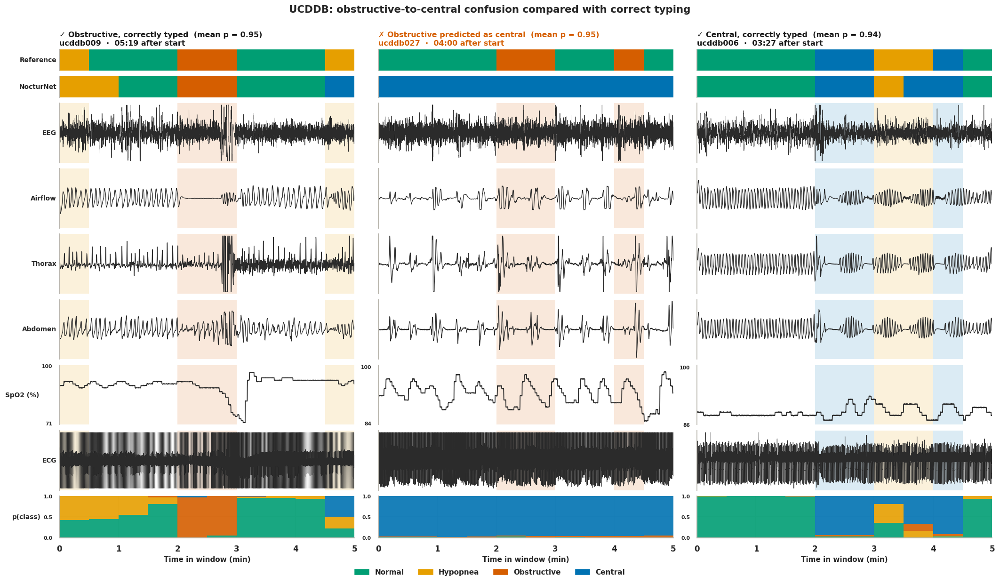

[13b] 13 error gallery done in 6 s
[13b] loading nights ...
[13b] using slow array 'XS' (205525, 4, 480), channels {'Airflow': 0, 'Thorax': 1, 'Abdomen': 2, 'SpO2': 3} (CFG['slow_mods'])
[13b] using fast array 'XF' (205525, 2, 1920), channels {'ECG': 0, 'EEG': 1} (CFG['fast_mods'])
[13b] nights loaded 5/16  (3 s)
[13b] nights loaded 10/16  (5 s)
[13b] nights loaded 15/16  (6 s)
[13b] nights loaded 16/16  (6 s)
[13b] loading nights done in 6 s
[13b] 14 event-locked detected vs missed ...


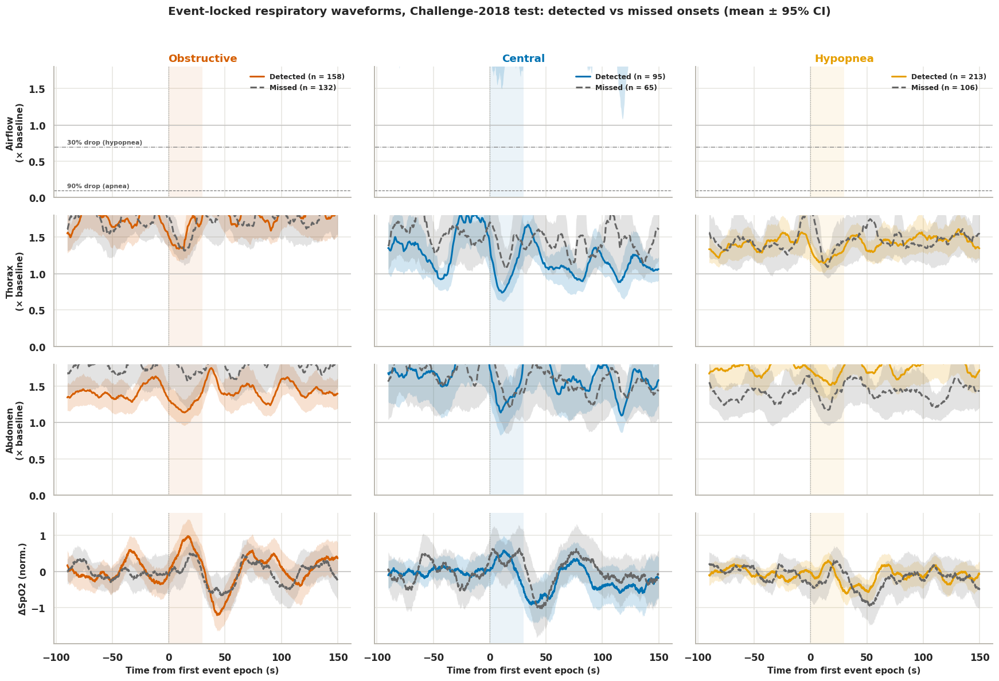

[13b] 14 event-locked detected vs missed done in 7 s
[13b] 15 event-locked cohorts ...


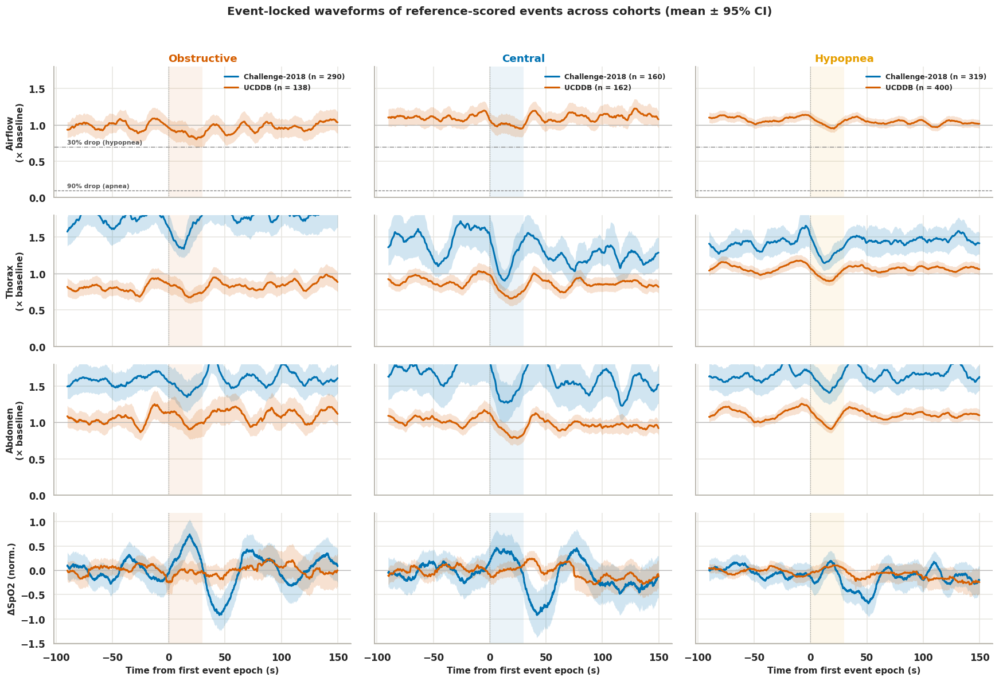

[13b] 15 event-locked cohorts done in 5 s
[13b] 16 night overview test ...


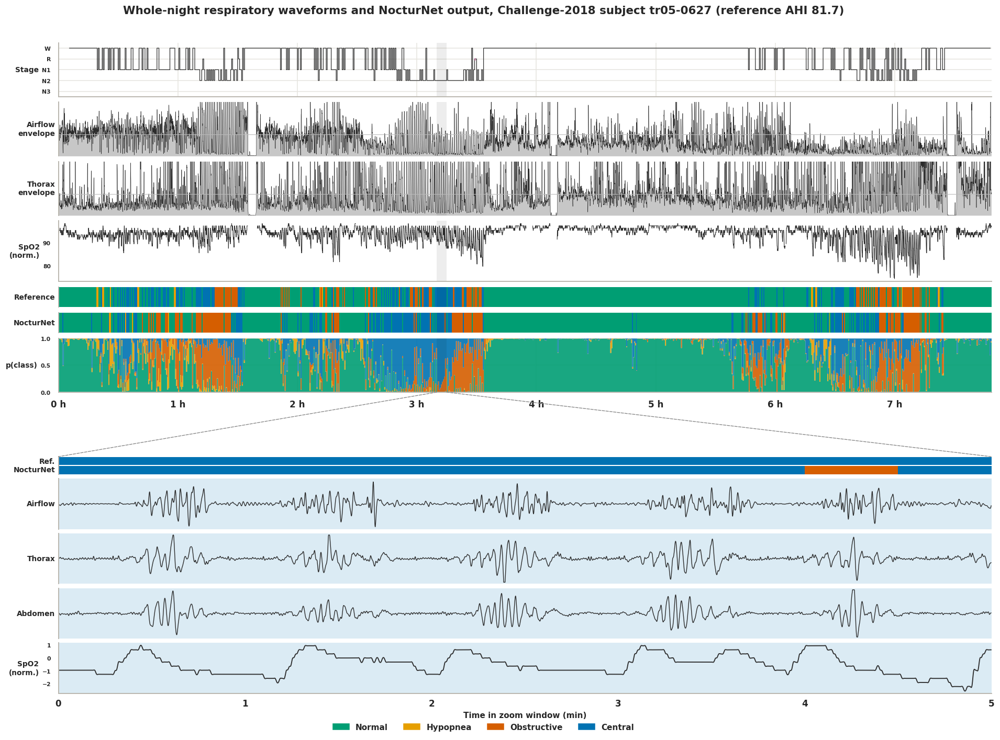

[13b] 16 night overview test done in 5 s
[13b] 16 night overview external ...


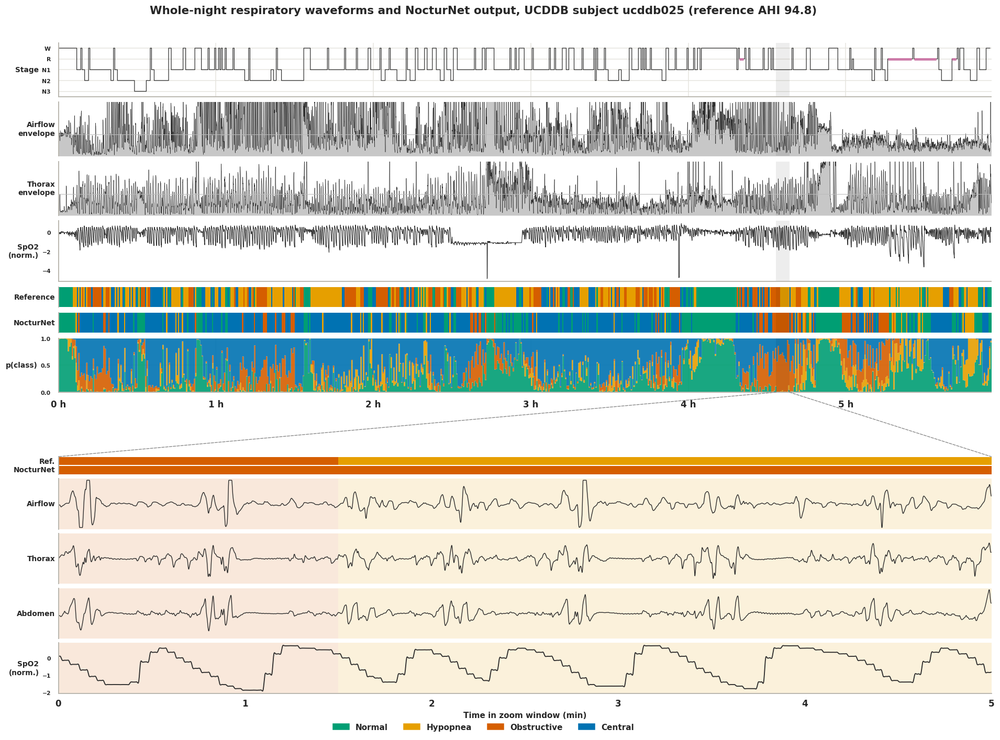

[13b] 16 night overview external done in 5 s


In [35]:
# ===================== STAGE 13b: waveform figures =====================

import os, glob, functools, tempfile, time
from concurrent.futures import ThreadPoolExecutor
from fractions import Fraction
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.patches import ConnectionPatch, Patch
from scipy import signal as ss
from scipy.ndimage import uniform_filter1d

WF = dict(
    raw_root={},
    search_roots=["/content"],
    scan_max_depth=5, scan_budget_s=30,
    physionet_fallback=True,
    pn_dirs={"test": "challenge-2018/1.0.0/training/{rec}", "external": "ucddb/1.0.0", "slpdb": "slpdb/1.0.0"},
    cache_dir="/content/raw_cache",
    night_cache=os.path.join(os.path.dirname(str(DIRS["results"]).rstrip("/")), "wf_cache"),  # whole-night cache (.npz) -> reruns are instant
    workers=6,
    parts={"Challenge-2018": "test", "UCDDB": "external", "SLPDB": "slpdb"},
    epoch_offset_s={},
    lowres_fs=8,
    max_events_per_rec=40,  # cap per class per record for event-locked averages
    max_recs_locked=10,     # records per cohort for event-locked averages (event-richest first); None = all
    run=dict(gallery=True, error_gallery=True, locked_tp_fn=True, locked_cohorts=True, night=True),
    win_epochs=10,          # gallery window length (10 x 30 s = 5 min)
    source="auto",
    arrays=None,
    night_loader=None,
    loader=None,
)
CHANNELS = ["EEG", "Airflow", "Thorax", "Abdomen", "SpO2", "ECG"]
CH_ALIASES = {  # matched case-insensitively as substrings, first hit wins
    "EEG": ["c4-m1", "c4a1", "c4-a1", "c3-m2", "c3a2", "c3-a2", "eeg"],
    "Airflow": ["airflow", "flow", "nasal", "resp n"],
    "Thorax": ["chest", "ribcage", "thor", "resp c"],
    "Abdomen": ["abdomen", "abdo", "abd", "resp a"],
    "SpO2": ["sao2", "spo2", "so2"],
    "ECG": ["ecg"],
}
CLS = CFG["classes"]; EVK = [CLS.index(c) for c in ("Obstructive", "Central", "Hypopnea")]
TRACE = "#2b2b2b"; SPO2_FILL = "#CC79A7"
_PATHS = {}

def _cohort_of_part(part):
    return {v: k for k, v in WF["parts"].items()}.get(part, part)

def _match(labels, wanted):
    low = [l.lower() for l in labels]; out = {}
    for c in wanted:
        for al in CH_ALIASES[c]:
            hit = next((labels[i] for i, l in enumerate(low) if al in l and labels[i] not in out.values()), None)
            if hit is not None: out[c] = hit; break
    return out

_INDEX = None
def _build_index():
    """One-time scan for raw files (*.hea, *.edf, *.rec) under the configured roots, DIRS and Drive."""
    roots = list(WF["raw_root"].values()) + [v for v in DIRS.values() if isinstance(v, str)] + list(WF["search_roots"])
    if "CFG" in globals(): roots += [v for v in CFG.values() if isinstance(v, str) and os.path.isdir(v)]
    idx, seen, t_start = {}, set(), time.time()
    for root in roots:
        if not root or not os.path.isdir(root) or os.path.realpath(root) in seen: continue
        seen.add(os.path.realpath(root)); depth0 = root.rstrip("/").count("/")
        for dp, dn, fn in os.walk(root):
            if time.time() - t_start > WF["scan_budget_s"]: print("[13b] scan budget reached"); dn[:] = []; break
            dn[:] = [d for d in dn if not d.startswith(".") and not (dp == "/content" and d in ("drive", "sample_data"))
                     and not d.startswith("wf_cache") and dp.count("/") - depth0 < WF["scan_max_depth"]]
            for f in fn:
                b, e = os.path.splitext(f); e = e.lower()
                if e in (".hea", ".edf", ".rec") and (b not in idx or e == ".hea"): idx[b] = os.path.join(dp, f)
    print(f"[13b] indexed {len(idx)} raw records under {len(seen)} folder(s) in {time.time() - t_start:.0f} s"
          + ("" if idx else " -> will stream from PhysioNet"))
    return idx

def _download_rec(rec, part):
    """UCDDB stores EDF as .rec; download it once to cache_dir."""
    import urllib.request
    os.makedirs(WF["cache_dir"], exist_ok=True); dst = os.path.join(WF["cache_dir"], rec + ".rec")
    if not os.path.exists(dst):
        url = f"https://physionet.org/files/{WF['pn_dirs'][part].format(rec=rec)}/{rec}.rec"
        print(f"[13b] downloading {url}"); urllib.request.urlretrieve(url, dst)
    return dst

def _locate(rec, part):
    """Local path to the record, or 'pn:<pn_dir>' to stream it from PhysioNet."""
    global _INDEX
    if (rec, part) in _PATHS: return _PATHS[(rec, part)]
    if _INDEX is None: _INDEX = _build_index()
    path = _INDEX.get(rec)
    if path is None and WF["physionet_fallback"] and part in WF["pn_dirs"]:
        path = _download_rec(rec, part) if part == "external" else "pn:" + WF["pn_dirs"][part].format(rec=rec)
    if path is None:
        raise FileNotFoundError(f"{rec}: no .hea/.edf/.rec found on disk and PhysioNet fallback is off. "
                                f"Set WF['raw_root']['{part}'] to the folder holding the raw files.")
    _PATHS[(rec, part)] = path; return path

def _read_raw(rec, part, chans, t0=None, t1=None):
    """Return {canonical channel: (signal float32, fs)} for [t0, t1) seconds (whole night if None)."""
    if WF["loader"] is not None: return WF["loader"](rec, part, chans, t0, t1)
    path = _locate(rec, part); out = {}
    if path.endswith(".hea") or path.startswith("pn:"):
        import wfdb
        if path.startswith("pn:"): base, pn = rec, dict(pn_dir=path[3:])
        else: base, pn = path[:-4], {}
        h = wfdb.rdheader(base, **pn); names = _match(h.sig_name, chans)
        kw = {} if t0 is None else dict(sampfrom=max(int(t0 * h.fs), 0), sampto=min(int(t1 * h.fs), h.sig_len))
        r = wfdb.rdrecord(base, channel_names=list(names.values()), **kw, **pn)
        for c, n in names.items(): out[c] = (r.p_signal[:, r.sig_name.index(n)].astype(np.float32), float(h.fs))
    else:  # EDF (UCDDB .rec files are EDF)
        try: import pyedflib
        except ImportError: os.system("pip -q install pyedflib"); import pyedflib
        if path.endswith(".rec"):
            link = os.path.join(tempfile.gettempdir(), os.path.basename(path)[:-4] + ".edf")
            if not os.path.exists(link): os.symlink(path, link)
            path = link
        f = pyedflib.EdfReader(path)
        try:
            labels = list(f.getSignalLabels()); names = _match(labels, chans)
            for c, n in names.items():
                i = labels.index(n); fs = float(f.getSampleFrequency(i))
                if t0 is None: x = f.readSignal(i).astype(np.float32)
                else:  # read only the window, not the whole night
                    s0 = max(int(t0 * fs), 0); n_ = max(min(int(t1 * fs), f.getNSamples()[i]) - s0, 0)
                    x = f.readSignal(i, start=s0, n=n_).astype(np.float32)
                out[c] = (x, fs)
        finally: f.close()
    return out

def _clean_spo2(x):
    x = np.asarray(x, float).copy()
    if np.nanmax(x) <= 1.5: x *= 100
    x[(x < 50) | (x > 100)] = np.nan
    return x

def _resample(x, fs, fs_out):
    x = np.nan_to_num(np.asarray(x, float) - np.nanmedian(x))
    fr = Fraction(fs_out / fs).limit_denominator(1000)
    return ss.resample_poly(x, fr.numerator, fr.denominator) if fr != 1 else x

def _interp(x, fs, fs_out, n_out):
    t = np.arange(len(x)) / fs
    return np.interp(np.arange(n_out) / fs_out, t, x, left=np.nan, right=np.nan)

def _envelope(x, fs):
    sos = ss.butter(2, [0.05, min(1.0, 0.45 * fs)], "band", fs=fs, output="sos")
    xf = ss.sosfiltfilt(sos, x)
    return np.sqrt(2 * uniform_filter1d(xf ** 2, int(8 * fs)))  # 8-s RMS envelope ~ breath amplitude

def _epoch_t(rec, e): return WF["epoch_offset_s"].get(rec, 0) + np.asarray(e) * 30.0

# ---------------------------------------------------------------- preprocessed arrays (fast path)
SLOW_FS, FAST_FS = 16, 64
SLOW_DEFAULT, FAST_DEFAULT = ["Airflow", "Thorax", "Abdomen", "SpO2"], ["ECG", "EEG"]   # order in Table 3
_ARR = {}

def _order_from_cfg(nch, default):
    """Channel order for an array with nch channels: from a matching list in CFG, else the Table 3 default."""
    for k, v in (CFG.items() if isinstance(CFG, dict) else []):
        if isinstance(v, (list, tuple)) and len(v) == nch and all(isinstance(x, str) for x in v):
            m = _match(list(v), default)
            if len(m) >= min(nch, len(default)) - 1: return {c: list(v).index(n) for c, n in m.items()}, f"CFG['{k}']"
    return ({c: i for i, c in enumerate(default)} if nch == len(default) else None), "Table 3 default"

def _detect_arrays():
    """Find per-epoch signal arrays aligned with Y: shape (n_epochs, C, T) or (n_epochs, T, C), T = 30 s x fs."""
    if _ARR.get("done"): return _ARR
    _ARR["done"] = True; g = globals(); nY = len(Y); ov = WF.get("arrays") or {}
    for kind, T, default in (("slow", 30 * SLOW_FS, SLOW_DEFAULT), ("fast", 30 * FAST_FS, FAST_DEFAULT)):
        names = [ov[kind]] if kind in ov else [k for k, v in g.items() if not k.startswith("_") and isinstance(v, np.ndarray)
                                                and v.ndim == 3 and v.shape[0] == nY and T in v.shape[1:]]
        for nm in names:
            A = g[nm]; layout = "CT" if A.shape[2] == T else "TC"; nch = A.shape[1] if layout == "CT" else A.shape[2]
            if kind + "_order" in ov: order, src = {c: i for i, c in enumerate(ov[kind + "_order"]) if c}, "WF['arrays']"
            else: order, src = _order_from_cfg(nch, default)
            if order:
                _ARR[kind] = (A, order, layout, SLOW_FS if kind == "slow" else FAST_FS)
                print(f"[13b] using {kind} array '{nm}' {A.shape}, channels {order} ({src})"); break
    if "slow" not in _ARR: print("[13b] no preprocessed slow-channel array found -> raw files will be used (slow). "
                                 "Set WF['arrays'] = dict(slow='VARNAME', slow_order=[...]) to point at it.")
    return _ARR

def _from_arrays(rec, chans, t0=None, t1=None):
    """{chan: (x, fs)} from the preprocessed arrays, in recording time (epoch_offset_s respected). Zero-filled = missing."""
    _detect_arrays(); a, b = SPAN[rec]; off = WF["epoch_offset_s"].get(rec, 0); out = {}
    for kind in ("slow", "fast"):
        if kind not in _ARR: continue
        A, order, layout, fs = _ARR[kind]
        for c, i in order.items():
            if c not in chans or c in out: continue
            x = np.asarray(A[a:b, i, :] if layout == "CT" else A[a:b, :, i], np.float32).reshape(-1)
            if not np.any(x): continue
            if off: x = np.r_[np.full(int(off * fs), np.nan, np.float32), x]
            if t0 is not None: x = x[max(int(t0 * fs), 0):int(t1 * fs)]
            out[c] = (x, float(fs))
    return out

def _use_arrays(fig):
    if WF["source"] == "raw": return False
    if WF["source"] == "arrays" or fig in ("night", "locked"): return "slow" in _detect_arrays()
    return False

_NIGHT = {}
def night_lowres(rec, part):
    """Whole-night envelopes + SpO2 at lowres_fs; cached in memory and as .npz in WF['night_cache']."""
    key = (rec, part)
    if key in _NIGHT: return _NIGHT[key]
    fo = WF["lowres_fs"]; fn = os.path.join(WF["night_cache"], f"{rec}_{fo}hz{'_arr' if _use_arrays('night') else ''}.npz")
    if os.path.exists(fn):
        with np.load(fn) as z: _NIGHT[key] = {k: z[k] for k in z.files}
        return _NIGHT[key]
    out = _night_compute(rec, part)
    try: os.makedirs(WF["night_cache"], exist_ok=True); np.savez_compressed(fn, **out)
    except Exception as ex: print(f"[13b] cache write failed for {rec}: {ex}")
    _NIGHT[key] = out; return out

def prefetch(pairs):
    """Load many nights in parallel (I/O bound). pairs: list of (rec, part)."""
    todo = [p for p in pairs if p not in _NIGHT]
    if not todo: return
    t = time.time(); done = 0
    def job(p):
        try: night_lowres(*p); return None
        except Exception as ex: return f"{p[0]}: {ex}"
    with ThreadPoolExecutor(WF["workers"]) as ex:
        for err in ex.map(job, todo):
            done += 1
            if err: print(f"[13b] skip {err}")
            if done % 5 == 0 or done == len(todo): print(f"[13b] nights loaded {done}/{len(todo)}  ({time.time() - t:.0f} s)")

def _locked_recs(part):
    recs = [r for r in SPL.get(part, []) if r in SPAN]
    recs.sort(key=lambda r: -int((Y[SPAN[r][0]:SPAN[r][1]] > 0).sum()))  # event-richest first
    return recs[:WF["max_recs_locked"]]

def _night_compute(rec, part):
    fo = WF["lowres_fs"]; a, b = SPAN[rec]; n = int((_epoch_t(rec, b - a)) * fo)
    nl = WF.get("night_loader"); arr = not nl and _use_arrays("night")
    raw = nl(rec, part) if nl else (_from_arrays(rec, SLOW_DEFAULT) if arr else _read_raw(rec, part, SLOW_DEFAULT))
    y = Y[a:b]; sl = np.isin(STG[a:b], ["N1", "N2", "N3", "R"])
    ref_mask = np.zeros(n, bool)
    for e in np.where((y == 0) & sl)[0]:
        s = int(_epoch_t(rec, e) * fo); ref_mask[s:s + 30 * fo] = True
    out = {}
    for c in ("Airflow", "Thorax", "Abdomen"):
        if c not in raw: out[c + "_env"] = np.full(n, np.nan); continue
        x, fs = raw[c]; env = _envelope(_resample(x, fs, fo), fo)
        env = np.pad(env, (0, max(0, n - len(env))), constant_values=np.nan)[:n]
        base = np.nanmedian(env[ref_mask[:len(env)]]) if ref_mask.any() else np.nanmedian(env)
        out[c + "_env"] = env / (base if base > 0 else 1)
    if "SpO2" in raw: out["SpO2"] = _interp(raw["SpO2"][0] if arr else _clean_spo2(raw["SpO2"][0]), raw["SpO2"][1], fo, n)
    else: out["SpO2"] = np.full(n, np.nan)
    return out

# ---------------------------------------------------------------- drawing helpers
def _style(ax, ylabel=None, keep_x=False):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.grid(False); ax.set_yticks([])
    if ylabel: ax.set_ylabel(ylabel, rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    if not keep_x: ax.tick_params(axis="x", labelbottom=False, length=0); ax.spines["bottom"].set_visible(False)

def _strip(ax, x0, width, labels, y0=0, h=1):
    for k in range(len(CLS)):
        idx = np.where(labels == k)[0]
        if len(idx): ax.broken_barh([(x0 + i * width, width) for i in idx], (y0, h), facecolors=CCOL[k], lw=0)

def _prob_stack(ax, x0, width, probs):
    xs = x0 + np.arange(len(probs) + 1) * width; cum = np.zeros(len(probs))
    for k in range(len(CLS)):
        top = cum + probs[:, k]
        ax.fill_between(xs, np.r_[cum, cum[-1]], np.r_[top, top[-1]], step="post", color=CCOL[k], lw=0, alpha=.9)
        cum = top
    ax.set_ylim(0, 1); ax.set_yticks([0, .5, 1]); ax.tick_params(axis="y", labelsize=7)

def _display(c, x, fs, scaled=False):
    x = np.asarray(x, float)
    if c == "SpO2": return x if scaled else _clean_spo2(x)
    band = {"EEG": (0.3, 35), "ECG": (0.5, 40)}.get(c, (0.05, 2.0))
    hi = min(band[1], 0.45 * fs)
    x = ss.sosfiltfilt(ss.butter(2, [band[0], hi], "band", fs=fs, output="sos"), np.nan_to_num(x - np.nanmedian(x)))
    q = np.subtract(*np.percentile(x, [95, 5])) or 1
    return np.clip(x / q, -1.5, 1.5)

def pick_runs(part, true_k, pred_k, n=1, min_run=2, exclude=()):
    """Runs of >= min_run epochs with reference == true_k and NocturNet == pred_k, ranked by mean p(pred_k)."""
    cands = []
    for rec in SPL[part]:
        if rec in exclude: continue
        a, b = SPAN[rec]; ok = (Y[a:b] == true_k) & (P[a:b].argmax(1) == pred_k)
        d = np.diff(np.r_[0, ok.astype(int), 0]); st, en = np.where(d == 1)[0], np.where(d == -1)[0]
        for s, e in zip(st, en):
            if e - s >= min_run: cands.append((P[a + s:a + e, pred_k].mean(), rec, s, e))
    cands.sort(reverse=True); out, used = [], set()
    for sc, rec, s, e in cands:
        if rec in used: continue
        out.append((rec, s, e, sc)); used.add(rec)
        if len(out) == n: break
    return out

def _window(rec, run):
    s, e = run; a, b = SPAN[rec]; W = WF["win_epochs"]; ne = b - a
    w0 = int(np.clip((s + e) // 2 - W // 2, 0, max(ne - W, 0))); return w0, min(w0 + W, ne)

def plot_event_window(fig, spec, rec, part, run, title, title_color, first_col, raw=None, scaled=False):
    a, b = SPAN[rec]; w0, w1 = _window(rec, run)
    t0, t1 = _epoch_t(rec, w0), _epoch_t(rec, w1)
    if raw is None: raw = _read_raw(rec, part, CHANNELS, t0, t1)
    chans = [c for c in CHANNELS if c in raw]
    hr = [.35, .35] + [1.0] * len(chans) + [.7]
    g = GridSpecFromSubplotSpec(len(hr), 1, subplot_spec=spec, height_ratios=hr, hspace=.12)
    axs = [fig.add_subplot(g[0])]; axs += [fig.add_subplot(g[i], sharex=axs[0]) for i in range(1, len(hr))]
    yr, yp = Y[a + w0:a + w1], P[a + w0:a + w1].argmax(1)
    for ax, lab, v in [(axs[0], "Reference", yr), (axs[1], "NocturNet", yp)]:
        _strip(ax, 0, .5, v); ax.set_ylim(0, 1); _style(ax, lab if first_col else None)
    for ax, c in zip(axs[2:-1], chans):
        x, fs = raw[c]; tm = np.arange(len(x)) / fs / 60; xd = _display(c, x, fs, scaled)
        for i in np.where(yr > 0)[0]: ax.axvspan(i * .5, (i + 1) * .5, color=CCOL[yr[i]], alpha=.14, lw=0)
        if c == "SpO2":
            ax.plot(tm, xd, color=TRACE, lw=1.2); ax.grid(False)
            lo = np.nanmin(xd) if np.isfinite(xd).any() else 90
            if not scaled: ax.set_ylim(min(lo - 1, 94), 100.5); ax.set_yticks([int(min(lo, 94)), 100])
            ax.tick_params(axis="y", labelsize=7)
            for sp in ("top", "right"): ax.spines[sp].set_visible(False)
            ax.tick_params(axis="x", labelbottom=False, length=0); ax.spines["bottom"].set_visible(False)
            if first_col: ax.set_ylabel("SpO2\n(norm.)" if scaled else "SpO2 (%)", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
        else:
            ax.plot(tm, xd, color=TRACE, lw=.6 if c in ("EEG", "ECG") else .9); ax.set_ylim(-1.6, 1.6)
            _style(ax, c if first_col else None)
    _prob_stack(axs[-1], 0, .5, P[a + w0:a + w1])
    for sp in ("top", "right"): axs[-1].spines[sp].set_visible(False)
    if first_col: axs[-1].set_ylabel("p(class)", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    axs[-1].set_xlabel("Time in window (min)"); axs[-1].set_xlim(0, (w1 - w0) * .5)
    hh, mm = divmod(int(t0 // 60), 60)
    axs[0].set_title(f"{title}\n{rec}  ·  {hh:02d}:{mm:02d} after start", fontsize=10.5, fontweight="bold", color=title_color, loc="left")
    return axs

def _legend(fig, y=0.005):
    fig.legend(handles=[Patch(color=CCOL[k], label=CLS[k]) for k in range(len(CLS))],
               loc="lower center", ncol=len(CLS), frameon=False, bbox_to_anchor=(.5, y), fontsize=10)

def gallery(part, panels, fname, suptitle):
    """panels: list of (true_k, pred_k, title). One column per panel, best-confidence run from a distinct subject."""
    picks, used = [], set()
    for tk, pk, ttl in panels:
        r = pick_runs(part, tk, pk, n=1, exclude=used)
        if not r: r = pick_runs(part, tk, pk, n=1, min_run=1)
        if not r: print(f"[13b] no run for {ttl} in {part}"); continue
        rec, s, e, sc = r[0]; used.add(rec); picks.append((rec, s, e, sc, tk, pk, ttl))
    if not picks: return None
    arr = _use_arrays("gallery")
    def fetch(p):
        w0, w1 = _window(p[0], (p[1], p[2])); t0, t1 = _epoch_t(p[0], w0), _epoch_t(p[0], w1)
        return _from_arrays(p[0], CHANNELS, t0, t1) if arr else _read_raw(p[0], part, CHANNELS, t0, t1)
    with ThreadPoolExecutor(len(picks)) as ex: raws = list(ex.map(fetch, picks))   # all windows at once
    fig = plt.figure(figsize=(6.2 * len(picks) + 1.2, 11.5))
    gs = GridSpec(1, len(picks), figure=fig, wspace=.08, left=.08, right=.99, top=.9, bottom=.08)
    for j, (rec, s, e, sc, tk, pk, ttl) in enumerate(picks):
        col = "#1a1a1a" if tk == pk else "#D55E00"
        mark = "✓" if tk == pk else "✗"
        plot_event_window(fig, gs[j], rec, part, (s, e), f"{mark} {ttl}  (mean p = {sc:.2f})", col, j == 0, raws[j], bool(arr))
    _legend(fig); fig.suptitle(suptitle, fontsize=14, fontweight="bold", y=.975)
    savefig(fig, fname)
    pd.DataFrame([dict(rec=p[0], start_epoch=p[1], end_epoch=p[2], mean_p=p[3], ref=CLS[p[4]], pred=CLS[p[5]]) for p in picks]
                 ).to_csv(os.path.join(DIRS["results"], f"{fname}_examples.csv"), index=False)
    return picks

# ---------------------------------------------------------------- event-locked averages
def event_locked(part, pre=90, post=150):
    fo = WF["lowres_fs"]; L = int((pre + post) * fo); tt = np.arange(L) / fo - pre
    keys = ("Airflow_env", "Thorax_env", "Abdomen_env", "SpO2"); rng = np.random.default_rng(0)
    res = {k: dict(seg={c: [] for c in keys}, hit=[]) for k in EVK}
    recs = _locked_recs(part); prefetch([(r, part) for r in recs])
    for rec in recs:
        if (rec, part) not in _NIGHT: continue
        N = _NIGHT[(rec, part)]
        a, b = SPAN[rec]; y = Y[a:b]; yp = P[a:b].argmax(1)
        for k in EVK:
            on = np.where((y == k) & (np.r_[-1, y[:-1]] != k))[0]
            if len(on) > WF["max_events_per_rec"]: on = rng.choice(on, WF["max_events_per_rec"], replace=False)
            for e in on:
                s0 = int((_epoch_t(rec, e) - pre) * fo)
                if s0 < 0 or s0 + L > len(N["SpO2"]): continue
                for c in keys:
                    seg = N[c][s0:s0 + L].copy()
                    if c == "SpO2": seg -= np.nanmean(seg[:int((pre - 30) * fo)]) if np.isfinite(seg[:int((pre - 30) * fo)]).any() else np.nan
                    res[k]["seg"][c].append(seg)
                res[k]["hit"].append(yp[e] == k)
    for k in EVK:
        res[k]["seg"] = {c: np.array(v) if v else np.empty((0, L)) for c, v in res[k]["seg"].items()}
        res[k]["hit"] = np.array(res[k]["hit"], bool)
    return tt, res

def _mean_band(ax, tt, arr, color, label, ls="-"):
    if len(arr) == 0: return
    with np.errstate(all="ignore"):
        m = np.nanmean(arr, 0); n = np.sum(np.isfinite(arr), 0); se = np.nanstd(arr, 0) / np.sqrt(np.maximum(n, 1))
    ax.fill_between(tt, m - 1.96 * se, m + 1.96 * se, color=color, alpha=.18, lw=0)
    ax.plot(tt, m, color=color, lw=2, ls=ls, label=label)

ROWS = [("Airflow_env", "Airflow\n(× baseline)"), ("Thorax_env", "Thorax\n(× baseline)"),
        ("Abdomen_env", "Abdomen\n(× baseline)"), ("SpO2", "ΔSpO2")]

def _locked_axes(tt):
    fig, axs = plt.subplots(len(ROWS), len(EVK), figsize=(16, 11), sharex=True, sharey="row")
    for i, (c, lab) in enumerate(ROWS):
        for j, k in enumerate(EVK):
            ax = axs[i, j]; ax.axvline(0, color="#999", lw=.8, ls=":"); ax.axvspan(0, 30, color=CCOL[k], alpha=.08, lw=0)
            for sp in ("top", "right"): ax.spines[sp].set_visible(False)
            if c != "SpO2":
                ax.axhline(1, color="#bbb", lw=.8)
                if c == "Airflow_env":
                    ax.axhline(.1, color="#777", lw=.8, ls="--"); ax.axhline(.7, color="#777", lw=.8, ls="-.")
                    if j == 0:
                        ax.text(tt[0], .12, "90% drop (apnea)", fontsize=7, color="#555", va="bottom")
                        ax.text(tt[0], .72, "30% drop (hypopnea)", fontsize=7, color="#555", va="bottom")
                ax.set_ylim(0, 1.8)
            else: ax.axhline(0, color="#bbb", lw=.8)
            if j == 0: ax.set_ylabel(lab + ((" (norm.)" if _use_arrays("locked") else " (%)") if c == "SpO2" else ""), fontsize=10, fontweight="bold")
            if i == 0: ax.set_title(CLS[k], fontsize=12, fontweight="bold", color=CCOL[k])
            if i == len(ROWS) - 1: ax.set_xlabel("Time from first event epoch (s)")
    return fig, axs

def plot_locked_tp_fn(part="test", fname="14_event_locked_tp_fn"):
    tt, res = event_locked(part); fig, axs = _locked_axes(tt)
    for j, k in enumerate(EVK):
        h = res[k]["hit"]
        for i, (c, _) in enumerate(ROWS):
            A = res[k]["seg"][c]
            _mean_band(axs[i, j], tt, A[h], CCOL[k], f"Detected (n = {h.sum()})")
            _mean_band(axs[i, j], tt, A[~h], "#666666", f"Missed (n = {(~h).sum()})", ls="--")
        axs[0, j].legend(frameon=False, fontsize=8, loc="upper right")
    fig.suptitle(f"Event-locked respiratory waveforms, {_cohort_of_part(part)} test: detected vs missed onsets (mean ± 95% CI)",
                 fontsize=13, fontweight="bold"); fig.tight_layout(rect=(0, 0, 1, .96)); savefig(fig, fname)
    return res

def plot_locked_cohorts(fname="15_event_locked_cohorts"):
    out = {}
    for name, part in WF["parts"].items():
        if part in SPL: out[name] = event_locked(part)
    if not out: return
    tt = next(iter(out.values()))[0]; fig, axs = _locked_axes(tt)
    fallback = ["#000000", "#56B4E9", "#CC79A7"]
    for ci, (name, (_, res)) in enumerate(out.items()):
        col = DBPAL.get(name, fallback[ci % 3]) if isinstance(DBPAL, dict) else fallback[ci % 3]
        for j, k in enumerate(EVK):
            for i, (c, _) in enumerate(ROWS):
                _mean_band(axs[i, j], tt, res[k]["seg"][c], col, f"{name} (n = {len(res[k]['hit'])})")
            axs[0, j].legend(frameon=False, fontsize=8, loc="upper right")
    fig.suptitle("Event-locked waveforms of reference-scored events across cohorts (mean ± 95% CI)", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, .96)); savefig(fig, fname)

# ---------------------------------------------------------------- whole-night overview with zoom
def night_overview(rec, part, fname):
    a, b = SPAN[rec]; ne = b - a; fo = WF["lowres_fs"]; N = night_lowres(rec, part)
    off_h = WF["epoch_offset_s"].get(rec, 0) / 3600; w = 30 / 3600
    hrs_lo = np.arange(len(N["SpO2"])) / fo / 3600
    step = fo * 2; blk = lambda v: np.nanmedian(v[:len(v) // step * step].reshape(-1, step), 1)  # 0.5-Hz display
    hb = hrs_lo[:len(hrs_lo) // step * step:step]
    # zoom window: 10 epochs with most reference event epochs, ties broken by NocturNet confidence
    W = WF["win_epochs"]; ev = (Y[a:b] > 0).astype(float) + .01 * (1 - P[a:b, 0])
    z0 = int(np.argmax(np.convolve(ev, np.ones(W), "valid"))); z1 = z0 + W
    fig = plt.figure(figsize=(18, 13))
    outer = GridSpec(2, 1, figure=fig, height_ratios=[3.1, 2.1], hspace=.22, left=.09, right=.99, top=.93, bottom=.06)
    top = GridSpecFromSubplotSpec(7, 1, outer[0], height_ratios=[.8, .8, .8, .9, .3, .3, .8], hspace=.12)
    ax = [fig.add_subplot(top[0])]; ax += [fig.add_subplot(top[i], sharex=ax[0]) for i in range(1, 7)]
    smap = {"W": 4, "R": 3, "N1": 2, "N2": 1, "N3": 0}; st = np.array([smap.get(s, np.nan) for s in STG[a:b]], float)
    eh = off_h + np.arange(ne) * w
    ax[0].step(eh, st, where="post", color=TRACE, lw=.8)
    ax[0].plot(eh, np.where(st == 3, 3, np.nan), color=SPO2_FILL, lw=3, solid_capstyle="butt")
    ax[0].set_yticks(range(5)); ax[0].set_yticklabels(["N3", "N2", "N1", "R", "W"], fontsize=7); ax[0].set_ylim(-.5, 4.5)
    for sp in ("top", "right"): ax[0].spines[sp].set_visible(False)
    ax[0].tick_params(axis="x", labelbottom=False, length=0); ax[0].set_ylabel("Stage", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    for axx, c, lab in [(ax[1], "Airflow_env", "Airflow"), (ax[2], "Thorax_env", "Thorax")]:
        v = blk(N[c]); axx.fill_between(hb, 0, v, color="#9a9a9a", lw=0, alpha=.55); axx.plot(hb, v, color=TRACE, lw=.4)
        axx.axhline(1, color="#bbb", lw=.7); axx.set_ylim(0, 2.5); _style(axx, lab + "\nenvelope")
    scaled = _use_arrays("night")
    sp2 = blk(N["SpO2"]); ax[3].plot(hb, sp2, color=TRACE, lw=.7); ax[3].grid(False)
    if not scaled:
        ax[3].fill_between(hb, sp2, 90, where=sp2 < 90, color=SPO2_FILL, alpha=.6, lw=0, interpolate=True)
        lo = np.nanpercentile(sp2, .5) if np.isfinite(sp2).any() else 85
        ax[3].set_ylim(max(lo - 2, 50), 100.5); ax[3].axhline(90, color="#bbb", lw=.7, ls=":")
    for s_ in ("top", "right"): ax[3].spines[s_].set_visible(False)
    ax[3].tick_params(axis="x", labelbottom=False, length=0); ax[3].tick_params(axis="y", labelsize=7)
    ax[3].set_ylabel("SpO2\n(norm.)" if scaled else "SpO2 (%)", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    _strip(ax[4], off_h, w, Y[a:b]); _style(ax[4], "Reference"); ax[4].set_ylim(0, 1)
    _strip(ax[5], off_h, w, P[a:b].argmax(1)); _style(ax[5], "NocturNet"); ax[5].set_ylim(0, 1)
    _prob_stack(ax[6], off_h, w, P[a:b])
    ax[6].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g} h"))
    for s_ in ("top", "right"): ax[6].spines[s_].set_visible(False)
    ax[6].set_ylabel("p(class)", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    ax[6].set_xlim(off_h, off_h + ne * w)
    zh0, zh1 = off_h + z0 * w, off_h + z1 * w
    for axx in ax: axx.axvspan(zh0, zh1, color="#000", alpha=.07, lw=0)
    # zoom panel (raw waveforms)
    t0, t1 = _epoch_t(rec, z0), _epoch_t(rec, z1)
    raw = _from_arrays(rec, SLOW_DEFAULT, t0, t1) if scaled else _read_raw(rec, part, SLOW_DEFAULT, t0, t1); chans = [c for c in ("Airflow", "Thorax", "Abdomen", "SpO2") if c in raw]
    bot = GridSpecFromSubplotSpec(len(chans) + 1, 1, outer[1], height_ratios=[.35] + [1] * len(chans), hspace=.1)
    zb = [fig.add_subplot(bot[0])]; zb += [fig.add_subplot(bot[i], sharex=zb[0]) for i in range(1, len(chans) + 1)]
    yr, yp = Y[a + z0:a + z1], P[a + z0:a + z1].argmax(1)
    _strip(zb[0], 0, .5, yr, .52, .46); _strip(zb[0], 0, .5, yp, 0, .46); _style(zb[0], "Ref.\nNocturNet"); zb[0].set_ylim(0, 1)
    for axx, c in zip(zb[1:], chans):
        x, fs = raw[c]; tm = np.arange(len(x)) / fs / 60; xd = _display(c, x, fs, scaled)
        for i in np.where(yr > 0)[0]: axx.axvspan(i * .5, (i + 1) * .5, color=CCOL[yr[i]], alpha=.14, lw=0)
        if c == "SpO2":
            axx.plot(tm, xd, color=TRACE, lw=1.2); axx.grid(False); axx.tick_params(axis="y", labelsize=7)
            for s_ in ("top", "right"): axx.spines[s_].set_visible(False)
            axx.set_ylabel("SpO2\n(norm.)" if scaled else "SpO2 (%)", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
        else:
            axx.plot(tm, xd, color=TRACE, lw=.9); axx.set_ylim(-1.6, 1.6); _style(axx, c, keep_x=False)
    zb[-1].set_xlabel("Time in zoom window (min)"); zb[-1].set_xlim(0, (z1 - z0) * .5)
    zb[-1].tick_params(axis="x", labelbottom=True, length=3); zb[-1].spines["bottom"].set_visible(True)
    for xa, xb in [(zh0, 0), (zh1, (z1 - z0) * .5)]:
        fig.add_artist(ConnectionPatch(xyA=(xa, 0), coordsA=ax[6].transData, xyB=(xb, 1), coordsB=zb[0].transData,
                                       color="#888", lw=.9, ls="--"))
    ttl = f"Whole-night respiratory waveforms and NocturNet output, {_cohort_of_part(part)} subject {rec}"
    if "META" in globals() and rec in META.index and "ahi" in META.columns and pd.notna(META.loc[rec, "ahi"]):
        ttl += f" (reference AHI {META.loc[rec, 'ahi']:.1f})"
    fig.suptitle(ttl, fontsize=14, fontweight="bold"); _legend(fig, y=.0)
    savefig(fig, fname)

# ---------------------------------------------------------------- run
iO, iC, iH = EVK; R = WF["run"]
def _timed(name, fn, *a, **k):
    t = time.time(); print(f"[13b] {name} ..."); out = fn(*a, **k); print(f"[13b] {name} done in {time.time() - t:.0f} s"); return out
if R["gallery"]:
    _timed("12 event gallery", gallery, "test", [(iO, iO, "Obstructive apnea"), (iC, iC, "Central apnea"), (iH, iH, "Hypopnea")],
           "12_event_gallery", "Raw polysomnography around correctly typed events, Challenge 2018 internal test")
if R["error_gallery"] and "external" in SPL:
    _timed("13 error gallery", gallery, "external", [(iO, iO, "Obstructive, correctly typed"), (iO, iC, "Obstructive predicted as central"),
           (iC, iC, "Central, correctly typed")], "13_error_gallery", "UCDDB: obstructive-to-central confusion compared with correct typing")
if R["locked_tp_fn"] or R["locked_cohorts"]:   # load all needed nights once, in parallel
    _timed("loading nights", prefetch, [(r, p) for p in WF["parts"].values() if p in SPL for r in _locked_recs(p)])
if R["locked_tp_fn"]: _timed("14 event-locked detected vs missed", plot_locked_tp_fn, "test")
if R["locked_cohorts"]: _timed("15 event-locked cohorts", plot_locked_cohorts)
if R["night"]:
    for part in ("test", "external"):
        if part in SPL and "ahi" in META.columns:
            r_ = META.loc[[r for r in SPL[part] if r in META.index], "ahi"].idxmax()
            _timed(f"16 night overview {part}", night_overview, r_, part, f"16_night_overview_{_cohort_of_part(part)}")
set_flag("stage13b_waveforms")

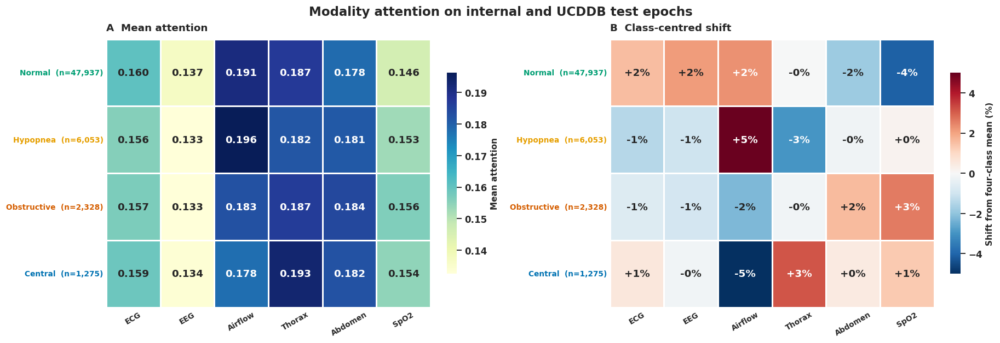

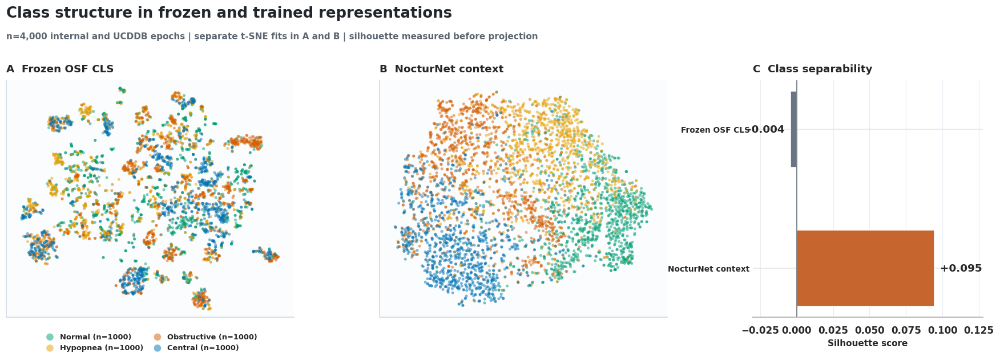

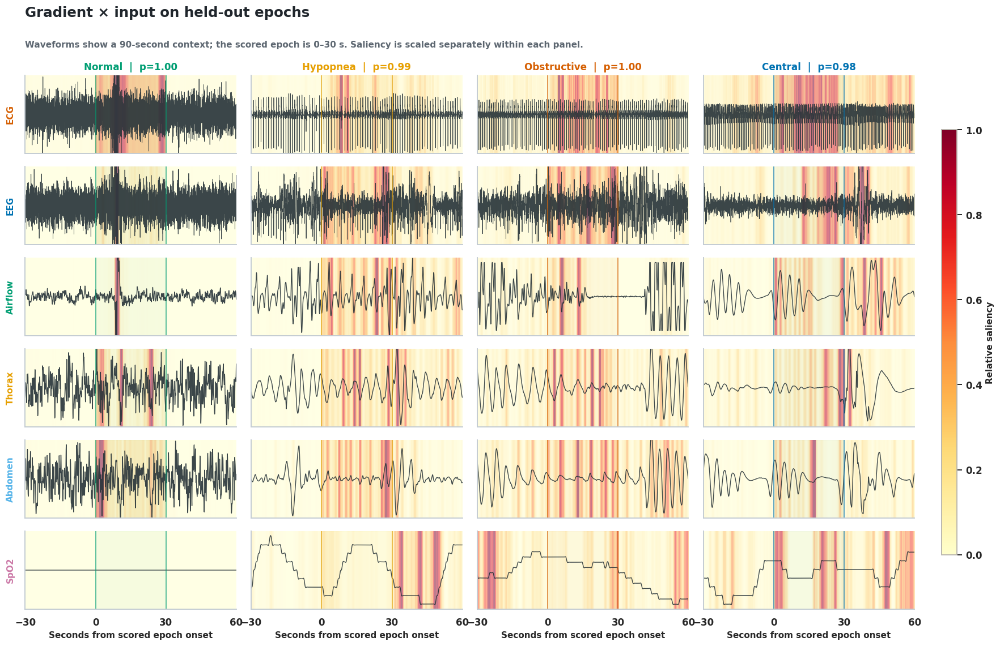

In [27]:
# ===================== STAGE 14 =====================
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from matplotlib.colors import Normalize

# Stage 14 needs the notebook setup, cached features, and trained model definitions.
required = ("os", "np", "pd", "plt", "sns", "torch", "DIRS", "CFG", "IDX", "Y",
            "FM", "MODS", "N_GRP", "MODELS", "DEV", "get_batch", "savefig",
            "set_flag")
missing_setup = [name for name in required if name not in globals()]
if missing_setup:
    raise RuntimeError(
        "Stage 14 requires earlier notebook stages. Run Stages 0–9 in order, "
        f"then rerun this cell. Missing: {', '.join(missing_setup)}"
    )

# The selected model has an explicit saved tag in this notebook's TAG_ALIAS table.
# This avoids depending on the TAG helper when rerunning the visualization cell.
model_name = globals().get("PROPOSED", "NocturNet")
model_tag = globals().get("TAG_ALIAS", {}).get(model_name, "w_o_montage_dropout_v5_na")
pred_file = os.path.join(DIRS["results"], f"pred_{model_tag}.npz")
with np.load(pred_file) as saved_pred:
    needed = ("prob", "w", "emb")
    missing = [key for key in needed if key not in saved_pred]
    if missing:
        raise RuntimeError(f"Missing {missing} in {pred_file}; rerun the proposed-model prediction stage.")
    PRED = {key: saved_pred[key] for key in needed}
P = PRED["prob"]

ii = np.concatenate([IDX["test"], IDX["external"]])
tok_names = (MODS + ["OSF CLS"] + [f"OSF G{g+1}" for g in range(N_GRP)])[:PRED["w"].shape[1]]

# Attention summaries. The class-centred panel uses the same class means as the left panel.
wd = pd.DataFrame(PRED["w"][ii], columns=tok_names).assign(
    Class=np.array(CFG["classes"])[Y[ii]]
)
wm = wd.groupby("Class").mean().reindex(CFG["classes"])
class_counts = wd.groupby("Class").size().reindex(CFG["classes"])
shift = 100 * (wm.div(wm.mean(axis=0), axis=1) - 1)
shift_limit = max(5, float(np.nanmax(np.abs(shift.values))))
row_labels = [f"{name}  (n={class_counts[name]:,})" for name in CFG["classes"]]

fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.6), constrained_layout=True)
sns.heatmap(wm, annot=True, fmt=".3f", cmap="YlGnBu", linewidths=.7,
            linecolor="white", ax=axes[0], yticklabels=row_labels,
            cbar_kws={"label": "Mean attention", "shrink": .75})
shift_labels = np.array([[f"{v:+.0f}%" for v in row] for row in shift.values])
sns.heatmap(shift, annot=shift_labels, fmt="", cmap="RdBu_r", center=0,
            vmin=-shift_limit, vmax=shift_limit, linewidths=.7, linecolor="white",
            ax=axes[1], yticklabels=row_labels,
            cbar_kws={"label": "Shift from four-class mean (%)", "shrink": .75})
for ax, title in zip(axes, ("A  Mean attention", "B  Class-centred shift")):
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=9, length=0)
    ax.tick_params(axis="y", rotation=0, labelsize=9, length=0)
    for tick, color in zip(ax.get_yticklabels(), CCOL):
        tick.set_color(color)
        tick.set_fontweight("bold")
fig.suptitle("Modality attention on internal and UCDDB test epochs", fontsize=15, fontweight="bold")
savefig(fig, "12_token_attention")

# The projections are fitted separately; silhouette scores use original feature spaces.
rs = np.random.default_rng(1)
sub = np.concatenate([
    rs.choice(ii[Y[ii] == k], min((Y[ii] == k).sum(), CFG["tsne_n"] // 4), replace=False)
    for k in range(4) if (Y[ii] == k).any()
])
TSP = os.path.join(DIRS["results"], f"tsne_{model_tag}.npz")
E1 = E2 = None
if os.path.exists(TSP):
    with np.load(TSP) as cached:
        if np.array_equal(cached["sub"], sub):
            if "e" in cached and cached["e"].shape == (len(sub), 2): E2 = cached["e"]
            if "e1" in cached and cached["e1"].shape == (len(sub), 2): E1 = cached["e1"]
if E1 is None:
    E1 = TSNE(n_components=2, perplexity=35, init="pca", random_state=0).fit_transform(
        FM[sub, 0].astype(np.float32)
    )
if E2 is None:
    E2 = TSNE(n_components=2, perplexity=35, init="pca", random_state=0).fit_transform(
        PRED["emb"][sub].astype(np.float32)
    )
np.savez(TSP, e=E2, e1=E1, sub=sub)
s1 = silhouette_score(FM[sub, 0].astype(np.float32), Y[sub])
s2 = silhouette_score(PRED["emb"][sub], Y[sub])

fig = plt.figure(figsize=(17, 6.3), facecolor="white")
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, .8],
                      left=.055, right=.97, top=.78, bottom=.18, wspace=.32)
axs = [fig.add_subplot(gs[0, j]) for j in range(3)]
for ax, emb, title in ((axs[0], E1, "A  Frozen OSF CLS"),
                       (axs[1], E2, "B  NocturNet context")):
    for k, name in enumerate(CFG["classes"]):
        mask = Y[sub] == k
        ax.scatter(emb[mask, 0], emb[mask, 1], s=11, alpha=.5,
                   color=PAL[name], edgecolors="none", rasterized=True,
                   label=f"{name} (n={mask.sum()})")
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", pad=10)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal", adjustable="datalim")
    ax.margins(.06); ax.set_facecolor("#FBFCFD")
    for spine in ax.spines.values(): spine.set_color("#D8DEE5")
axs[0].legend(loc="upper center", bbox_to_anchor=(.5, -.04), ncol=2,
              frameon=False, markerscale=2.5, fontsize=8.5,
              handletextpad=.35, columnspacing=.9)
bar_ax = axs[2]
bar_ax.barh([1, 0], [s1, s2], height=.55,
            color=["#697586", "#C7652F"], edgecolor="white")
bar_ax.set_yticks([1, 0], ["Frozen OSF CLS", "NocturNet context"])
bar_ax.axvline(0, color="#5C6670", lw=1)
bar_ax.set_xlabel("Silhouette score")
bar_ax.set_title("C  Class separability", loc="left", fontsize=12,
                 fontweight="bold", pad=10)
bar_ax.grid(axis="x", color="#E8EDF2", lw=.8)
bar_ax.set_axisbelow(True)
for side in ("top", "right", "left"): bar_ax.spines[side].set_visible(False)
bar_ax.tick_params(axis="y", length=0, labelsize=9)
span = max(abs(s1), abs(s2), .05)
bar_ax.set_xlim(min(-.03, min(s1, s2) - .25 * span),
                max(.03, max(s1, s2) + .35 * span))
for y, value in zip([1, 0], [s1, s2]):
    bar_ax.text(value + (.04 * span if value >= 0 else -.04 * span), y,
                f"{value:+.3f}", va="center",
                ha="left" if value >= 0 else "right", fontweight="bold")
fig.text(.055, .94, "Class structure in frozen and trained representations",
         fontsize=17, fontweight="bold", color="#20262C")
fig.text(.055, .885,
         f"n={len(sub):,} internal and UCDDB epochs | separate t-SNE fits in A and B | "
         "silhouette measured before projection",
         fontsize=10, color="#5C6670")
savefig(fig, "13_embedding_refinement")

# Gradient × input is scaled within each panel, so colour intensity is not comparable across modalities.
m = MODELS[model_name][1]().to(DEV)
m.load_state_dict(torch.load(os.path.join(DIRS["checkpoints"], model_tag, "best.pt"), map_location=DEV))
m.eval()
fig, axs = plt.subplots(len(MODS), 4, figsize=(17.5, 11), sharex="col", squeeze=False,
                        facecolor="white")
fig.subplots_adjust(left=.075, right=.89, top=.87, bottom=.09, hspace=.16, wspace=.07)
te = IDX["test"]
full = MSK[te].sum(1) == len(MODS)
def eligible_epochs(candidates):
    candidates = candidates[(candidates > 0) & (candidates < len(Y) - 1)]
    return candidates[(REC[candidates - 1] == REC[candidates]) &
                      (REC[candidates + 1] == REC[candidates])]
for k, class_name in enumerate(CFG["classes"]):
    cand = eligible_epochs(te[(Y[te] == k) & (P[te].argmax(1) == k) & full])
    hit = len(cand) > 0
    if not hit: cand = eligible_epochs(te[(Y[te] == k) & full])
    if len(cand) == 0:
        for row in range(len(MODS)):
            axs[row, k].axis("off")
            if row == 0: axs[row, k].text(.5, .5, "No eligible epoch", ha="center", va="center",
                                          transform=axs[row, k].transAxes)
        continue
    i = int(cand[np.argmax(P[cand, k])])
    rec_a, rec_b = SPAN[REC[i]]
    s0 = int(np.clip(i - T_ // 2, rec_a, rec_b - T_))
    pos = i - s0
    bb = get_batch(np.array([s0]))
    bb["xf"].requires_grad_(True)
    bb["xs"].requires_grad_(True)
    m.zero_grad(set_to_none=True)
    with torch.backends.cudnn.flags(enabled=False):
        m(bb)["logits"][pos, k].backward()
    for j, modality in enumerate(MODS):
        src = bb["xf"] if j < NF else bb["xs"]
        jj = j if j < NF else j - NF
        x_ = src[0, pos - 1:pos + 2, jj]
        signal = x_.detach().reshape(-1).cpu().numpy()
        gradient = (src.grad[0, pos - 1:pos + 2, jj] * x_).abs().reshape(-1).detach().cpu().numpy()
        fs_ = CFG["fs_fast"] if j < NF else CFG["fs_slow"]
        gradient = np.convolve(gradient, np.ones(fs_) / fs_, "same")
        saliency = np.clip(gradient / (np.percentile(gradient, 99) + 1e-9), 0, 1)
        time_s = np.arange(len(signal)) / fs_ - 30
        centre = np.median(signal)
        half_range = max(np.percentile(np.abs(signal - centre), 99), 1e-4) * 1.15
        ylo, yhi = centre - half_range, centre + half_range
        ax = axs[j, k]
        ax.axvspan(0, 30, color=PAL[class_name], alpha=.07, zorder=0)
        ax.imshow(saliency[None, :], aspect="auto", cmap="YlOrRd", alpha=.52,
                  extent=[time_s[0], time_s[-1], ylo, yhi], vmin=0, vmax=1,
                  interpolation="nearest", zorder=1)
        ax.plot(time_s, signal, color="#263238", lw=.55 if j < NF else .9,
                alpha=.9, rasterized=True, zorder=2)
        for boundary in (0, 30): ax.axvline(boundary, color=PAL[class_name], lw=1, alpha=.8)
        ax.set_ylim(ylo, yhi)
        ax.set_yticks([])
        ax.set_xticks([-30, 0, 30, 60])
        ax.grid(axis="x", color="#E8EDF2", lw=.7)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
        for side in ("left", "bottom"): ax.spines[side].set_color("#C3CBD2")
        if j == 0:
            ax.set_title(f"{class_name}  |  p={P[i, k]:.2f}" + ("" if hit else "  |  missed"),
                         color=PAL[class_name], fontsize=11, fontweight="bold")
        if k == 0: ax.set_ylabel(modality, fontweight="bold", color=MPAL[modality], labelpad=12)
for ax in axs[-1]: ax.set_xlabel("Seconds from scored epoch onset")
from matplotlib.cm import ScalarMappable
sm = ScalarMappable(norm=Normalize(vmin=0, vmax=1), cmap="YlOrRd")
cax = fig.add_axes([.915, .17, .014, .62])
fig.colorbar(sm, cax=cax, label="Relative saliency")
fig.text(.075, .955, "Gradient × input on held-out epochs", fontsize=16,
         fontweight="bold", color="#20262C")
fig.text(.075, .91, "Waveforms show a 90-second context; the scored epoch is 0–30 s. "
         "Saliency is scaled separately within each panel.", fontsize=10, color="#5C6670")
savefig(fig, "14_saliency")
set_flag("stage14_explain")


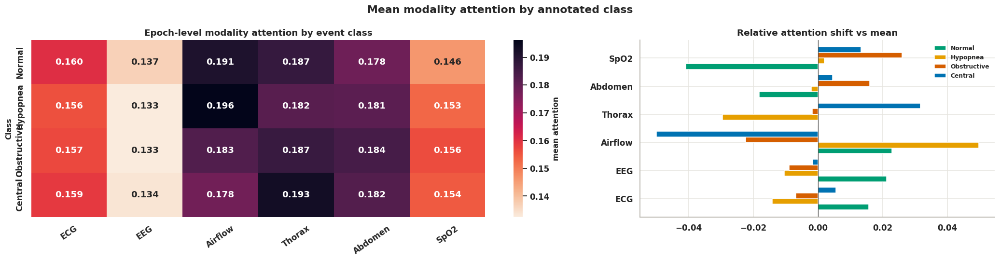

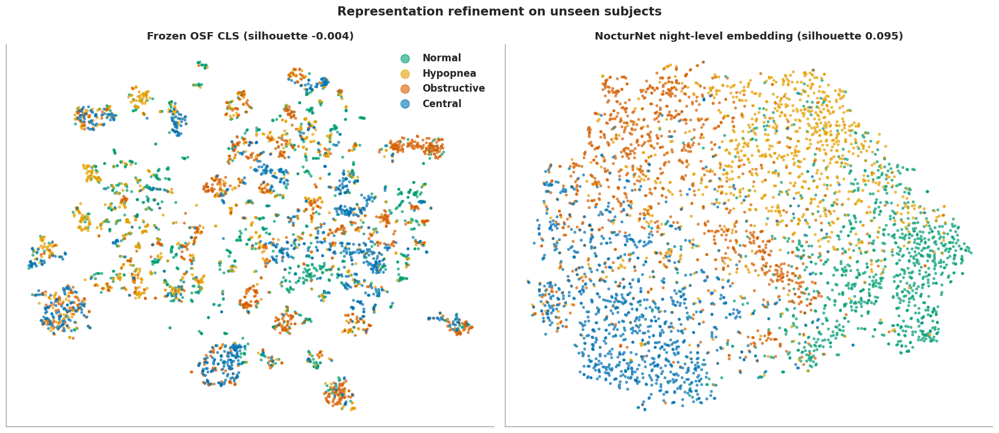

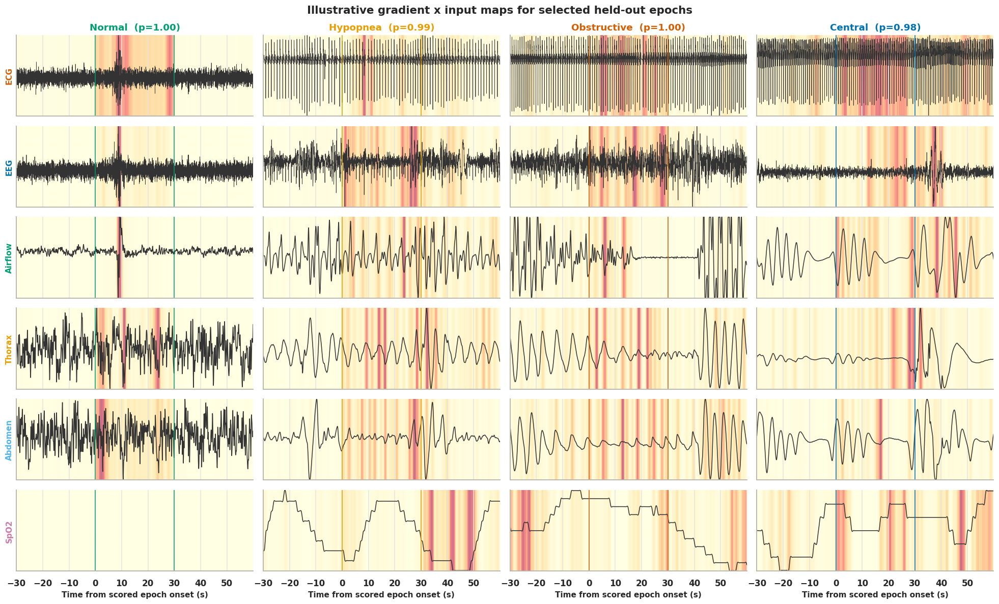

In [18]:
# ===================== STAGE 14  =====================
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
ii = np.concatenate([IDX["test"], IDX["external"]])
tok_names = (MODS + ["OSF CLS"] + [f"OSF G{g+1}" for g in range(N_GRP)])[:PRED["w"].shape[1]]
fig, ax = plt.subplots(1, 2, figsize=(19, 5), gridspec_kw={"width_ratios": [1.6, 1]})
wd = pd.DataFrame(PRED["w"][ii], columns=tok_names).assign(Class=np.array(CFG["classes"])[Y[ii]])
wm = wd.groupby("Class").mean().reindex(CFG["classes"])
sns.heatmap(wm, annot=True, fmt=".3f", cmap="rocket_r", ax=ax[0], cbar_kws={"label": "mean attention"})
ax[0].set_title("Epoch-level modality attention by event class"); ax[0].tick_params(axis="x", rotation=35)
(wm.div(wm.mean(0), axis=1) - 1).T.plot(kind="barh", ax=ax[1], color=CCOL, width=.8, edgecolor="white")
ax[1].axvline(0, color="#555", lw=.8); ax[1].set_title("Relative attention shift vs mean"); ax[1].legend(frameon=False, fontsize=8)
fig.suptitle("Mean modality attention by annotated class", fontweight="bold"); plt.tight_layout(); savefig(fig, "12_token_attention")

rs = np.random.default_rng(1)
sub = np.concatenate([rs.choice(ii[Y[ii] == k], min((Y[ii] == k).sum(), CFG["tsne_n"] // 4), replace=False) for k in range(4) if (Y[ii] == k).any()])
TSP = os.path.join(DIRS["results"], f"tsne_{TAG(PROPOSED)}.npz")
if os.path.exists(TSP) and len(np.load(TSP)["sub"]) == len(sub): E2 = np.load(TSP)["e"]; sub = np.load(TSP)["sub"]
else: E2 = TSNE(2, perplexity=35, init="pca", random_state=0).fit_transform(PRED["emb"][sub]); np.savez(TSP, e=E2, sub=sub)
E1 = TSNE(2, perplexity=35, init="pca", random_state=0).fit_transform(FM[sub, 0].astype(np.float32))
s1, s2 = silhouette_score(FM[sub, 0].astype(np.float32), Y[sub]), silhouette_score(PRED["emb"][sub], Y[sub])
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, E_, t in [(ax[0], E1, f"Frozen OSF CLS (silhouette {s1:.3f})"), (ax[1], E2, f"NocturNet night-level embedding (silhouette {s2:.3f})")]:
    for k, c in enumerate(CFG["classes"]): s = Y[sub] == k; a.scatter(E_[s, 0], E_[s, 1], s=6, alpha=.6, color=PAL[c], label=c)
    a.set_title(t); a.set_xticks([]); a.set_yticks([])
ax[0].legend(frameon=False, markerscale=4)
fig.suptitle("Representation refinement on unseen subjects", fontsize=14, fontweight="bold"); plt.tight_layout(); savefig(fig, "13_embedding_refinement")

m = MODELS[PROPOSED][1]().to(DEV); m.load_state_dict(torch.load(os.path.join(DIRS["checkpoints"], TAG(PROPOSED), "best.pt"), map_location=DEV)); m.eval()
fig, axs = plt.subplots(len(MODS), 4, figsize=(18, 11), sharex="col"); te = IDX["test"]
for k, c in enumerate(CFG["classes"]):
    full = MSK[te].sum(1) == len(MODS); cand = te[(Y[te] == k) & (P[te].argmax(1) == k) & full]; hit = True
    if len(cand) == 0: cand, hit = te[(Y[te] == k) & full], False
    cand = cand[(cand > 0) & (cand < len(Y) - 1)]; cand = cand[(REC[cand - 1] == REC[cand]) & (REC[cand + 1] == REC[cand])]
    if len(cand) == 0: continue
    i = int(cand[np.argmax(P[cand, k])]); a, b = SPAN[REC[i]]; s0 = int(np.clip(i - T_ // 2, a, b - T_)); pos = i - s0
    bb = get_batch(np.array([s0])); bb["xf"].requires_grad_(True); bb["xs"].requires_grad_(True)
    with torch.backends.cudnn.flags(enabled=False): m(bb)["logits"][pos, k].backward()
    for j, md in enumerate(MODS):
        src = bb["xf"] if j < NF else bb["xs"]; jj = j if j < NF else j - NF
        x_ = src[0, pos - 1:pos + 2, jj]; sig = x_.detach().reshape(-1).cpu().numpy()
        gr = (src.grad[0, pos - 1:pos + 2, jj] * x_).abs().reshape(-1).detach().cpu().numpy()
        fs_ = CFG["fs_fast"] if j < NF else CFG["fs_slow"]; gr = np.convolve(gr, np.ones(fs_) / fs_, "same"); t = np.arange(len(sig)) / fs_ - 30
        ax_ = axs[j, k]; ax_.plot(t, sig, color="#333", lw=.5 if j < NF else 1)
        ax_.imshow((gr / (gr.max() + 1e-9))[None], aspect="auto", cmap="YlOrRd", alpha=.55, extent=[t[0], t[-1], sig.min(), sig.max() + 1e-6], vmin=0, vmax=1)
        ax_.axvline(0, color=PAL[c], lw=1); ax_.axvline(30, color=PAL[c], lw=1); ax_.set_yticks([])
        if j == 0: ax_.set_title(f"{c}  (p={P[i, k]:.2f}{'' if hit else ', missed'})", color=PAL[c], fontsize=12)
        if k == 0: ax_.set_ylabel(md, fontweight="bold", color=MPAL[md])
for a in axs[-1]: a.set_xlabel("Time from scored epoch onset (s)")
fig.suptitle("Gradient x input maps for selected held-out epochs", fontsize=14, fontweight="bold"); plt.tight_layout(); savefig(fig, "14_saliency")
set_flag("stage14_explain")

Forward-pass benchmark: Tesla T4, batch 8 windows x 64 epochs, 5 repeats x 20 passes, AMP=True. OSF probe includes separately measured encoder time.


,Trainable_M,Total_M,ms_per_epoch,ms_per_epoch_IQR,Internal_Acc,Internal_F1
NocturNet,1.2151,1.2151,0.0641,0.0001,0.8956,0.6984
DeepSleepNet,24.1713,24.1713,0.0284,0.0001,0.8598,0.6056
TinySleepNet,1.4689,1.4689,0.0177,0.0001,0.8323,0.5543
AttnSleep,0.5969,0.5969,0.0384,0.0009,0.8413,0.5392
SeqSleepNet,0.1628,0.1628,0.0101,0.0000,0.8350,0.5408
SleepTransformer,1.7979,1.7979,0.0287,0.0001,0.8360,0.5792
U-Time,1.1664,1.1664,0.0518,0.0003,0.8590,0.5895
OSF linear probe,0.0184,85.3440,2.4647,0.0000,0.8230,0.5248


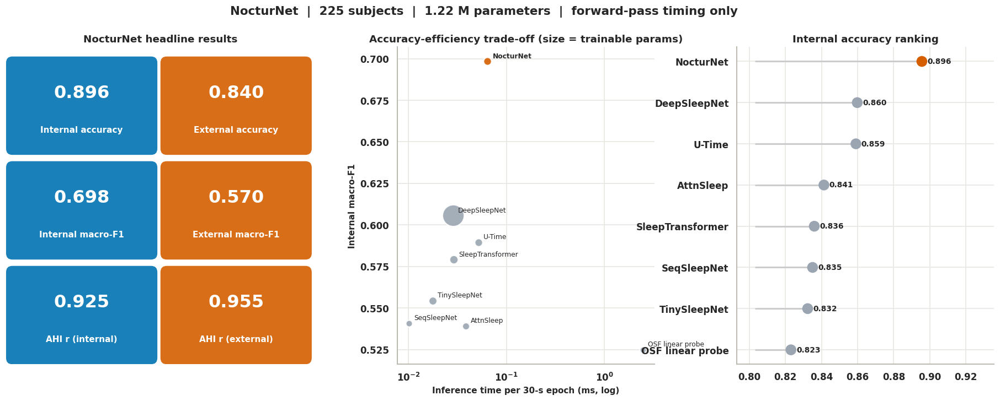

Figures: 28


In [19]:
# ===================== STAGE 15  =====================
GROUP = {n: g for n, (g, _) in MODELS.items()}
if "TABS" not in globals(): TABS = {p: pd.read_csv(os.path.join(DIRS["results"], f"comparison_{p}.csv"), index_col=0) for p in ["test", "external"]}
if "RES" not in globals(): RES = jload(os.path.join(DIRS["results"], "nocturnet_results.json"))
# Forward-pass microbenchmark: same autocast setting for warmup and timed calls.
# This excludes data loading, preprocessing, overlapping-window assembly and output aggregation.
eff = {}
xb = get_batch(windows(SPL["test"], T_)[:8])
bench_hw = torch.cuda.get_device_name(DEV) if DEV.type == "cuda" else str(DEV)
bench_repeats, bench_steps = 5, 20
for n in [k for k in MODELS if GROUP[k] in ("Proposed", "Baseline")]:
    mm = MODELS[n][1]().to(DEV).eval()
    times = []
    with torch.inference_mode():
        for _ in range(8):
            with torch.autocast(device_type=DEV.type, enabled=AMP): mm(xb)
        if DEV.type == "cuda": torch.cuda.synchronize()
        for _ in range(bench_repeats):
            t0 = time.perf_counter()
            for _ in range(bench_steps):
                with torch.autocast(device_type=DEV.type, enabled=AMP): mm(xb)
            if DEV.type == "cuda": torch.cuda.synchronize()
            times.append((time.perf_counter() - t0) * 1000 / (bench_steps * 8 * T_))
    uses_fm = n in FM_MODELS
    eff[n] = dict(Trainable_M=PARAMS[n], Total_M=PARAMS[n] + (OSF_PARAMS if uses_fm else 0),
                  ms_per_epoch=float(np.median(times)) + (OSF_MS if uses_fm else 0),
                  ms_per_epoch_IQR=float(np.percentile(times, 75) - np.percentile(times, 25)),
                  Internal_Acc=TABS["test"].loc[n, "Accuracy"], Internal_F1=TABS["test"].loc[n, "MacroF1"])
    del mm
print(f"Forward-pass benchmark: {bench_hw}, batch 8 windows x {T_} epochs, "
      f"{bench_repeats} repeats x {bench_steps} passes, AMP={AMP}. OSF probe includes separately measured encoder time.")
EFF = pd.DataFrame(eff).T; EFF.to_csv(os.path.join(DIRS["results"], "efficiency.csv")); display(EFF.round(4))

AG = jload(os.path.join(DIRS["results"], "ahi_agreement.json"))
fig = plt.figure(figsize=(21, 6.8)); gs = fig.add_gridspec(1, 3, wspace=.3, width_ratios=[1.2, 1, 1])
ax = fig.add_subplot(gs[0]); ax.axis("off")
tiles = [("Internal accuracy", RES["test"]["overall"]["Accuracy"]), ("External accuracy", RES["external"]["overall"]["Accuracy"]),
         ("Internal macro-F1", RES["test"]["overall"]["MacroF1"]), ("External macro-F1", RES["external"]["overall"]["MacroF1"]),
         ("AHI r (internal)", AG["test"]["pearson"]), ("AHI r (external)", AG["external"]["pearson"])]
for i, (k, v) in enumerate(tiles):
    r, c = divmod(i, 2); x0, y0 = .02 + c * .5, .68 - r * .33
    ax.add_patch(FancyBboxPatch((x0, y0), .45, .27, boxstyle="round,pad=0.02", fc=[DBPAL["Challenge-2018"], DBPAL["UCDDB"]][c], ec="none", alpha=.9, transform=ax.transAxes))
    ax.text(x0 + .225, y0 + .16, f"{v:.3f}", ha="center", fontsize=21, color="white", fontweight="bold", transform=ax.transAxes)
    ax.text(x0 + .225, y0 + .05, k, ha="center", fontsize=10, color="white", transform=ax.transAxes)
ax.set_title("NocturNet headline results", fontsize=12)
ax = fig.add_subplot(gs[1])
for n, r in EFF.iterrows():
    isP = n == PROPOSED
    ax.scatter(r.ms_per_epoch, r.Internal_F1, s=60 + 25 * r.Trainable_M, color="#D55E00" if isP else "#9AA5B1", edgecolor="white", lw=1.5, zorder=3, alpha=.9)
    ax.annotate(n, (r.ms_per_epoch, r.Internal_F1), xytext=(6, 4), textcoords="offset points", fontsize=8, fontweight="bold" if isP else "normal")
ax.set_xscale("log"); ax.set_xlabel("Inference time per 30-s epoch (ms, log)"); ax.set_ylabel("Internal macro-F1"); ax.set_title("Accuracy-efficiency trade-off (size = trainable params)")
ax = fig.add_subplot(gs[2]); T = TABS["test"]; S = T[T.Group.isin(["Proposed", "Baseline"])].sort_values("Accuracy")
ax.hlines(range(len(S)), S.Accuracy.min() - .02, S.Accuracy, color="#ccc", lw=2)
ax.scatter(S.Accuracy, range(len(S)), s=140, color=["#D55E00" if n == PROPOSED else "#9AA5B1" for n in S.index], zorder=3)
for i, v in enumerate(S.Accuracy): ax.text(v + .003, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_yticks(range(len(S))); ax.set_yticklabels(S.index); ax.set_xlim(S.Accuracy.min() - .03, min(1, S.Accuracy.max() + .04)); ax.set_title("Internal accuracy ranking")
fig.suptitle(f"NocturNet  |  {len(META)} subjects  |  {EFF.loc[PROPOSED,'Trainable_M']:.2f} M parameters  |  "
             "forward-pass timing only", fontsize=14, fontweight="bold"); savefig(fig, "15_summary")
set_flag("stage15_summary"); print("Figures:", len(glob.glob(os.path.join(DIRS["figures"], "*.png"))))

test     staging: acc 0.739 | kappa 0.645 | macro-F1 0.711 | sleep/wake acc 0.882
external staging: acc 0.685 | kappa 0.579 | macro-F1 0.646 | sleep/wake acc 0.878


pearson  spearman   bias  loa_lo  loa_hi    MAE  severity_acc  \
part     AHI                                                                   
test     semi    0.954     0.936  0.422  -9.211  10.055  3.680         0.775   
         auto    0.893     0.925  3.072 -12.749  18.893  5.513         0.675   
external semi    0.939     0.878 -5.651 -20.397   9.095  7.581         0.720   
         auto    0.919     0.848 -3.567 -19.735  12.602  7.163         0.720   

               severity_kw  
part     AHI                
test     semi        0.884  
         auto        0.835  
external semi        0.806  
         auto        0.806

Total sleep time error (h, predicted - reference):
          mean   std
part                
external -0.21  0.52
test     -0.64  0.73


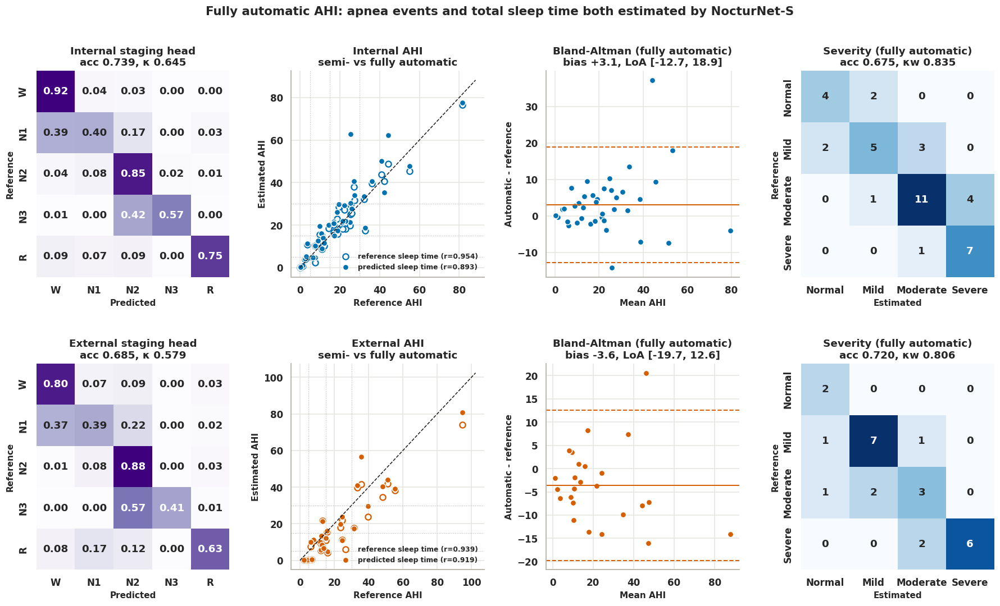

In [20]:
# ===================== STAGE 16  =====================
STAGE_CKPT = os.path.join(DIRS["checkpoints"], TAG(NSV), "best.pt")
sm = MODELS[NSV][1]().to(DEV); sm.load_state_dict(torch.load(STAGE_CKPT, map_location=DEV)); sm.eval()
assert getattr(sm, "aux", False), "The proposed model has no staging head (aux=False); automatic AHI needs it."

AUTO_P = os.path.join(DIRS["results"], f"stage_pred_{TAG(NSV)}.npy")
if os.path.exists(AUTO_P) and len(np.load(AUTO_P)) == len(Y): SP = np.load(AUTO_P)
else:
    acc_s, cnt_s = np.zeros((len(Y), len(STAGE_NAMES)), np.float32), np.zeros(len(Y), np.float32)
    st = windows(SPL["val"] + SPL["test"] + SPL["external"], T_ // 4)
    with torch.no_grad():
        for s in range(0, len(st), 8):
            b = get_batch(st[s:s + 8])
            with torch.autocast(device_type=DEV.type, enabled=AMP): o = sm(b)
            ixn = b["ix"].reshape(-1).cpu().numpy()
            np.add.at(acc_s, ixn, o["stage"].float().log_softmax(1).cpu().numpy()); np.add.at(cnt_s, ixn, 1)
    ok = cnt_s > 0; acc_s[ok] /= cnt_s[ok, None]; SP = np.exp(acc_s); np.save(AUTO_P, SP)
PS = np.load(os.path.join(DIRS['results'], f'pred_{TAG(NSV)}.npz'))['prob']
STG_HAT = SP.argmax(1)                                     # 0 W, 1 N1, 2 N2, 3 N3, 4 R
SLEEP_HAT = STG_HAT > 0

STG_RES = {}
for part in ["test", "external"]:
    ii = IDX[part]; ii = ii[STG_I[ii] >= 0]
    STG_RES[part] = dict(acc=accuracy_score(STG_I[ii], STG_HAT[ii]), kappa=cohen_kappa_score(STG_I[ii], STG_HAT[ii]),
                         macro_f1=f1_score(STG_I[ii], STG_HAT[ii], average="macro"),
                         sleep_wake_acc=accuracy_score(STG_I[ii] > 0, SLEEP_HAT[ii]),
                         cm=confusion_matrix(STG_I[ii], STG_HAT[ii], labels=range(len(STAGE_NAMES))))
    print(f"{part:8s} staging: acc {STG_RES[part]['acc']:.3f} | kappa {STG_RES[part]['kappa']:.3f} | "
          f"macro-F1 {STG_RES[part]['macro_f1']:.3f} | sleep/wake acc {STG_RES[part]['sleep_wake_acc']:.3f}")

tr_ix = IDX["train"]
K_EV = META.loc[SPL["train"], [f"n_{c}" for c in CFG["classes"][1:]]].values.sum() / max((Y[tr_ix] > 0).sum(), 1)
rows = []
for part in ["test", "external"]:
    for r in SPL[part]:
        a, b = SPAN[r]; ev = PS[a:b].argmax(1) > 0
        sl_ref, sl_hat = np.isin(STG[a:b], ["N1", "N2", "N3", "R"]), SLEEP_HAT[a:b]
        tst_ref, tst_hat = max(sl_ref.sum() * 30 / 3600, 1e-3), max(sl_hat.sum() * 30 / 3600, 1e-3)
        rows.append(dict(part=part, rec=r, ref=META.loc[r, "ahi"], semi=K_EV * (ev & sl_ref).sum() / tst_ref,
                         auto=K_EV * (ev & sl_hat).sum() / tst_hat, tst_ref=tst_ref, tst_hat=tst_hat))
AHI3 = pd.DataFrame(rows); AHI3.to_csv(os.path.join(DIRS["results"], "ahi_fully_automatic.csv"), index=False)
sev = lambda v: np.digitize(v, [5, 15, 30]); SEV = ["Normal", "Mild", "Moderate", "Severe"]
def agree(t, col):
    d = t[col] - t.ref
    return dict(pearson=stats.pearsonr(t.ref, t[col])[0], spearman=stats.spearmanr(t.ref, t[col])[0], bias=d.mean(),
                loa_lo=d.mean() - 1.96 * d.std(), loa_hi=d.mean() + 1.96 * d.std(), MAE=d.abs().mean(),
                severity_acc=np.mean(sev(t.ref) == sev(t[col])), severity_kw=cohen_kappa_score(sev(t.ref), sev(t[col]), weights="quadratic"))
AGR = pd.DataFrame({(p, m): agree(AHI3[AHI3.part == p], m) for p in ["test", "external"] for m in ["semi", "auto"]}).T
AGR.index.names = ["part", "AHI"]; AGR.to_csv(os.path.join(DIRS["results"], "ahi_semi_vs_auto.csv")); display(AGR.round(3))
tst_err = AHI3.assign(err=AHI3.tst_hat - AHI3.tst_ref).groupby("part").err.agg(["mean", "std"])
print("Total sleep time error (h, predicted - reference):"); print(tst_err.round(2))
jdump(dict(staging={p: {k: v for k, v in d.items() if k != "cm"} for p, d in STG_RES.items()},
           ahi={f"{p}_{m}": r.to_dict() for (p, m), r in AGR.iterrows()}), os.path.join(DIRS["results"], "ahi_fully_automatic.json"))

fig = plt.figure(figsize=(20, 10.5)); gs = fig.add_gridspec(2, 4, hspace=.42, wspace=.32)
for row, part in enumerate(["test", "external"]):
    t = AHI3[AHI3.part == part]; col = DBPAL["UCDDB" if part == "external" else "Challenge-2018"]; lab = "Internal" if row == 0 else "External"
    ax = fig.add_subplot(gs[row, 0]); cm = STG_RES[part]["cm"]; cn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    sns.heatmap(cn, annot=True, fmt=".2f", cmap="Purples", cbar=False, ax=ax, xticklabels=STAGE_NAMES, yticklabels=STAGE_NAMES)
    ax.set_title(f"{lab} staging head\nacc {STG_RES[part]['acc']:.3f}, κ {STG_RES[part]['kappa']:.3f}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Reference")
    ax = fig.add_subplot(gs[row, 1]); lim = max(t.ref.max(), t.auto.max(), t.semi.max()) * 1.08
    ax.scatter(t.ref, t.semi, s=45, facecolor="white", edgecolor=col, lw=1.5, label=f"reference sleep time (r={AGR.loc[(part,'semi'),'pearson']:.3f})")
    ax.scatter(t.ref, t.auto, s=45, color=col, edgecolor="white", label=f"predicted sleep time (r={AGR.loc[(part,'auto'),'pearson']:.3f})")
    ax.plot([0, lim], [0, lim], "k--", lw=1)
    for x in (5, 15, 30): ax.axvline(x, color="#bbb", ls=":", lw=.8); ax.axhline(x, color="#bbb", ls=":", lw=.8)
    ax.set_xlabel("Reference AHI"); ax.set_ylabel("Estimated AHI"); ax.set_title(f"{lab} AHI\nsemi- vs fully automatic"); ax.legend(frameon=False, fontsize=8)
    ax = fig.add_subplot(gs[row, 2]); m_, d = (t.ref + t.auto) / 2, t.auto - t.ref; g = AGR.loc[(part, "auto")]
    ax.scatter(m_, d, s=45, color=col, edgecolor="white")
    for v, ls in [(g.bias, "-"), (g.loa_lo, "--"), (g.loa_hi, "--")]: ax.axhline(v, color="#D55E00", ls=ls, lw=1.3)
    ax.set_title(f"Bland-Altman (fully automatic)\nbias {g.bias:+.1f}, LoA [{g.loa_lo:.1f}, {g.loa_hi:.1f}]"); ax.set_xlabel("Mean AHI"); ax.set_ylabel("Automatic - reference")
    ax = fig.add_subplot(gs[row, 3]); cm2 = confusion_matrix(sev(t.ref), sev(t.auto), labels=range(4))
    sns.heatmap(cm2, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=SEV, yticklabels=SEV)
    ax.set_title(f"Severity (fully automatic)\nacc {g.severity_acc:.3f}, κw {g.severity_kw:.3f}"); ax.set_xlabel("Estimated"); ax.set_ylabel("Reference")
fig.suptitle("Fully automatic AHI: apnea events and total sleep time both estimated by NocturNet-S", fontsize=14, fontweight="bold")
savefig(fig, "16_ahi_fully_automatic"); set_flag("stage16_auto_ahi")

In [21]:
# ===================== STAGE 17 =====================
LIT = [
    # dict(study="Author et al.", year=2024, dataset="UCDDB", subjects=25, signals="ECG", task="binary per-epoch",
    #      protocol="subject-independent", external=False, metric="Accuracy", value=None, doi="10.xxxx/xxxxx"),
]
if "SEEDS" not in globals(): SEEDS = pd.read_csv(os.path.join(DIRS["results"], "seed_runs.csv"))
S3m = SEEDS.groupby(["part", "model"])[["Accuracy", "MacroF1", "Kappa", "MacroAUROC"]].mean()
OURS = []
for part, ds, n in [("test", "Challenge-2018 (internal)", len(SPL["test"])), ("external", "UCDDB (external)", len(SPL["external"]))]:
    for met in ["Accuracy", "MacroF1", "Kappa"]:
        OURS.append(dict(study="NocturNet (this work)", year=2026, dataset=ds, subjects=n, signals="ECG, EEG, airflow, thorax, abdomen, SpO2",
                         task="4-class apnea typing per 30-s epoch", protocol="subject-independent", external=part == "external",
                         metric=met, value=float(S3m.loc[(part, PROPOSED), met]), doi="-"))
    agr = AGR.loc[(part, "auto")] if "AGR" in globals() else None
    if agr is not None:
        OURS.append(dict(study="NocturNet (this work)", year=2026, dataset=ds, subjects=n, signals="ECG, EEG, airflow, thorax, abdomen, SpO2",
                         task="AHI estimation (fully automatic)", protocol="subject-independent", external=part == "external",
                         metric="AHI Pearson r", value=float(agr.pearson), doi="-"))
COMP = pd.DataFrame(OURS + [r for r in LIT if r.get("value") is not None])
COMP["value"] = COMP.value.astype(float)
COMP.to_csv(os.path.join(DIRS["results"], "literature_context.csv"), index=False)
with open(os.path.join(DIRS["results"], "literature_context.tex"), "w") as f:
    f.write(COMP[["study", "year", "dataset", "subjects", "signals", "task", "protocol", "external", "metric", "value"]]
            .to_latex(index=False, float_format="%.3f"))
display(COMP)
if len(LIT) == 0 or all(r.get("value") is None for r in LIT):
    print("LIT is empty: add verified published results to plot the context figure.")
else:
    mets = [m for m in ["Accuracy", "MacroF1", "Kappa", "AHI Pearson r"] if m in set(COMP.metric)]
    fig, axs = plt.subplots(1, len(mets), figsize=(5.5 * len(mets), max(4, .45 * COMP.groupby("metric").size().max() + 1.5)))
    for ax, met in zip(np.atleast_1d(axs), mets):
        d = COMP[COMP.metric == met].sort_values("value"); lbl = d.study + " | " + d.dataset + "\n" + d.task
        ours = d.study.str.contains("this work")
        ax.barh(range(len(d)), d.value, color=np.where(ours, "#D55E00", "#9AA5B1"), edgecolor="white",
                hatch=None); ax.set_yticks(range(len(d))); ax.set_yticklabels(lbl, fontsize=7.5)
        for i, (v, ext) in enumerate(zip(d.value, d.external)): ax.text(v + .005, i, f"{v:.3f}{' (ext.)' if ext else ''}", va="center", fontsize=8)
        ax.set_xlim(max(0, d.value.min() - .1), min(1.05, d.value.max() + .12)); ax.set_title(met)
    fig.suptitle("NocturNet in the context of published apnea studies (different datasets and protocols: not a direct ranking)",
                 fontsize=12, fontweight="bold"); plt.tight_layout(); savefig(fig, "17_literature_context")
set_flag("stage17_literature")

,study,year,dataset,subjects,signals,task,protocol,external,metric,value,doi
0,NocturNet (this work),2026,Challenge-2018 (internal),40,"ECG, EEG, airflow, thorax, abdomen, SpO2",4-class apnea typing per 30-s epoch,subject-independent,False,Accuracy,0.894656,-
1,NocturNet (this work),2026,Challenge-2018 (internal),40,"ECG, EEG, airflow, thorax, abdomen, SpO2",4-class apnea typing per 30-s epoch,subject-independent,False,MacroF1,0.688043,-
2,NocturNet (this work),2026,Challenge-2018 (internal),40,"ECG, EEG, airflow, thorax, abdomen, SpO2",4-class apnea typing per 30-s epoch,subject-independent,False,Kappa,0.633509,-
3,NocturNet (this work),2026,Challenge-2018 (internal),40,"ECG, EEG, airflow, thorax, abdomen, SpO2",AHI estimation (fully automatic),subject-independent,False,AHI Pearson r,0.892756,-
4,NocturNet (this work),2026,UCDDB (external),25,"ECG, EEG, airflow, thorax, abdomen, SpO2",4-class apnea typing per 30-s epoch,subject-independent,True,Accuracy,0.838183,-
5,NocturNet (this work),2026,UCDDB (external),25,"ECG, EEG, airflow, thorax, abdomen, SpO2",4-class apnea typing per 30-s epoch,subject-independent,True,MacroF1,0.556833,-
6,NocturNet (this work),2026,UCDDB (external),25,"ECG, EEG, airflow, thorax, abdomen, SpO2",4-class apnea typing per 30-s epoch,subject-independent,True,Kappa,0.494291,-
7,NocturNet (this work),2026,UCDDB (external),25,"ECG, EEG, airflow, thorax, abdomen, SpO2",AHI estimation (fully automatic),subject-independent,True,AHI Pearson r,0.919488,-


LIT is empty: add verified published results to plot the context figure.


SLPDB: 18 cached, 0 to fetch/process
SLPDB: 18 records / 16 subjects / 10185 labelled epochs | class counts [6846, 966, 2142, 231]
SLPDB predictions: 18 runs

==== SLPDB (second external cohort) ====


,Accuracy,BalancedAcc,MacroF1,WeightedF1,Kappa,MCC,MacroAUROC,MacroAUPRC,Params_M,dF1,dF1_lo,dF1_hi,Wilcoxon_p
NocturNet,0.6806,0.5300,0.4717,0.6929,0.3819,0.3841,0.7751,0.4589,1.2151,NaN,NaN,NaN,NaN
DeepSleepNet,0.6665,0.5021,0.4390,0.6774,0.3466,0.3506,0.7746,0.4420,24.1713,0.0327,0.0055,0.0691,0.1167
TinySleepNet,0.6576,0.4750,0.4159,0.6634,0.3129,0.3191,0.7605,0.4341,1.4689,0.0558,0.0034,0.1406,0.1297
AttnSleep,0.6426,0.4091,0.3557,0.6291,0.2408,0.2509,0.7165,0.3859,0.5969,0.1160,0.0557,0.1825,0.0045
SeqSleepNet,0.6418,0.4536,0.4129,0.6551,0.3128,0.3153,0.7296,0.3908,0.1628,0.0588,0.0122,0.1077,0.2114
SleepTransformer,0.6173,0.4217,0.3670,0.6261,0.2493,0.2544,0.7106,0.3665,1.7979,0.1047,0.0305,0.1698,0.0250
U-Time,0.6674,0.4875,0.4327,0.6724,0.3367,0.3395,0.7651,0.4139,1.1664,0.0390,-0.0005,0.0840,0.4954
NocturNet-S (+ staging head),0.6795,0.5226,0.4682,0.6944,0.3875,0.3901,0.7698,0.4530,1.2164,0.0035,-0.0158,0.0270,0.6322
w/o acquisition randomisation,0.6514,0.5193,0.4325,0.6693,0.3384,0.3444,0.7840,0.4527,1.2151,0.0391,0.0030,0.0858,0.1252
+ montage dropout,0.6781,0.5163,0.4634,0.6902,0.3787,0.3806,0.7740,0.4624,1.2151,0.0082,-0.0089,0.0288,0.5619


{'MacroF1': (np.float64(0.3855), np.float64(0.5443)), 'Accuracy': (np.float64(0.6072), np.float64(0.7585)), 'Kappa': (np.float64(0.2341), np.float64(0.5176))}


Accuracy         MacroF1           Kappa         MacroAUROC  \
                 mean     std    mean     std    mean     std       mean   
model                                                                      
DeepSleepNet   0.6645  0.0020  0.4330  0.0088  0.3369  0.0088     0.7734   
NocturNet      0.6752  0.0140  0.4607  0.0114  0.3706  0.0098     0.7673   
U-Time         0.6695  0.0068  0.4477  0.0131  0.3526  0.0147     0.7738   

                      
                 std  
model                 
DeepSleepNet  0.0081  
NocturNet     0.0079  
U-Time        0.0076

SLPDB NocturNet - DeepSleepNet: ΔF1 per seed [0.0327 0.0117 0.0388] | mean +0.0277 | wins 3/3
SLPDB NocturNet - U-Time      : ΔF1 per seed [ 0.039  -0.0044  0.0046] | mean +0.0130 | wins 2/3

3-seed ensembles, macro-F1 by cohort:


cohort,Internal,SLPDB,UCDDB
model,,,
DeepSleepNet (3-seed ensemble),0.5986,0.4456,0.5308
NocturNet (3-seed ensemble),0.6994,0.4717,0.5693
U-Time (3-seed ensemble),0.6083,0.4691,0.5612


SLPDB, NocturNet ensemble minus baseline ensemble:


,dF1,dF1_lo,dF1_hi,Wilcoxon_p
DeepSleepNet,0.0261,-0.0008,0.0632,0.2744
U-Time,0.0026,-0.0269,0.0341,0.9799


Event-epoch index (event epochs per hour of sleep): Pearson r 0.576 | bias +2.14


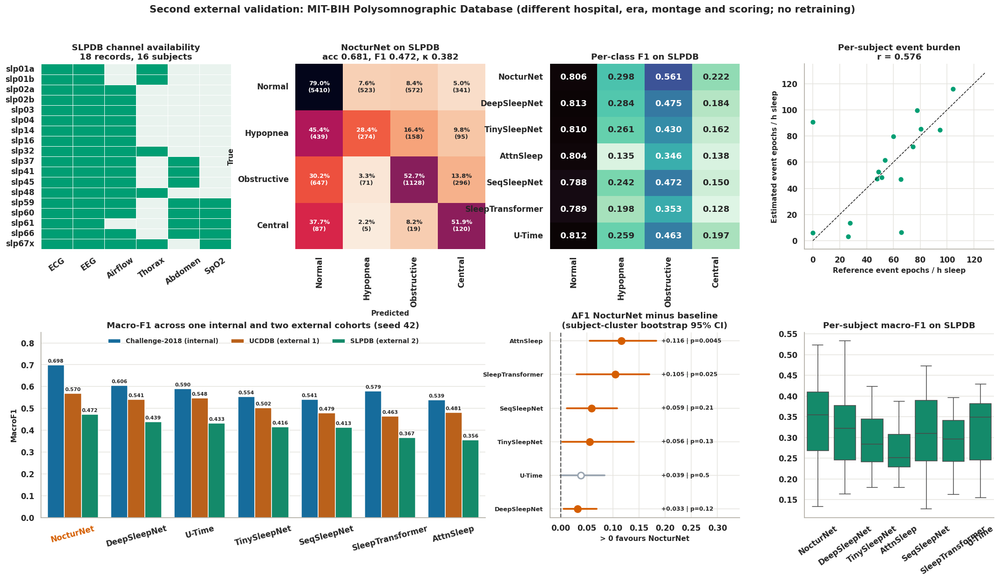

In [22]:
# ===================== STAGE 18 =====================
SLP_PROC = os.path.join(os.path.dirname(DIRS["proc_c18"]), "proc_slp"); os.makedirs(SLP_PROC, exist_ok=True)
SLP_RES = os.path.join(DIRS["results"], "slpdb"); os.makedirs(SLP_RES, exist_ok=True)
DBPAL.setdefault("SLPDB", "#009E73")
for mod, extra in [("Airflow", ["nasal"]), ("Thorax", ["resp(sum)"]), ("SpO2", ["so2"])]:
    ALIASES[mod] += [a for a in extra if a not in ALIASES[mod]]
SLP_STAGE = {"W": "W", "1": "N1", "2": "N2", "3": "N3", "4": "N3", "R": "R", "MT": "U"}
SLP_EV = {"H": 1, "HA": 1, "OA": 2, "X": 2, "CA": 3, "CAA": 3}
def slp_urls(p): return [f"https://physionet-open.s3.amazonaws.com/slpdb/1.0.0/{p}", f"https://physionet.org/files/slpdb/1.0.0/{p}"]

def parse_slp(path):
    rec = wfdb.rdrecord(path); fs = rec.fs; sig = np.nan_to_num(rec.p_signal.T.astype(np.float64))
    ann = wfdb.rdann(path, "st"); s0 = int(ann.sample[0]); n = int((sig.shape[1] - s0) // (30 * fs))
    stages, y, lab = ["U"] * n, np.zeros(n, np.int8), np.zeros(n, bool)
    for smp, aux in zip(ann.sample, ann.aux_note):
        e = int(round((smp - s0) / (30 * fs)))
        if not 0 <= e < n: continue
        tok = (aux or "").replace("\x00", "").split()
        if not tok: continue
        stages[e] = SLP_STAGE.get(tok[0], "U"); lab[e] = True
        ev = [SLP_EV[t] for t in tok[1:] if t in SLP_EV]
        if ev: y[e] = max(ev)
    d = build_epochs(sig[:, s0:], fs, rec.sig_name, [], stages, n_ep_hint=n)
    n = len(d["y"]); d["y"] = np.where(lab[:n], y[:n], -1).astype(np.int8)
    return d

slp_list_p = os.path.join(SLP_PROC, "records.json")
if not os.path.exists(slp_list_p):
    txt = fetch(slp_urls("RECORDS"), os.path.join(TMP, "slp_RECORDS"))
    jdump([l.strip() for l in open(txt) if l.strip()], slp_list_p)
SLP_RECS = jload(slp_list_p)
def do_slp(r):
    out = os.path.join(SLP_PROC, r + ".npz")
    if os.path.exists(out): return r, "cached"
    base = os.path.join(TMP, r)
    for ext in [".hea", ".dat", ".st"]: fetch(slp_urls(r + ext), base + ext)
    save_proc(parse_slp(base), out)
    for ext in [".hea", ".dat", ".st"]:
        if os.path.exists(base + ext) and IN_COLAB: os.remove(base + ext)
    return r, "processed"
todo = [r for r in SLP_RECS if not os.path.exists(os.path.join(SLP_PROC, r + ".npz"))]
print(f"SLPDB: {len(SLP_RECS) - len(todo)} cached, {len(todo)} to fetch/process")
with ThreadPoolExecutor(CFG["dl_workers"]) as ex:
    for fu in as_completed([ex.submit(do_slp, r) for r in todo]):
        try: print("  ", *fu.result())
        except Exception as e: print("  skip ->", str(e)[:120])

SR = [dict(np.load(os.path.join(SLP_PROC, r + ".npz"), allow_pickle=True), rec=r) for r in SLP_RECS if os.path.exists(os.path.join(SLP_PROC, r + ".npz"))]
SR = [d for d in SR if len(d["y"]) >= T_]
if not SR: raise RuntimeError("No SLPDB records available.")
XF2 = torch.from_numpy(np.concatenate([d["XF"] for d in SR])).to(DEV); XS2 = torch.from_numpy(np.concatenate([d["XS"] for d in SR])).to(DEV)
M2 = torch.from_numpy(np.concatenate([np.repeat(d["mask"][None], len(d["y"]), 0) for d in SR])).to(DEV)
Y2 = np.concatenate([d["y"] for d in SR]).astype(np.int64); STG2 = np.concatenate([d["stage"] for d in SR])
REC2 = np.concatenate([[d["rec"]] * len(d["y"]) for d in SR]); SUBJ2 = np.array([re.sub(r"[ab]$", "", r) for r in REC2])
SPAN2, s0 = {}, 0
for d in SR: SPAN2[d["rec"]] = (s0, s0 + len(d["y"])); s0 += len(d["y"])
V2 = np.where(Y2 >= 0)[0]
SLP_META = pd.DataFrame([dict(rec=d["rec"], hours=len(d["y"]) / 120, **{f"n_{c}": int((d["y"] == k).sum()) for k, c in enumerate(CFG["classes"])},
                              **{m: int(v) for m, v in zip(MODS, d["mask"])}) for d in SR]).set_index("rec")
SLP_META.to_csv(os.path.join(SLP_RES, "slpdb_inventory.csv"))
print(f"SLPDB: {len(SR)} records / {len(np.unique(SUBJ2))} subjects / {len(V2)} labelled epochs | class counts {np.bincount(Y2[V2], minlength=4).tolist()}")

@torch.no_grad()
def predict_slp(model):
    model.eval(); N = len(Y2); acc = np.zeros((N, 4), np.float32); cnt = np.zeros(N, np.float32); stg = None
    st = []
    for a, b in SPAN2.values():
        s_ = list(range(a, b - T_ + 1, T_ // 4))
        if s_[-1] != b - T_: s_.append(b - T_)
        st += s_
    st = np.array(st); ngrp = globals().get("N_GRP", 3)
    for s in range(0, len(st), 8):
        ix = torch.as_tensor(st[s:s + 8], device=DEV)[:, None] + AR; m = M2[ix].float()
        bt = dict(xf=XF2[ix].float() * m[..., :NF, None], xs=XS2[ix].float() * m[..., NF:, None], m=m, ix=ix,
                  fm=torch.zeros(len(ix), T_, 1 + ngrp, 768, device=DEV))
        with torch.autocast(device_type=DEV.type, enabled=AMP): o = model(bt)
        ixn = ix.reshape(-1).cpu().numpy(); np.add.at(acc, ixn, o["logits"].float().log_softmax(1).cpu().numpy()); np.add.at(cnt, ixn, 1)
        if "stage" in o:
            if stg is None: stg = np.zeros((N, o["stage"].shape[-1]), np.float32)
            np.add.at(stg, ixn, o["stage"].float().log_softmax(1).cpu().numpy())
    ok = cnt > 0; acc[ok] /= cnt[ok, None]
    if stg is not None: stg[ok] /= cnt[ok, None]
    return acc, stg

SLP_MODELS = [n for n in MODELS if n not in FM_MODELS]
RUNS = [(n, None) for n in SLP_MODELS] + [(n, sd) for n in SEEDED for sd in CFG["seeds"][1:]]
PR2, SG2 = {}, None
for n, sd in RUNS:
    out = os.path.join(SLP_RES, f"slp_pred_{TAG(n, sd)}.npz"); ck = os.path.join(DIRS["checkpoints"], TAG(n, sd), "best.pt")
    if not os.path.exists(out):
        cp = os.path.join(DIRS["results"], f"pred_{TAG(n, sd)}.npz")
        if not (os.path.exists(ck) and os.path.exists(cp) and os.path.exists(os.path.join(DIRS["checkpoints"], TAG(n, sd), "done.json"))):
            print(f"  skip {TAG(n, sd)}: training not finished (re-run its stage; it resumes from the last epoch)"); continue
        m = MODELS[n][1]().to(DEV); m.load_state_dict(torch.load(ck, map_location=DEV)); lp, sg = predict_slp(m)
        cal = np.load(os.path.join(DIRS["results"], f"pred_{TAG(n, sd)}.npz"))
        extra = dict(stage=np.exp(sg)) if sg is not None else {}
        np.savez(out, prob=softmax_np(lp / float(cal["T"]) + cal["bias"]).astype(np.float32), **extra); del m
    z = np.load(out); PR2[(n, sd or CFG["seed"])] = z["prob"]
    if n == PROPOSED and sd is None and "stage" in z: SG2 = z["stage"]
print("SLPDB predictions:", len(PR2), "runs")

G2 = {s: V2[SUBJ2[V2] == s] for s in np.unique(SUBJ2[V2])}; S_ = np.array(list(G2))
def boot2(p, n=CFG["n_boot"]):
    rs = np.random.default_rng(0); v = []
    for _ in range(n):
        ii = np.concatenate([G2[s] for s in rs.choice(S_, len(S_))]); yh = p[ii].argmax(1)
        v.append([f1_score(Y2[ii], yh, average="macro"), accuracy_score(Y2[ii], yh), cohen_kappa_score(Y2[ii], yh)])
    v = np.array(v); return {k: (np.percentile(v[:, j], 2.5), np.percentile(v[:, j], 97.5)) for j, k in enumerate(["MacroF1", "Accuracy", "Kappa"])}
# Keep the point difference consistent with the displayed pooled macro-F1 values.
def dboot2(pa, pb, n=CFG["n_boot"]):
    rs = np.random.default_rng(7); d = []
    for _ in range(n):
        ii = np.concatenate([G2[s] for s in rs.choice(S_, len(S_))])
        d.append(f1_score(Y2[ii], pa[ii].argmax(1), average="macro") - f1_score(Y2[ii], pb[ii].argmax(1), average="macro"))
    point = f1_score(Y2[V2], pa[V2].argmax(1), average="macro") - f1_score(Y2[V2], pb[V2].argmax(1), average="macro")
    return point, np.percentile(d, 2.5), np.percentile(d, 97.5)
def subj2(p): return np.array([f1_score(Y2[G2[s]], p[G2[s]].argmax(1), average="macro") for s in S_])

P2 = PR2[(PROPOSED, CFG["seed"])]; rows = {}
for n in SLP_MODELS:
    if (n, CFG["seed"]) not in PR2: continue
    p = PR2[(n, CFG["seed"])]; r = metrics(Y2[V2], p[V2]); r["Group"] = MODELS[n][0]; r["Params_M"] = PARAMS.get(n, np.nan)
    if n != PROPOSED:
        mu, lo, hi = dboot2(P2, p); r.update(dF1=mu, dF1_lo=lo, dF1_hi=hi)
        a_, b_ = subj2(P2), subj2(p); r["Wilcoxon_p"] = stats.wilcoxon(a_, b_).pvalue if np.any(a_ != b_) else 1.0
    rows[n] = r
T2 = pd.DataFrame(rows).T; num2 = T2.drop(columns="Group").apply(pd.to_numeric, errors="coerce")
num2.to_csv(os.path.join(SLP_RES, "comparison_slpdb.csv"))
with open(os.path.join(SLP_RES, "comparison_slpdb.tex"), "w") as f: f.write(num2.to_latex(float_format="%.4f", na_rep="-"))
print("\n==== SLPDB (second external cohort) ===="); display(num2.round(4))
CI2 = boot2(P2); print({k: tuple(round(x, 4) for x in v) for k, v in CI2.items()})

srow = [dict(model=n, seed=sd, **metrics(Y2[V2], p[V2])) for (n, sd), p in PR2.items() if n in SEEDED]
SEEDS2 = pd.DataFrame(srow); SEEDS2.to_csv(os.path.join(SLP_RES, "seed_runs_slpdb.csv"), index=False)
SUMM2 = SEEDS2.groupby("model")[["Accuracy", "MacroF1", "Kappa", "MacroAUROC"]].agg(["mean", "std"]).round(4)
SUMM2.to_csv(os.path.join(SLP_RES, "seed_summary_slpdb.csv")); display(SUMM2)
for b in SEEDED[1:]:
    a_, b_ = SEEDS2[SEEDS2.model == PROPOSED].set_index("seed").MacroF1, SEEDS2[SEEDS2.model == b].set_index("seed").MacroF1
    d = (a_ - b_).dropna(); print(f"SLPDB {PROPOSED} - {b:12s}: ΔF1 per seed {np.round(d.values, 4)} | mean {d.mean():+.4f} | wins {(d > 0).sum()}/{len(d)}")

def ens_prob(n, src):
    ps = [src(n, sd) for sd in CFG["seeds"]]
    return None if any(p is None for p in ps) else np.mean(ps, 0)
def _slp(n, sd): return PR2.get((n, sd))
def _dev(n, sd):
    f = os.path.join(DIRS["results"], f"pred_{TAG(n, None if sd == CFG['seed'] else sd)}.npz")
    return np.load(f)["prob"] if os.path.exists(f) else None
ENS2 = {n: ens_prob(n, _slp) for n in SEEDED}; ENS2 = {n: p for n, p in ENS2.items() if p is not None}
ENSD = {n: ens_prob(n, _dev) for n in ENS2}
rows = []
for n in ENS2:
    for cohort, y_, p_ in [("Internal", Y[IDX["test"]], ENSD[n][IDX["test"]]), ("UCDDB", Y[IDX["external"]], ENSD[n][IDX["external"]]), ("SLPDB", Y2[V2], ENS2[n][V2])]:
        rows.append(dict(model=f"{n} (3-seed ensemble)", cohort=cohort, **metrics(y_, p_)))
ENS_ALL = pd.DataFrame(rows); ENS_ALL.to_csv(os.path.join(SLP_RES, "ensemble_all_cohorts.csv"), index=False)
print("\n3-seed ensembles, macro-F1 by cohort:"); display(ENS_ALL.pivot(index="model", columns="cohort", values="MacroF1").round(4))
if PROPOSED in ENS2:
    rows = {}
    for b in [n for n in ENS2 if n != PROPOSED]:
        mu, lo, hi = dboot2(ENS2[PROPOSED], ENS2[b]); a_, b_ = subj2(ENS2[PROPOSED]), subj2(ENS2[b])
        rows[b] = dict(dF1=mu, dF1_lo=lo, dF1_hi=hi, Wilcoxon_p=stats.wilcoxon(a_, b_).pvalue if np.any(a_ != b_) else 1.0)
    ENS_D = pd.DataFrame(rows).T; ENS_D.to_csv(os.path.join(SLP_RES, "ensemble_delta_slpdb.csv"))
    print(f"SLPDB, {PROPOSED} ensemble minus baseline ensemble:"); display(ENS_D.round(4))

STG2_I = np.array([STAGE_NAMES.index(s) if s in STAGE_NAMES else -1 for s in STG2]); SRES = {}
if SG2 is not None:
    ss = np.where(STG2_I >= 0)[0]; sh = SG2.argmax(1)
    SRES = dict(acc=accuracy_score(STG2_I[ss], sh[ss]), kappa=cohen_kappa_score(STG2_I[ss], sh[ss]), macro_f1=f1_score(STG2_I[ss], sh[ss], average="macro"),
                sleep_wake_acc=accuracy_score(STG2_I[ss] > 0, sh[ss] > 0))
    print(f"SLPDB staging: acc {SRES['acc']:.3f} | kappa {SRES['kappa']:.3f} | macro-F1 {SRES['macro_f1']:.3f} | sleep/wake acc {SRES['sleep_wake_acc']:.3f}")
slp_sleep = np.isin(STG2, ["N1", "N2", "N3", "R"]); rows = []
for s, ii in G2.items():
    sl = ii[slp_sleep[ii]]; h = max(len(sl) * 30 / 3600, 1e-3)
    rows.append(dict(subject=s, ref=(Y2[sl] > 0).sum() / h, est=(P2[sl].argmax(1) > 0).sum() / h))
BUR = pd.DataFrame(rows); BUR.to_csv(os.path.join(SLP_RES, "event_epoch_index_slpdb.csv"), index=False)
bur_r = stats.pearsonr(BUR.ref, BUR.est)[0] if len(BUR) > 2 else np.nan
print(f"Event-epoch index (event epochs per hour of sleep): Pearson r {bur_r:.3f} | bias {(BUR.est - BUR.ref).mean():+.2f}")
jdump(dict(proposed=PROPOSED, overall=metrics(Y2[V2], P2[V2]), ci=CI2, staging=SRES, event_epoch_index_r=bur_r, n_records=len(SR), n_subjects=len(S_),
           n_epochs=int(len(V2))), os.path.join(SLP_RES, "proposed_slpdb.json"))

# ---- figure
fig = plt.figure(figsize=(24, 11.5)); gs = fig.add_gridspec(2, 4, hspace=.45, wspace=.34)
ax = fig.add_subplot(gs[0, 0])
sns.heatmap(SLP_META[MODS], cmap=sns.light_palette(DBPAL["SLPDB"], as_cmap=True), cbar=False, linewidths=.5, linecolor="white", ax=ax)
ax.set_title(f"SLPDB channel availability\n{len(SR)} records, {len(S_)} subjects"); ax.set_ylabel(""); ax.tick_params(axis="x", rotation=35)
ax = fig.add_subplot(gs[0, 1]); cm = confusion_matrix(Y2[V2], P2[V2].argmax(1), labels=range(4)); cn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
sns.heatmap(cn, annot=np.array([[f"{cn[i,j]*100:.1f}%\n({cm[i,j]})" for j in range(4)] for i in range(4)]), fmt="", cmap="rocket_r", cbar=False,
            ax=ax, xticklabels=CFG["classes"], yticklabels=CFG["classes"], annot_kws={"fontsize": 8.5})
r2 = metrics(Y2[V2], P2[V2]); ax.set_title(f"{PROPOSED} on SLPDB\nacc {r2['Accuracy']:.3f}, F1 {r2['MacroF1']:.3f}, κ {r2['Kappa']:.3f}")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax = fig.add_subplot(gs[0, 2]); base = [n for n in SLP_MODELS if MODELS[n][0] in ("Proposed", "Baseline") and (n, CFG["seed"]) in PR2]
pcf = pd.DataFrame({n: f1_score(Y2[V2], PR2[(n, CFG["seed"])][V2].argmax(1), labels=range(4), average=None, zero_division=0) for n in base}, index=CFG["classes"]).T
sns.heatmap(pcf, annot=True, fmt=".3f", cmap="mako_r", ax=ax, cbar=False); ax.set_title("Per-class F1 on SLPDB")
ax = fig.add_subplot(gs[0, 3]); lim = max(BUR.ref.max(), BUR.est.max()) * 1.1 + 1
ax.scatter(BUR.ref, BUR.est, s=60, color=DBPAL["SLPDB"], edgecolor="white"); ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set_xlabel("Reference event epochs / h sleep"); ax.set_ylabel("Estimated event epochs / h sleep"); ax.set_title(f"Per-subject event burden\nr = {bur_r:.3f}")
ax = fig.add_subplot(gs[1, 0:2]); coh = []
for part, lab in [("test", "Challenge-2018 (internal)"), ("external", "UCDDB (external 1)")]:
    p_ = os.path.join(DIRS["results"], f"comparison_{part}.csv")
    if os.path.exists(p_): c_ = pd.read_csv(p_, index_col=0); coh += [dict(model=n, cohort=lab, MacroF1=float(c_.loc[n, "MacroF1"])) for n in base if n in c_.index]
coh += [dict(model=n, cohort="SLPDB (external 2)", MacroF1=float(num2.loc[n, "MacroF1"])) for n in base]
CO = pd.DataFrame(coh); order = CO[CO.cohort.str.startswith("SLPDB")].sort_values("MacroF1", ascending=False).model.tolist()
sns.barplot(data=CO, x="model", y="MacroF1", hue="cohort", order=order, ax=ax, palette=[DBPAL["Challenge-2018"], DBPAL["UCDDB"], DBPAL["SLPDB"]][:CO.cohort.nunique()], edgecolor="white")
for cont in ax.containers: ax.bar_label(cont, fmt="%.3f", fontsize=7, padding=2)
ax.set_ylim(0, CO.MacroF1.max() + .15); ax.set_xlabel(""); ax.set_title("Macro-F1 across one internal and two external cohorts (seed 42)")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper center"); ax.tick_params(axis="x", rotation=15)
for t in ax.get_xticklabels():
    if t.get_text() == PROPOSED: t.set_fontweight("bold"); t.set_color("#D55E00")
ax = fig.add_subplot(gs[1, 2]); D = num2.drop(PROPOSED).loc[[n for n in base if n != PROPOSED]].sort_values("dF1")
for i, (n, r) in enumerate(D.iterrows()):
    sig = r.dF1_lo > 0 or r.dF1_hi < 0; c = "#9AA5B1" if not sig else ("#D55E00" if r.dF1 > 0 else "#0072B2")
    ax.plot([r.dF1_lo, r.dF1_hi], [i, i], color=c, lw=2.5); ax.scatter(r.dF1, i, s=80, color=c if sig else "white", edgecolor=c, lw=2, zorder=3)
    ax.text(max(D.dF1_hi.max(), 0) + .01, i, f"{r.dF1:+.3f} | p={r.Wilcoxon_p:.2g}", va="center", fontsize=8)
ax.axvline(0, color="#555", ls="--"); ax.set_yticks(range(len(D))); ax.set_yticklabels(D.index, fontsize=8.5)
ax.set_xlim(min(D.dF1_lo.min(), 0) - .02, max(D.dF1_hi.max(), 0) + .16)
ax.set_title(f"ΔF1 {PROPOSED} minus baseline\n(subject-cluster bootstrap 95% CI)"); ax.set_xlabel("> 0 favours NocturNet")
ax = fig.add_subplot(gs[1, 3])
if SG2 is not None:
    cs = confusion_matrix(STG2_I[ss], sh[ss], labels=range(len(STAGE_NAMES))); csn = cs / np.maximum(cs.sum(1, keepdims=True), 1)
    sns.heatmap(csn, annot=True, fmt=".2f", cmap="Purples", cbar=False, ax=ax, xticklabels=STAGE_NAMES, yticklabels=STAGE_NAMES)
    ax.set_title(f"Staging head on SLPDB\nacc {SRES['acc']:.3f}, κ {SRES['kappa']:.3f}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Reference")
else:
    sf = pd.DataFrame({n: subj2(PR2[(n, CFG["seed"])]) for n in base}); sns.boxplot(data=sf, ax=ax, color=DBPAL["SLPDB"]); ax.tick_params(axis="x", rotation=35)
    ax.set_title("Per-subject macro-F1 on SLPDB")
fig.suptitle("Second external validation: MIT-BIH Polysomnographic Database (different hospital, era, montage and scoring; no retraining)",
             fontsize=14, fontweight="bold")
savefig(fig, "18_external2_slpdb"); set_flag("stage18_slpdb")

Macro-F1 before / after unsupervised label-shift adaptation (seed 42):


F1_primary                 F1_adapted          \
cohort                          Internal   SLPDB   UCDDB   Internal   SLPDB   
model                                                                         
+ montage dropout                 0.6925  0.4634  0.5660     0.6846  0.4082   
AttnSleep                         0.5392  0.3557  0.4805     0.5388  0.2888   
DeepSleepNet                      0.6056  0.4390  0.5411     0.6037  0.3638   
NocturNet                         0.6984  0.4717  0.5697     0.6962  0.3779   
NocturNet-S (+ staging head)      0.6922  0.4682  0.5620     0.6883  0.3308   
SeqSleepNet                       0.5408  0.4129  0.4792     0.5377  0.3586   
SleepTransformer                  0.5792  0.3670  0.4634     0.5596  0.2642   
TinySleepNet                      0.5543  0.4159  0.5018     0.5472  0.3364   
U-Time                            0.5895  0.4327  0.5483     0.5748  0.3634   
w/o SpO2                          0.6534  0.4795  0.5469     0.6445  0.4637   
w/o acquisition randomisation     0.6576  0.4325  0.5318     0.6511  0.3328   
w/o night-level context           0.6276  0.3735  0.5407     0.6254  0.3745   

                                       
cohort                          UCDDB  
model                                  
+ montage dropout              0.5782  
AttnSleep                      0.4159  
DeepSleepNet                   0.5254  
NocturNet                      0.5034  
NocturNet-S (+ staging head)   0.5522  
SeqSleepNet                    0.4087  
SleepTransformer               0.4395  
TinySleepNet                   0.4202  
U-Time                         0.5607  
w/o SpO2                       0.5346  
w/o acquisition randomisation  0.4888  
w/o night-level context        0.4900

F1_primary         F1_adapted        
                            mean     std       mean     std
cohort   model                                             
Internal DeepSleepNet     0.5943  0.0111     0.5938  0.0099
         NocturNet        0.6880  0.0122     0.6798  0.0170
         U-Time           0.5832  0.0055     0.5761  0.0011
SLPDB    DeepSleepNet     0.4330  0.0088     0.3531  0.0314
         NocturNet        0.4607  0.0114     0.3485  0.0305
         U-Time           0.4477  0.0131     0.4105  0.0413
UCDDB    DeepSleepNet     0.5243  0.0155     0.4918  0.0462
         NocturNet        0.5568  0.0112     0.5445  0.0372
         U-Time           0.5433  0.0083     0.5308  0.0307

Class priors (Normal, Hypopnea, Obstructive, Central) for NocturNet: source [0.797 0.112 0.053 0.038] | SLPDB estimated [0.318 0.316 0.217 0.149] | SLPDB true [0.672 0.095 0.21  0.023]

NocturNet minus baseline on SLPDB after adaptation:


,dF1,dF1_lo,dF1_hi,Wilcoxon_p
DeepSleepNet,0.0141,-0.0326,0.0538,0.4637
TinySleepNet,0.0415,-0.0021,0.1045,0.5619
AttnSleep,0.0891,0.0357,0.1468,0.2979
SeqSleepNet,0.0193,-0.0150,0.0503,0.8209
SleepTransformer,0.1137,0.0520,0.1666,0.1928
U-Time,0.0145,-0.0246,0.0615,0.3484


stratum,airflow + effort (9 subj),reduced respiratory (7 subj)
model,,
AttnSleep,0.4098,0.2518
DeepSleepNet,0.4642,0.3748
NocturNet,0.4810,0.4434
SeqSleepNet,0.4255,0.3778
SleepTransformer,0.3842,0.3301
TinySleepNet,0.4868,0.2708
U-Time,0.4764,0.3430


SpO2 available in 5 of 18 SLPDB records


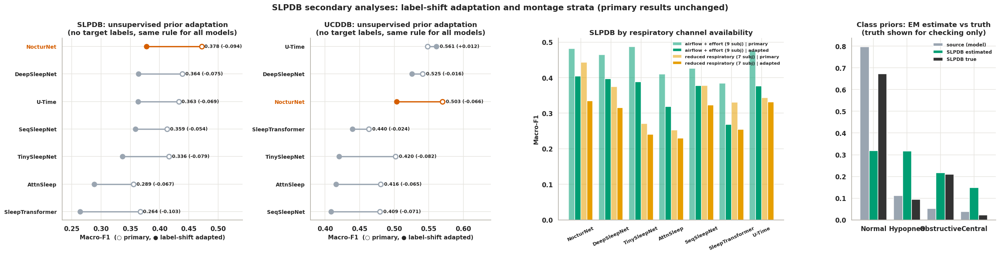

In [23]:
# ===================== STAGE 18b  =====================


def post_T(prob, bias): return softmax_np(np.log(np.clip(prob, 1e-8, 1)) - bias)
def em_prior(p, pi_s, iters=200, tol=1e-6):
    pi = pi_s.copy()
    for _ in range(iters):
        q = p * (pi / pi_s); q /= q.sum(1, keepdims=True); new = q.mean(0)
        done = np.abs(new - pi).max() < tol; pi = new
        if done: break
    q = p * (pi / pi_s); return q / q.sum(1, keepdims=True), pi
def adapt(prob_all, cal, prob_target):
    b = cal["bias"]; pi_s = post_T(cal["prob"][IDX["val"]], b).mean(0)
    q, pi_t = em_prior(post_T(prob_target, b), pi_s)
    return softmax_np(np.log(np.clip(q, 1e-8, 1)) + b), pi_s, pi_t

ADA2, ADA_EXT, rows, PRI = {}, {}, [], {}
for (n, sd), p in PR2.items():
    cal = np.load(os.path.join(DIRS["results"], f"pred_{TAG(n, None if sd == CFG['seed'] else sd)}.npz"))
    a2 = np.full_like(p, np.nan); a2[V2], pi_s, pi_t = adapt(None, cal, p[V2]); ADA2[(n, sd)] = a2
    if n == PROPOSED and sd == CFG["seed"]: PRI = dict(source=pi_s, slpdb_est=pi_t, slpdb_true=np.bincount(Y2[V2], minlength=4) / len(V2))
    for part, y_, pp, pa in [("SLPDB", Y2[V2], p[V2], a2[V2])] + [
            (lab, Y[IDX[k]], cal["prob"][IDX[k]], adapt(None, cal, cal["prob"][IDX[k]])[0]) for k, lab in [("external", "UCDDB"), ("test", "Internal")]]:
        rows.append(dict(model=n, seed=sd, cohort=part, F1_primary=f1_score(y_, pp.argmax(1), average="macro"),
                         F1_adapted=f1_score(y_, pa.argmax(1), average="macro"), Acc_primary=accuracy_score(y_, pp.argmax(1)),
                         Acc_adapted=accuracy_score(y_, pa.argmax(1)), Kappa_adapted=cohen_kappa_score(y_, pa.argmax(1))))
ADA = pd.DataFrame(rows); ADA["dF1_adapt"] = ADA.F1_adapted - ADA.F1_primary
ADA.to_csv(os.path.join(SLP_RES, "label_shift_adaptation_all.csv"), index=False)
A42 = ADA[ADA.seed == CFG["seed"]].pivot(index="model", columns="cohort", values=["F1_primary", "F1_adapted"]).round(4)
print("Macro-F1 before / after unsupervised label-shift adaptation (seed 42):"); display(A42)
AS = ADA[ADA.model.isin(SEEDED)].groupby(["cohort", "model"])[["F1_primary", "F1_adapted"]].agg(["mean", "std"]).round(4)
AS.to_csv(os.path.join(SLP_RES, "label_shift_adaptation_seeds.csv")); display(AS)
print("Class priors (Normal, Hypopnea, Obstructive, Central) for NocturNet: source", np.round(PRI["source"], 3),
      "| SLPDB estimated", np.round(PRI["slpdb_est"], 3), "| SLPDB true", np.round(PRI["slpdb_true"], 3))

base = [n for n in SLP_MODELS if MODELS[n][0] in ("Proposed", "Baseline") and (n, CFG["seed"]) in PR2]
PA2 = ADA2[(PROPOSED, CFG["seed"])]; rows = {}
for n in base:
    if n == PROPOSED: continue
    mu, lo, hi = dboot2(PA2, ADA2[(n, CFG["seed"])]); a_, b_ = subj2(PA2), subj2(ADA2[(n, CFG["seed"])])
    rows[n] = dict(dF1=mu, dF1_lo=lo, dF1_hi=hi, Wilcoxon_p=stats.wilcoxon(a_, b_).pvalue if np.any(a_ != b_) else 1.0)
DA = pd.DataFrame(rows).T; DA.to_csv(os.path.join(SLP_RES, "adapted_delta_slpdb.csv")); print("\nNocturNet minus baseline on SLPDB after adaptation:"); display(DA.round(4))

resp_full = (SLP_META.Airflow == 1) & ((SLP_META.Thorax == 1) | (SLP_META.Abdomen == 1))
STRATA = {"airflow + effort": SLP_META.index[resp_full].tolist(), "reduced respiratory": SLP_META.index[~resp_full].tolist()}
rows = []
for sname, recs in STRATA.items():
    ii = V2[np.isin(REC2[V2], recs)]
    if not len(ii): continue
    for n in base:
        for kind, P_ in [("primary", PR2[(n, CFG["seed"])]), ("adapted", ADA2[(n, CFG["seed"])])]:
            rows.append(dict(stratum=f"{sname} ({len(set(SUBJ2[ii]))} subj)", model=n, kind=kind, MacroF1=f1_score(Y2[ii], P_[ii].argmax(1), average="macro"),
                             Accuracy=accuracy_score(Y2[ii], P_[ii].argmax(1)), epochs=len(ii)))
STR = pd.DataFrame(rows); STR.to_csv(os.path.join(SLP_RES, "channel_strata_slpdb.csv"), index=False)
display(STR[STR.kind == "primary"].pivot(index="model", columns="stratum", values="MacroF1").round(4))
print("SpO2 available in", int(SLP_META.SpO2.sum()), "of", len(SLP_META), "SLPDB records")

# ---- figure
fig, axs = plt.subplots(1, 4, figsize=(24, 6.2), gridspec_kw={"width_ratios": [1, 1, 1.25, .8]})
for ax, coh in zip(axs[:2], ["SLPDB", "UCDDB"]):
    d = ADA[(ADA.seed == CFG["seed"]) & (ADA.cohort == coh) & ADA.model.isin(base)].sort_values("F1_adapted")
    for i, r in enumerate(d.itertuples()):
        c = "#D55E00" if r.model == PROPOSED else "#9AA5B1"
        ax.plot([r.F1_primary, r.F1_adapted], [i, i], color=c, lw=2.2); ax.scatter(r.F1_primary, i, s=60, color="white", edgecolor=c, lw=2, zorder=3)
        ax.scatter(r.F1_adapted, i, s=70, color=c, zorder=3); ax.text(max(r.F1_primary, r.F1_adapted) + .005, i, f"{r.F1_adapted:.3f} ({r.dF1_adapt:+.3f})", va="center", fontsize=8)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d.model, fontsize=9); ax.set_xlabel("Macro-F1  (○ primary, ● label-shift adapted)")
    ax.set_xlim(d[["F1_primary", "F1_adapted"]].values.min() - .03, d[["F1_primary", "F1_adapted"]].values.max() + .07)
    ax.set_title(f"{coh}: unsupervised prior adaptation\n(no target labels, same rule for all models)")
    for t in ax.get_yticklabels():
        if t.get_text() == PROPOSED: t.set_fontweight("bold"); t.set_color("#D55E00")
ax = axs[2]; sp = STR.pivot_table(index="model", columns=["stratum", "kind"], values="MacroF1").reindex(base)
sp = sp[[(a, k) for a in sp.columns.levels[0] for k in ("primary", "adapted") if (a, k) in sp.columns]]
xs = np.arange(len(base)); w = .2; cols = {"primary": .55, "adapted": 1.0}
for j, (st_, kd) in enumerate(sp.columns):
    c = DBPAL["SLPDB"] if st_.startswith("airflow") else "#E69F00"
    ax.bar(xs + (j - 1.5) * w, sp[(st_, kd)], w, color=c, alpha=cols[kd], edgecolor="white", label=f"{st_} | {kd}")
ax.set_xticks(xs); ax.set_xticklabels(base, rotation=25, fontsize=8.5); ax.set_ylabel("Macro-F1"); ax.legend(frameon=False, fontsize=7.5)
ax.set_title("SLPDB by respiratory channel availability")
ax = axs[3]; pr = pd.DataFrame({"source (model)": PRI["source"], "SLPDB estimated": PRI["slpdb_est"], "SLPDB true": PRI["slpdb_true"]}, index=CFG["classes"])
pr.plot(kind="bar", ax=ax, color=["#9AA5B1", DBPAL["SLPDB"], "#333333"], edgecolor="white", width=.8); ax.tick_params(axis="x", rotation=0)
ax.set_title("Class priors: EM estimate vs truth\n(truth shown for checking only)"); ax.legend(frameon=False, fontsize=8)
fig.suptitle("SLPDB secondary analyses: label-shift adaptation and montage strata (primary results unchanged)", fontsize=14, fontweight="bold")
plt.tight_layout(); savefig(fig, "18b_slpdb_secondary"); set_flag("stage18b_slpdb_secondary")

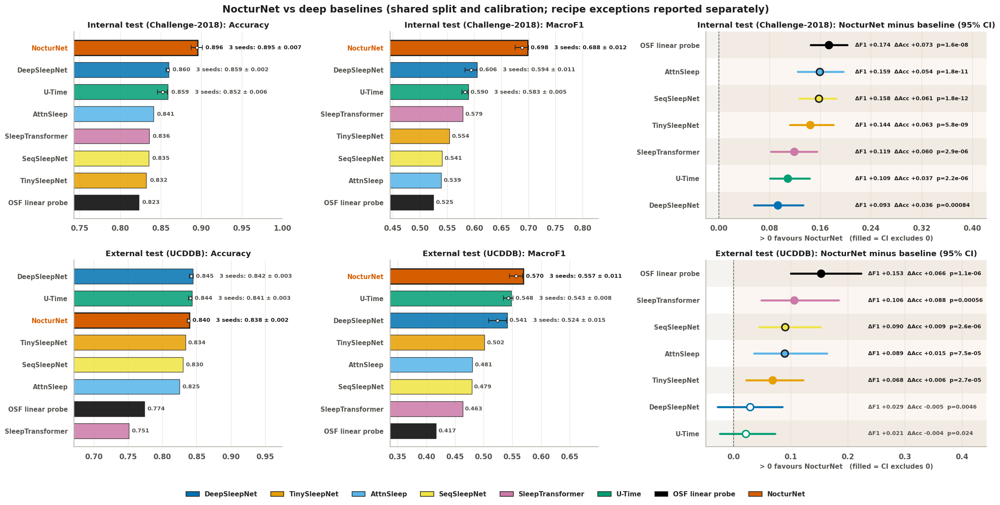

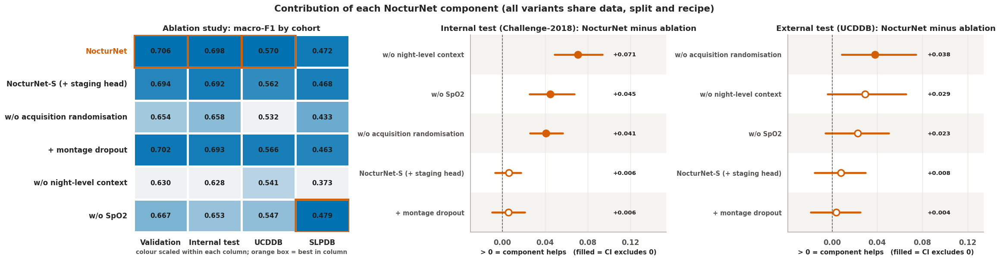

In [24]:
# ===================== STAGE 19  =====================
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Rectangle, Patch
TB = {p: pd.read_csv(os.path.join(DIRS["results"], f"comparison_{p}.csv"), index_col=0) for p in ["test", "external"]}
SD = pd.read_csv(os.path.join(DIRS["results"], "seed_runs.csv"))
PLAB = {"test": "Internal test (Challenge-2018)", "external": "External test (UCDDB)"}
gc = {"Proposed": "#D55E00", "Baseline": "#9AA5B1", "Ablation": "#0072B2"}
MCOL = {"DeepSleepNet": "#0072B2", "TinySleepNet": "#E69F00", "AttnSleep": "#56B4E9", "SeqSleepNet": "#F0E442",
        "SleepTransformer": "#CC79A7", "U-Time": "#009E73", "OSF linear probe": "#000000", PROPOSED: "#D55E00"}
plt.rcParams.update({"font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold"})
INK, INK2, GRID = "#1f1f1f", "#55534f", "#e6e4df"
def _style(ax):
    ax.grid(axis="x", color=GRID, lw=.8); ax.grid(axis="y", visible=False); ax.set_axisbelow(True)
    for sp in ["left", "bottom"]: ax.spines[sp].set_color("#b9b6ae")
    ax.tick_params(colors=INK2)

fig, axs = plt.subplots(2, 3, figsize=(21, 10.5), gridspec_kw={"width_ratios": [1, 1, 1.35]})
for row, part in enumerate(["test", "external"]):
    T = TB[part]; B = T[T.Group.isin(["Proposed", "Baseline"])]
    for col, met in enumerate(["Accuracy", "MacroF1"]):
        S = B.sort_values(met); ax = axs[row, col]; _style(ax)
        for i, (n, v) in enumerate(S[met].items()):
            isP = n == PROPOSED; c = MCOL.get(n, "#9AA5B1")
            ax.barh(i, v, height=.68, color=c, alpha=1 if isP else .85, edgecolor=INK, lw=1.8 if isP else .9)
            sd = SD[(SD.part == part) & (SD.model == n)][met]
            if len(sd) > 1: ax.errorbar(sd.mean(), i, xerr=sd.std(), fmt="o", ms=4.5, color=INK, mfc="white", capsize=4, lw=1.3, zorder=4)
            lab = f"{v:.3f}" + (f"   3 seeds: {sd.mean():.3f} ± {sd.std():.3f}" if len(sd) > 1 else "")
            ax.text(max(v, sd.mean() + sd.std() if len(sd) > 1 else v) + .004, i, lab, va="center", fontsize=8.5, color=INK if isP else INK2,
                    fontweight="bold")
        ax.set_yticks(range(len(S))); ax.set_yticklabels(S.index)
        ax.set_xlim(max(0, S[met].min() - .08), min(1, S[met].max() + .13)); ax.set_title(f"{PLAB[part]}: {met}", color=INK)
        ax.tick_params(axis="y", labelsize=9.5)
        for t in ax.get_yticklabels():
            if t.get_text() == PROPOSED: t.set_fontweight("bold"); t.set_color("#D55E00")
    D = B.drop(PROPOSED).sort_values("dF1"); ax = axs[row, 2]; _style(ax)
    xr = max(D.dF1_hi.max(), 0) + .22; ax.axvspan(0, xr, color="#D55E00", alpha=.05, lw=0)
    for i, (n, r) in enumerate(D.iterrows()):
        sig = r.dF1_lo > 0 or r.dF1_hi < 0; c = MCOL.get(n, "#9AA5B1")
        if i % 2 == 0: ax.axhspan(i - .5, i + .5, color="#f4f3f0", lw=0, zorder=0)
        ax.plot([r.dF1_lo, r.dF1_hi], [i, i], color=c, lw=3, solid_capstyle="round", zorder=2)
        ax.scatter(r.dF1, i, s=110, color=c if sig else "white", edgecolor=INK if c in ("#F0E442", "#56B4E9") else c, lw=2.2, zorder=3)
        ax.text(max(D.dF1_hi.max(), 0) + .012, i, f"ΔF1 {r.dF1:+.3f}  ΔAcc {r.dAcc:+.3f}  p={r.Wilcoxon_p:.2g}", va="center", fontsize=8.3,
                color=INK if sig else INK2, fontweight="bold")
    ax.axvline(0, color=INK2, ls="--", lw=1); ax.set_yticks(range(len(D))); ax.set_yticklabels(D.index, fontsize=9.5); ax.set_ylim(-.5, len(D) - .5)
    ax.set_xlim(min(D.dF1_lo.min(), 0) - .02, xr); ax.xaxis.set_major_locator(MaxNLocator(6))
    ax.set_title(f"{PLAB[part]}: NocturNet minus baseline (95% CI)", color=INK); ax.set_xlabel("> 0 favours NocturNet   (filled = CI excludes 0)", color=INK2)
fig.legend(handles=[Patch(facecolor=MCOL[n], edgecolor=INK, label=n) for n in MCOL], loc="lower center", ncol=8, frameon=False, prop={"size": 10, "weight": "bold"}, bbox_to_anchor=(.5, -.02))
fig.suptitle("NocturNet vs deep baselines (shared split and calibration; recipe exceptions reported separately)", fontsize=15, fontweight="bold", color=INK)
plt.tight_layout(rect=(0, .03, 1, 1)); savefig(fig, "08_comparison")

AB = [n for n in TB["test"].index if TB["test"].loc[n, "Group"] == "Ablation"]
fig, axs = plt.subplots(1, 3, figsize=(21, 5.6), gridspec_kw={"width_ratios": [1.1, 1, 1]})
tab = pd.DataFrame({"Validation": TB["test"].loc[[PROPOSED] + AB, "Val_F1"], "Internal test": TB["test"].loc[[PROPOSED] + AB, "MacroF1"],
                    "UCDDB": TB["external"].loc[[PROPOSED] + AB, "MacroF1"]})
slp_p = os.path.join(DIRS["results"], "slpdb", "comparison_slpdb.csv")
if os.path.exists(slp_p):
    sl = pd.read_csv(slp_p, index_col=0); tab["SLPDB"] = sl.reindex(tab.index)["MacroF1"]
tab.to_csv(os.path.join(DIRS["results"], "ablation_summary.csv"))
tz = (tab - tab.min()) / (tab.max() - tab.min()).replace(0, 1)
sns.heatmap(tz, annot=tab.values, fmt=".3f", cmap=sns.light_palette("#0072B2", as_cmap=True), ax=axs[0], cbar=False, linewidths=2, linecolor="white",
            annot_kws={"color": INK, "fontsize": 10, "fontweight": "bold"})
for j, c_ in enumerate(tab.columns):
    i = int(np.nanargmax(tab[c_].values)); axs[0].add_patch(Rectangle((j, i), 1, 1, fill=False, ec="#D55E00", lw=3))
axs[0].set_xlabel("colour scaled within each column; orange box = best in column", color=INK2, fontsize=9); axs[0].set_title("Ablation study: macro-F1 by cohort")
for t in axs[0].get_yticklabels():
    if t.get_text() == PROPOSED: t.set_fontweight("bold"); t.set_color("#D55E00")
for ax, part in zip(axs[1:], ["test", "external"]):
    D = TB[part].loc[AB].sort_values("dF1"); _style(ax)
    for i, (n, r) in enumerate(D.iterrows()):
        sig = r.dF1_lo > 0 or r.dF1_hi < 0; c = "#D55E00" if r.dF1 > 0 else "#0072B2"
        if i % 2 == 0: ax.axhspan(i - .5, i + .5, color="#f4f3f0", lw=0, zorder=0)
        ax.plot([r.dF1_lo, r.dF1_hi], [i, i], color=c, lw=3, solid_capstyle="round"); ax.scatter(r.dF1, i, s=95, color=c if sig else "white", edgecolor=c, lw=2.2, zorder=3)
        ax.text(max(D.dF1_hi.max(), 0) + .01, i, f"{r.dF1:+.3f}", va="center", fontsize=8.8, color=INK)
    ax.axvline(0, color=INK2, ls="--", lw=1); ax.set_yticks(range(len(D))); ax.set_yticklabels(D.index, fontsize=9.5); ax.set_ylim(-.5, len(D) - .5)
    ax.set_xlim(min(D.dF1_lo.min(), 0) - .02, max(D.dF1_hi.max(), 0) + .06); ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.set_title(f"{PLAB[part]}: NocturNet minus ablation"); ax.set_xlabel("> 0 = component helps   (filled = CI excludes 0)")
fig.suptitle("Contribution of each NocturNet component (all variants share data, split and recipe)", fontsize=14, fontweight="bold")
plt.tight_layout(); savefig(fig, "08b_ablation")

,cohort,model,subjects,epochs,macro_f1,accuracy,rank
3,SLPDB,NocturNet,16,10185,0.4717,0.6806,1
5,SLPDB,DeepSleepNet,16,10185,0.4390,0.6665,2
4,SLPDB,U-Time,16,10185,0.4327,0.6674,3
0,UCDDB,NocturNet,25,20793,0.5697,0.8396,1
1,UCDDB,U-Time,25,20793,0.5483,0.8435,2
2,UCDDB,DeepSleepNet,25,20793,0.5411,0.8449,3


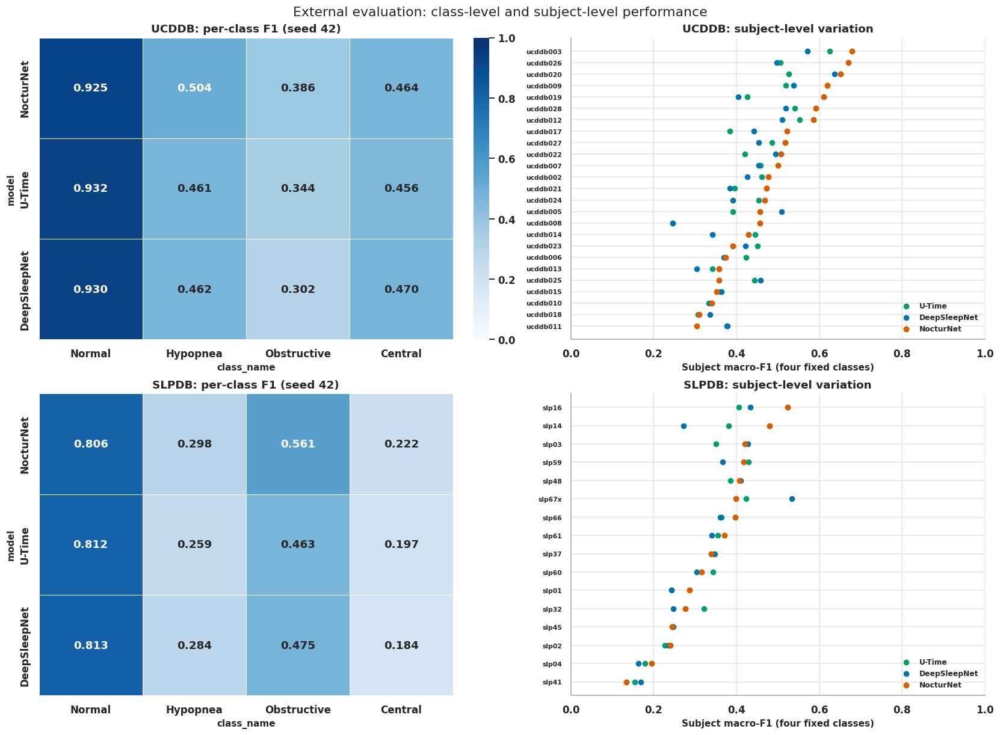

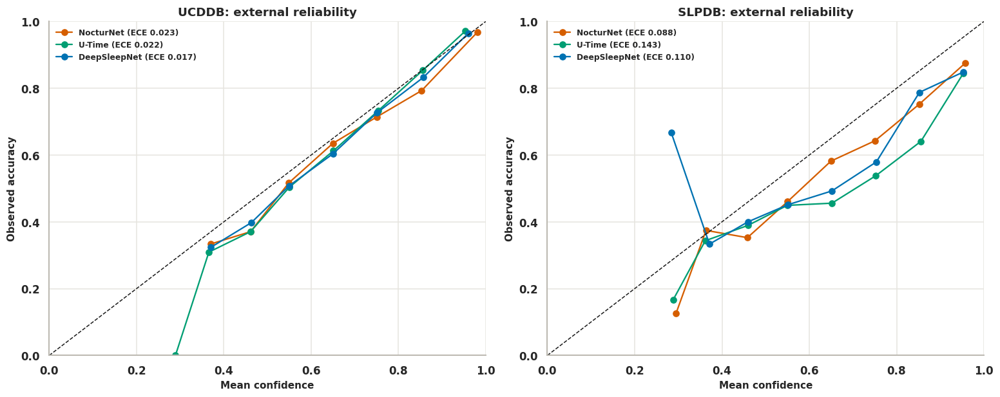

In [25]:
# ===================== STAGE 19b: EXTERNAL EVALUATION AUDIT =====================
# Run after Stages 18 and 19. All displays use existing, frozen predictions.
# No external labels are used for training, calibration, or model selection.
from pathlib import Path

external_models = [PROPOSED, "U-Time", "DeepSleepNet"]
external_sets = {
    "UCDDB": (IDX["external"], Y, REC, {n: PROBS[n] for n in external_models}),
    "SLPDB": (V2, Y2, SUBJ2, {n: PR2[(n, CFG["seed"])] for n in external_models}),
}
audit_rows, subject_rows, class_rows = [], [], []
for cohort, (ii, yy, subjects, probs) in external_sets.items():
    if not np.isfinite(np.stack([probs[n][ii] for n in external_models])).all():
        raise ValueError(f"Non-finite probabilities in {cohort}")
    for n in external_models:
        pred = probs[n][ii].argmax(1)
        f = f1_score(yy[ii], pred, labels=range(4), average="macro", zero_division=0)
        audit_rows.append(dict(cohort=cohort, model=n, subjects=len(np.unique(subjects[ii])),
                               epochs=len(ii), macro_f1=f, accuracy=accuracy_score(yy[ii], pred)))
        per = f1_score(yy[ii], pred, labels=range(4), average=None, zero_division=0)
        for k, cls in enumerate(CFG["classes"]):
            class_rows.append(dict(cohort=cohort, model=n, class_name=cls,
                                   support=int((yy[ii] == k).sum()), f1=float(per[k])))
        for sid in np.unique(subjects[ii]):
            si = ii[subjects[ii] == sid]
            subject_rows.append(dict(cohort=cohort, model=n, subject=str(sid), epochs=len(si),
                                     macro_f1=f1_score(yy[si], probs[n][si].argmax(1), labels=range(4),
                                                       average="macro", zero_division=0)))

audit_df = pd.DataFrame(audit_rows)
subject_df = pd.DataFrame(subject_rows)
class_df = pd.DataFrame(class_rows)
# The audit records actual ranks and does not force a proposed-model win.
audit_df["rank"] = audit_df.groupby("cohort")["macro_f1"].rank(ascending=False, method="min").astype(int)
for cohort in external_sets:
    d = audit_df[audit_df.cohort == cohort].set_index("model")
    for baseline in external_models[1:]:
        expected = d.loc[PROPOSED, "macro_f1"] - d.loc[baseline, "macro_f1"]
        reported = (TABS["external"] if cohort == "UCDDB" else num2).loc[baseline, "dF1"]
        np.testing.assert_allclose(reported, expected, atol=1e-12,
                                   err_msg=f"{cohort}: difference mismatch for {baseline}")

out_dir = Path(DIRS["results"]) / "external_audit"
out_dir.mkdir(parents=True, exist_ok=True)
audit_df.to_csv(out_dir / "external_summary.csv", index=False)
subject_df.to_csv(out_dir / "subject_macro_f1.csv", index=False)
class_df.to_csv(out_dir / "class_f1.csv", index=False)
display(audit_df.sort_values(["cohort", "rank"]).round(4))

fig, axs = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)
for row, cohort in enumerate(["UCDDB", "SLPDB"]):
    c = class_df[class_df.cohort == cohort].pivot(index="model", columns="class_name", values="f1")
    c = c.reindex(index=external_models, columns=CFG["classes"])
    sns.heatmap(c, annot=True, fmt=".3f", vmin=0, vmax=1, cmap="Blues", ax=axs[row, 0],
                cbar=row == 0, linewidths=.5, linecolor="white")
    axs[row, 0].set_title(f"{cohort}: per-class F1 (seed {CFG['seed']})")
    s = subject_df[subject_df.cohort == cohort].pivot(index="subject", columns="model", values="macro_f1")
    s = s.sort_values(PROPOSED)
    yloc = np.arange(len(s))
    axs[row, 1].scatter(s["U-Time"], yloc, s=28, color="#009E73", label="U-Time")
    axs[row, 1].scatter(s["DeepSleepNet"], yloc, s=28, color="#0072B2", label="DeepSleepNet")
    axs[row, 1].scatter(s[PROPOSED], yloc, s=30, color="#D55E00", label=PROPOSED)
    axs[row, 1].set_yticks(yloc)
    axs[row, 1].set_yticklabels(s.index, fontsize=7)
    axs[row, 1].set_xlim(0, 1)
    axs[row, 1].set_xlabel("Subject macro-F1 (four fixed classes)")
    axs[row, 1].set_title(f"{cohort}: subject-level variation")
    axs[row, 1].legend(fontsize=8, loc="lower right")
fig.suptitle("External evaluation: class-level and subject-level performance")
savefig(fig, "19b_external_class_subject")

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
for ax, cohort in zip(axs, ["UCDDB", "SLPDB"]):
    ii, yy, subjects, probs = external_sets[cohort]
    for n, color in [(PROPOSED, "#D55E00"), ("U-Time", "#009E73"), ("DeepSleepNet", "#0072B2")]:
        p = probs[n][ii]
        confidence, correct = p.max(1), p.argmax(1) == yy[ii]
        bins = np.linspace(0, 1, 11)
        x, y, counts = [], [], []
        for lo, hi in zip(bins[:-1], bins[1:]):
            keep = (confidence >= lo) & (confidence < hi if hi < 1 else confidence <= hi)
            if keep.any():
                x.append(confidence[keep].mean()); y.append(correct[keep].mean()); counts.append(keep.sum())
        ece = np.average(np.abs(np.array(x) - np.array(y)), weights=counts)
        ax.plot(x, y, marker="o", color=color, label=f"{n} (ECE {ece:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean confidence", ylabel="Observed accuracy",
           title=f"{cohort}: external reliability")
    ax.legend(fontsize=8)
savefig(fig, "19c_external_reliability")
set_flag("stage19b_external_audit")


In [28]:
for sub_ in ["results", "figures"]: shutil.make_archive(os.path.join(BASE, f"NocturNet_{sub_}"), "zip", BASE, sub_)
print("Figures:", len(glob.glob(os.path.join(DIRS["figures"], "*.png"))), "| archives in", BASE); set_flag("final_archive")

Figures: 37 | archives in /content/drive/MyDrive/NocturNet
